### AAI-520 - NLP and GenAI
### Group 4 - Final Group Project
### Lashana Narayan, Nik, Nathan

# Multi-Agent Investment Research Agent

**Goal:** Given a stock symbol, an autonomous agent gathers current market, company, news and economic data. Specialist agents interpret that data, and the agent produces an evidence-backed research report that helps an investor make an informed decision. The agent also checks the quality of its own work, improves weak reports, and learns from previous runs.

**What the report contains:** company overview and fundamentals · recent price performance and technical signals · news themes and sentiment · macro and economic context (Economic Agent) · material risks, caveats and reconciled conflicting signals · agent confidence and quality score · source list with data timestamps.

**How the project requirements map to this notebook**

| Requirement | Where |
|---|---|
| Agent functions: plan, use tools dynamically, self-reflect, learn across runs | Section 4 |
| Workflow patterns: prompt chaining, routing, evaluator-optimizer | Section 5 |
| Visualizations | Sections 7, 8 and 9 |
| Evaluation of the system | Section 9 |

**Notebook outline**

1. Setup: libraries and API configuration
2. Data Collection Layer: Yahoo Finance, NewsAPI, FRED collectors
3. Specialist Agents & Coordinator: rule-based Fundamental, Technical, Sentiment and Risk agents, plus the first report
4. Autonomous Agent Functions: memory, tools, planner, self-reflection, Economic Agent
5. Workflow Patterns: prompt chain, content router, evaluator-optimizer
6. The Autonomous Investment Research Agent: everything combined in one `run()`
7. Visualizations: chart functions
8. Demonstration: full run, learning across runs, multi-stock comparison
9. System Evaluation: agent validation tests, performance metrics, sentiment accuracy
10. Key Findings
11. Requirements Checklist & Limitations

**How to run:** run all cells top to bottom in Databricks. Section 3.8 asks for a stock symbol, and Sections 8–9 analyze that symbol.

**GitHub repository:** https://github.com/Sublymonal/AAI520_Group_4

> This notebook is for research and education only. It is not investment advice.

## Project Scope: Data Needed for an Investment Decision

Before building the agents we listed the information an investor would want. The table shows which items the current system **implements** and which remain **future work**.

| Category | Implemented in this notebook | Future work |
|---|---|---|
| **1. Fundamental** (Fundamental Agent) | P/E, P/B, P/S · ROE, ROA · profit and operating margin · current and quick ratio · debt-to-equity · revenue and earnings growth · free cash flow · dividend yield and payout · market cap, enterprise value, float · company profile and business summary | EV/EBITDA, PEG, gross margin · efficiency ratios (asset/inventory turnover) · insider ownership · management and moat assessment |
| **2. Technical** (Technical Agent) | Daily OHLCV · volume vs. 20-day average · SMA 20/50/200, EMA 20/50 · RSI (14) · trend classification · 52-week high/low · 1D/1W/1M/3M returns | MACD, stochastic, Bollinger Bands, ATR, VWAP, OBV · support/resistance and chart-pattern detection |
| **3. News & Sentiment** (Sentiment Agent + prompt chain) | Recent headlines (NewsAPI + Yahoo Finance news) · TextBlob sentiment (positive/neutral/negative) · event and theme detection (earnings, analyst ratings, product, M&A, legal/regulatory, management, macro) · key figures and entities | Finance-tuned sentiment model (e.g., FinBERT) · social media sentiment |
| **4. Risk** (Risk Agent + risk section) | Annualized historical volatility · beta vs. S&P 500 · risks combined from all agents (valuation, leverage, momentum, macro, news events) | Implied volatility · Value at Risk · Sharpe ratio · liquidity and credit risk |
| **5. Economic** (Economic Agent) | Fed funds rate · 3M and 10Y Treasury and the yield curve · CPI inflation (YoY) · real GDP growth · unemployment · S&P 500 · 6-month trends, equity headwind/tailwind regime, sector tilt | PPI · consumer and business sentiment · currency and commodity prices |
| **6. Competitive & Industry** | Sector-specific focus metrics · multi-stock comparison (volatility, beta, P/E) | Industry growth rates · market share · peer-relative valuation |

---
## 1 - Setup: Libraries and API Configuration

The cells in this section prepare the environment:

1. **Install** the third-party libraries: `yfinance` (Yahoo Finance prices, fundamentals and news), `pandas-datareader`, `textblob` (sentiment), `pandas-ta`, `requests` (NewsAPI and FRED REST calls), `numpy`, `scipy` and `matplotlib` (charts).
2. **Restart Python** so Databricks picks up the newly installed packages.
3. **Import** the libraries used throughout the notebook.
4. **`APIConfig`** holds the API keys, endpoints and rate limits in one place and creates the `investment_data/` folders where every collector and agent saves its JSON output.
5. **Set the API keys** for FRED and NewsAPI. Yahoo Finance needs no key.

In [0]:
# In Databricks notebook cell
%pip install yfinance pandas-datareader textblob pandas-ta requests numpy scipy matplotlib

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

In [0]:
# Core data APIs
import yfinance as yf
import pandas_datareader as pdr  # For FRED
import requests  # For NewsAPI

# Technical analysis
import pandas as pd
import numpy as np
# Optional: ta-lib or pandas-ta for advanced indicators
import pandas_ta as ta  # Technical analysis indicators (RSI, MACD, etc.)

# Sentiment analysis
from textblob import TextBlob  # Basic sentiment

# Optional: Advanced Sentiment Analysis
# transformers>=4.21.0    # For advanced NLP (heavy install)
# torch>=1.12.0          # Required for transformers

# Technical Analysis (Optional - choose one)
# pandas-ta>=0.3.14b        # Pure Python, easier to install (installed via %pip in setup cell)

# Data Manipulation and Storage
# scipy>=1.10.0

# Development and Testing
# pytest>=7.0.0            # For unit testing
# jupyter>=1.0.0           # For data analysis notebooks

import json
import os
import time
import warnings
from datetime import datetime, timedelta
from textblob import TextBlob
import pandas_datareader as pdr

warnings.filterwarnings('ignore')
print("✅ All imports loaded successfully!")

✅ All imports loaded successfully!


In [0]:
class APIConfig:
    """Configuration class for all API keys and endpoints"""

    def __init__(self):
        # API Keys - SET THESE IN YOUR ENVIRONMENT VARIABLES
        self.fred_api_key = os.getenv('FRED_API_KEY')  # GET FROM: https://fred.stlouisfed.org/docs/api/api_key.html
        self.news_api_key = os.getenv('NEWS_API_KEY')  # GET FROM: https://newsapi.org/register

        # API Endpoints
        self.news_base_url = "https://newsapi.org/v2"
        self.fred_base_url = "https://api.stlouisfed.org/fred"

        # Rate Limiting (requests per minute)
        self.news_rate_limit = 60  # NewsAPI: 1000/day = ~41/hour = ~0.7/minute (be conservative)
        self.fred_rate_limit = 120  # FRED: 120/minute

        # Data storage settings
        self.data_directory = "investment_data"
        self.create_data_directory()

    def create_data_directory(self):
        """Create directory for storing collected data"""
        if not os.path.exists(self.data_directory):
            os.makedirs(self.data_directory)
            os.makedirs(f"{self.data_directory}/stocks")
            os.makedirs(f"{self.data_directory}/news")
            os.makedirs(f"{self.data_directory}/economic")

#### API keys

Free keys are obtained from [FRED](https://fred.stlouisfed.org/docs/api/api_key.html) and [NewsAPI](https://newsapi.org/register).


In [0]:
# In first cell of your notebook
import os

# Set API keys (NOT recommended for production)
os.environ['FRED_API_KEY'] = '[ran with key, then redacted]'
os.environ['NEWS_API_KEY'] = '[ran with key, then redacted]'

# Verify they're set
print("FRED API Key:", "✅ Set" if os.environ.get('FRED_API_KEY') else "❌ Missing")
print("News API Key:", "✅ Set" if os.environ.get('NEWS_API_KEY') else "❌ Missing")

FRED API Key: ✅ Set
News API Key: ✅ Set


---
## 2 - Data Collection Layer

This layer retrieves raw data from external APIs and returns it as structured Python dictionaries, also saved as JSON in `investment_data/`. It contains **no analysis logic**. Interpretation is left to the agents in Sections 3–6, so collectors and agents can change independently.

| Collector | Source | Data |
|---|---|---|
| `FundamentalDataCollector` | Yahoo Finance | valuation, profitability, liquidity, leverage, growth, dividends, free cash flow |
| `TechnicalDataCollector` | Yahoo Finance | 1-year prices, moving averages, RSI, volatility, beta, returns, 52-week range |
| `NewsDataCollector` | NewsAPI + TextBlob | recent headlines with sentiment polarity and labels |
| `EconomicDataCollector` | FRED | rates, inflation, growth, employment, S&P 500, each with its 6-month change |
| `InvestmentResearchPlatform` | (orchestrator) | runs the collectors for one or more symbols and saves the results |

### System Architecture

The notebook builds the system in layers. Each layer consumes only the structured output of the one below it:

```
 Layer 1  DATA COLLECTION (Section 2)      Yahoo Finance · NewsAPI · FRED  ->  structured dicts + JSON
             │
 Layer 2  SPECIALIST AGENTS (Sections 3, 4.5)
             Fundamental · Technical · Sentiment · Risk · Economic   (uniform analyze(data) -> dict)
             Coordinator routes each data partition to the right agent and aggregates the results
             │
 Layer 3  AUTONOMOUS AGENT (Sections 4-6)
             Plan -> use tools -> prompt-chain the news -> route content -> self-reflect
             -> evaluate -> optimize -> report -> learn (memory)
             │
 Layer 4  OUTPUT & EVALUATION (Sections 7-9)
             research report · charts · validation tests · performance metrics · sentiment accuracy
```

Sections 2–3 are the original static pipeline: collect data, then run each agent once in a fixed order. Sections 4–6 turn it into an **autonomous agent** that decides which tools to use, checks its own output, and improves over time.

### 2.1 Fundamental Data Collector

Reads `yf.Ticker(symbol).info` and the cash flow statement. It returns:

* **Valuation:** trailing P/E, price-to-book, price-to-sales
* **Profitability:** profit and operating margin, ROE, ROA
* **Financial health:** current ratio, quick ratio, debt-to-equity (Yahoo reports D/E as a percentage, e.g., 78 = 0.78×)
* **Growth:** revenue and earnings growth (YoY)
* **Size and dividends:** market cap, enterprise value, shares outstanding, float, dividend yield, payout ratio
* **Free cash flow:** operating cash flow − capital expenditure, from the cash flow statement

Missing fields are returned as `None`, never guessed, so downstream agents can report "unavailable" and lower their confidence.

In [0]:
from typing import Dict
import json
from datetime import datetime

class FundamentalDataCollector:
    """Collects fundamental analysis data using Yahoo Finance API"""

    def __init__(self):
        self.data = {}

    def get_stock_fundamentals(self, symbol: str) -> Dict:
        """
        Collect HIGH priority fundamental data for a stock
        Returns: Dictionary with all fundamental metrics
        """
        try:
            stock = yf.Ticker(symbol)
            info = stock.info

            # Financial Health Metrics (HIGH PRIORITY)
            fundamentals = {
                'symbol': symbol,
                'timestamp': datetime.now().isoformat(),

                # Valuation Ratios
                'pe_ratio': info.get('trailingPE'),
                'pb_ratio': info.get('priceToBook'),
                'ps_ratio': info.get('priceToSalesTrailing12Months'),

                # Profitability Metrics
                'profit_margin': info.get('profitMargins'),
                'operating_margin': info.get('operatingMargins'),
                'roe': info.get('returnOnEquity'),
                'roa': info.get('returnOnAssets'),

                # Financial Health
                'current_ratio': info.get('currentRatio'),
                'debt_to_equity': info.get('debtToEquity'),
                'quick_ratio': info.get('quickRatio'),

                # Growth Metrics
                'revenue_growth': info.get('revenueGrowth'),
                'earnings_growth': info.get('earningsGrowth'),

                # Company Info
                'market_cap': info.get('marketCap'),
                'enterprise_value': info.get('enterpriseValue'),
                'shares_outstanding': info.get('sharesOutstanding'),
                'float_shares': info.get('floatShares'),

                # Dividend Info
                'dividend_yield': info.get('dividendYield'),
                'payout_ratio': info.get('payoutRatio'),
            }

            # Get Financial Statements for additional calculations
            try:
                financials = stock.financials
                balance_sheet = stock.balance_sheet

                if not financials.empty and not balance_sheet.empty:
                    # Calculate additional metrics from statements
                    latest_financials = financials.iloc[:, 0]  # Most recent year
                    latest_balance = balance_sheet.iloc[:, 0]

                    # Free Cash Flow = operating cash flow - capex (from the cash flow statement)
                    latest_cashflow = stock.cashflow.iloc[:, 0]
                    operating_cf = latest_cashflow.get('Operating Cash Flow', 0)
                    capex = latest_cashflow.get('Capital Expenditure', 0)
                    fundamentals['free_cash_flow'] = operating_cf - abs(capex)

            except Exception as e:
                print(f"Could not fetch detailed financials for {symbol}: {e}")

            return fundamentals

        except Exception as e:
            print(f"Error fetching fundamentals for {symbol}: {e}")
            return {'symbol': symbol, 'error': str(e)}

    def save_fundamentals(self, symbol: str, data: Dict, config: APIConfig):
        """Save fundamental data to JSON file"""
        filename = f"{config.data_directory}/stocks/{symbol}_fundamentals.json"
        with open(filename, 'w') as f:
            json.dump(data, f, indent=2, default=str)
        print(f"✓ Saved fundamental data for {symbol}")

### 2.2 Technical Data Collector

Downloads 1 year of daily prices and computes:

| Indicator | Calculation |
|---|---|
| SMA 20/50/200, EMA 20/50 | rolling and exponential means of the close |
| RSI (14) | 100 − 100 / (1 + avg gain / avg loss) over 14 days |
| Volatility | standard deviation of daily returns × √252 (annualized) |
| Beta | cov(stock, S&P 500) / var(S&P 500) on daily returns |
| 52-week high/low | max/min close over the 1-year window |
| Returns | 1-day, 1-week, 1-month, 3-month price change |
| Volume | latest volume and its 20-day average |

In [0]:
class TechnicalDataCollector:
    """Collects technical analysis data and calculates indicators"""

    def __init__(self):
        self.data = {}

    def get_price_data(self, symbol: str, period: str = "1y") -> pd.DataFrame:
        """Get OHLCV data from Yahoo Finance"""
        try:
            stock = yf.Ticker(symbol)
            history = stock.history(period=period)
            return history
        except Exception as e:
            print(f"Error fetching price data for {symbol}: {e}")
            return pd.DataFrame()

    def calculate_moving_averages(self, prices: pd.Series) -> Dict:
        """Calculate 20, 50, 200-day moving averages"""
        return {
            'sma_20': prices.rolling(window=20).mean().iloc[-1],
            'sma_50': prices.rolling(window=50).mean().iloc[-1],
            'sma_200': prices.rolling(window=200).mean().iloc[-1],
            'ema_20': prices.ewm(span=20).mean().iloc[-1],
            'ema_50': prices.ewm(span=50).mean().iloc[-1],
        }

    def calculate_rsi(self, prices: pd.Series, window: int = 14) -> float:
        """Calculate Relative Strength Index"""
        delta = prices.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi.iloc[-1]

    def calculate_volatility(self, prices: pd.Series) -> float:
        """Calculate annualized historical volatility"""
        returns = prices.pct_change().dropna()
        return returns.std() * np.sqrt(252)  # Annualized

    def calculate_beta(self, stock_prices: pd.Series, market_prices: pd.Series) -> float:
        """Calculate beta against market (S&P 500)"""
        try:
            stock_returns = stock_prices.pct_change().dropna()
            market_returns = market_prices.pct_change().dropna()

            # Align the data
            aligned_data = pd.DataFrame({
                'stock': stock_returns,
                'market': market_returns
            }).dropna()

            covariance = aligned_data.cov().iloc[0, 1]
            market_variance = aligned_data['market'].var()

            return covariance / market_variance if market_variance != 0 else np.nan
        except Exception:
            return np.nan

    def get_technical_analysis(self, symbol: str) -> Dict:
        """Complete technical analysis for a stock"""
        try:
            # Get price data
            price_data = self.get_price_data(symbol, "1y")
            if price_data.empty:
                return {'symbol': symbol, 'error': 'No price data available'}

            close_prices = price_data['Close']
            volume = price_data['Volume']

            # Get S&P 500 data for beta calculation
            sp500 = yf.Ticker("^GSPC")
            sp500_data = sp500.history(period="1y")['Close']

            technical_data = {
                'symbol': symbol,
                'timestamp': datetime.now().isoformat(),
                'current_price': close_prices.iloc[-1],
                'volume_latest': volume.iloc[-1],
                'volume_avg_20d': volume.rolling(window=20).mean().iloc[-1],

                # Moving Averages
                **self.calculate_moving_averages(close_prices),

                # Technical Indicators
                'rsi': self.calculate_rsi(close_prices),
                'volatility': self.calculate_volatility(close_prices),
                'beta': self.calculate_beta(close_prices, sp500_data),

                # Price Levels
                'high_52w': close_prices.max(),
                'low_52w': close_prices.min(),

                # Recent Performance
                'return_1d': (close_prices.iloc[-1] / close_prices.iloc[-2] - 1) if len(close_prices) > 1 else np.nan,
                'return_1w': (close_prices.iloc[-1] / close_prices.iloc[-5] - 1) if len(close_prices) > 5 else np.nan,
                'return_1m': (close_prices.iloc[-1] / close_prices.iloc[-22] - 1) if len(close_prices) > 22 else np.nan,
                'return_3m': (close_prices.iloc[-1] / close_prices.iloc[-66] - 1) if len(close_prices) > 66 else np.nan,
            }

            return technical_data

        except Exception as e:
            print(f"Error in technical analysis for {symbol}: {e}")
            return {'symbol': symbol, 'error': str(e)}

    def save_technical_data(self, symbol: str, data: Dict, config: APIConfig):
        """Save technical data to JSON file"""
        filename = f"{config.data_directory}/stocks/{symbol}_technical.json"
        with open(filename, 'w') as f:
            json.dump(data, f, indent=2, default=str)
        print(f"✓ Saved technical data for {symbol}")

### 2.3 News Data Collector

Queries NewsAPI's `/everything` endpoint for the last 7 days of English articles mentioning the ticker, and keeps the 20 most recent. Each headline + description is scored with **TextBlob**:

* **Polarity** from −1 (negative) to +1 (positive), and **subjectivity** from 0 to 1
* **Label:** positive if polarity > 0.1, negative if < −0.1, neutral otherwise

The collector returns the articles plus the average polarity and the positive/neutral/negative counts. In Section 4 the autonomous agent wraps this collector as a tool, adds the company name to the query, can widen the window up to 30 days, and falls back to Yahoo Finance news.

In [0]:
from typing import Dict, Optional, Tuple
try:
    from typing import List
except ImportError:
    # For older Python versions
    List = list

class NewsDataCollector:
    """Collects news and performs sentiment analysis"""

    def __init__(self, config: APIConfig):
        self.config = config

    def get_stock_news(self, symbol: str, days_back: int = 7) -> List[Dict]:
        """Get recent news for a stock symbol"""
        if not self.config.news_api_key:
            print("❌ NewsAPI key not found. Set NEWS_API_KEY environment variable.")
            return []

        try:
            # Calculate date range
            end_date = datetime.now()
            start_date = end_date - timedelta(days=days_back)

            # NewsAPI parameters
            params = {
                'q': f'"{symbol}" OR "{symbol} stock"',
                'from': start_date.strftime('%Y-%m-%d'),
                'to': end_date.strftime('%Y-%m-%d'),
                'sortBy': 'publishedAt',
                'language': 'en',
                'apiKey': self.config.news_api_key
            }

            response = requests.get(f"{self.config.news_base_url}/everything", params=params)

            if response.status_code == 200:
                articles = response.json().get('articles', [])
                return self.process_articles(articles, symbol)
            else:
                print(f"NewsAPI error: {response.status_code} - {response.text}")
                return []

        except Exception as e:
            print(f"Error fetching news for {symbol}: {str(e).split('?')[0]}")
            return []

    def analyze_sentiment(self, text: str) -> Dict:
        """Analyze sentiment using TextBlob"""
        try:
            blob = TextBlob(text)
            polarity = blob.sentiment.polarity  # -1 (negative) to 1 (positive)
            subjectivity = blob.sentiment.subjectivity  # 0 (objective) to 1 (subjective)

            # Classify sentiment
            if polarity > 0.1:
                sentiment_label = 'positive'
            elif polarity < -0.1:
                sentiment_label = 'negative'
            else:
                sentiment_label = 'neutral'

            return {
                'polarity': polarity,
                'subjectivity': subjectivity,
                'label': sentiment_label
            }
        except Exception:
            return {
                'polarity': 0,
                'subjectivity': 0,
                'label': 'neutral'
            }

    def process_articles(self, articles: List[Dict], symbol: str) -> List[Dict]:
        """Process articles and add sentiment analysis"""
        processed_articles = []

        for article in articles[:20]:  # Limit to 20 most recent articles
            try:
                title = article.get('title', '')
                description = article.get('description', '')
                content = f"{title}. {description}"

                sentiment = self.analyze_sentiment(content)

                processed_article = {
                    'title': title,
                    'description': description,
                    'url': article.get('url', ''),
                    'published_at': article.get('publishedAt', ''),
                    'source': article.get('source', {}).get('name', ''),
                    'sentiment': sentiment
                }

                processed_articles.append(processed_article)

            except Exception as e:
                print(f"Error processing article: {e}")
                continue

        return processed_articles

    def get_news_analysis(self, symbol: str) -> Dict:
        """Complete news and sentiment analysis"""
        articles = self.get_stock_news(symbol)

        if not articles:
            return {
                'symbol': symbol,
                'timestamp': datetime.now().isoformat(),
                'articles_count': 0,
                'average_sentiment': 0,
                'sentiment_distribution': {'positive': 0, 'neutral': 0, 'negative': 0},
                'articles': []
            }

        # Calculate aggregate sentiment metrics
        sentiment_scores = [article['sentiment']['polarity'] for article in articles]
        sentiment_labels = [article['sentiment']['label'] for article in articles]

        sentiment_distribution = {
            'positive': sentiment_labels.count('positive'),
            'neutral': sentiment_labels.count('neutral'),
            'negative': sentiment_labels.count('negative')
        }

        return {
            'symbol': symbol,
            'timestamp': datetime.now().isoformat(),
            'articles_count': len(articles),
            'average_sentiment': np.mean(sentiment_scores) if sentiment_scores else 0,
            'sentiment_distribution': sentiment_distribution,
            'articles': articles
        }

    def save_news_data(self, symbol: str, data: Dict, config: APIConfig):
        """Save news data to JSON file"""
        filename = f"{config.data_directory}/news/{symbol}_news.json"
        with open(filename, 'w') as f:
            json.dump(data, f, indent=2, default=str)
        print(f"✓ Saved news data for {symbol}")

### 2.4 Economic Data Collector

Calls the **FRED REST API** directly. The original `pandas-datareader` call failed because that reader does not accept an `api_key` argument. It requests about 23 months of history for each series:

| Name | FRED series | Meaning |
|---|---|---|
| `federal_funds_rate` | FEDFUNDS | Fed policy rate (%) |
| `treasury_10y` / `treasury_3m` | GS10 / GS3M | 10-year and 3-month Treasury yields (%) – their difference is the yield curve |
| `cpi_inflation` | CPIAUCSL | CPI index; converted to **YoY inflation**, now and 6 months ago |
| `gdp_growth` | A191RL1Q225SBEA | Real GDP growth (% annualized, quarterly) |
| `unemployment` | UNRATE | Unemployment rate (%) |
| `sp500_index` | SP500 | S&P 500 level |

For each series it stores the latest value, the previous value, and the value and **change vs. 6 months ago**. The Economic Agent (Section 4.5) uses these to judge trends. A short pause between calls keeps the collector within FRED's rate limit.

In [0]:
class EconomicDataCollector:
    """Collects economic indicators from FRED API"""

    def __init__(self, config: APIConfig):
        self.config = config

    def get_fred_series(self, series_id: str, start_date: str = None) -> pd.Series:
        """Get a time series from FRED API"""
        if not self.config.fred_api_key:
            print("❌ FRED API key not found. Set FRED_API_KEY environment variable.")
            return pd.Series()

        try:
            if start_date is None:
                # ~23 months so CPI YoY inflation today AND 6 months ago can be computed
                start_date = (datetime.now() - timedelta(days=700)).strftime('%Y-%m-%d')

            # pandas-datareader's FRED reader does not accept an api_key argument,
            # so the FRED REST API is called directly.
            response = requests.get(
                f"{self.config.fred_base_url}/series/observations",
                params={'series_id': series_id, 'api_key': self.config.fred_api_key,
                        'file_type': 'json', 'observation_start': start_date},
                timeout=20,
            )
            response.raise_for_status()
            obs = pd.DataFrame(response.json().get('observations', []))
            if obs.empty:
                return pd.Series(dtype=float)
            values = pd.to_numeric(obs['value'], errors='coerce')  # FRED uses '.' for missing values
            return pd.Series(values.values, index=pd.to_datetime(obs['date']), name=series_id).dropna()

        except Exception as e:
            print(f"Error fetching FRED series {series_id}: {str(e).split('?')[0]}")
            return pd.Series()

    def get_economic_indicators(self) -> Dict:
        """Get HIGH priority economic indicators"""
        try:
            # Key economic indicators with their FRED series IDs
            indicators = {
                'federal_funds_rate': 'FEDFUNDS',      # Federal Funds Rate
                'treasury_10y': 'GS10',                # 10-Year Treasury Rate
                'treasury_3m': 'GS3M',                 # 3-Month Treasury Rate
                'cpi_inflation': 'CPIAUCSL',           # Consumer Price Index
                'gdp_growth': 'A191RL1Q225SBEA',      # Real GDP growth (% annualized, quarterly)
                'unemployment': 'UNRATE',              # Unemployment Rate
                'sp500_index': 'SP500',                # S&P 500 Index
            }

            economic_data = {
                'timestamp': datetime.now().isoformat(),
                'indicators': {}
            }

            for name, series_id in indicators.items():
                print(f"Fetching {name}...")
                series = self.get_fred_series(series_id)

                if not series.empty:
                    economic_data['indicators'][name] = {
                        'series_id': series_id,
                        'latest_value': float(series.iloc[-1]) if not pd.isna(series.iloc[-1]) else None,
                        'latest_date': series.index[-1].strftime('%Y-%m-%d'),
                        'previous_value': float(series.iloc[-2]) if len(series) > 1 and not pd.isna(series.iloc[-2]) else None,
                        'change': float(series.iloc[-1] - series.iloc[-2]) if len(series) > 1 and not pd.isna(series.iloc[-1]) and not pd.isna(series.iloc[-2]) else None
                    }

                if not series.empty:
                    # 6-month trend: a single month-over-month change is too noisy for the Economic Agent.
                    entry = economic_data['indicators'][name]
                    past = series[series.index <= series.index[-1] - pd.DateOffset(months=6)]
                    if not past.empty:
                        entry['value_6m_ago'] = float(past.iloc[-1])
                        entry['change_6m'] = float(series.iloc[-1] - past.iloc[-1])
                    # CPI is an index level; report YoY inflation now and 6 months ago.
                    if name == 'cpi_inflation' and len(series) >= 13:
                        entry['yoy_pct'] = float((series.iloc[-1] / series.iloc[-13] - 1) * 100)
                    if name == 'cpi_inflation' and len(series) >= 19:
                        entry['yoy_pct_6m_ago'] = float((series.iloc[-7] / series.iloc[-19] - 1) * 100)

                # Rate limiting for FRED API
                time.sleep(0.6)  # ~100 requests per minute to stay under 120 limit

            return economic_data

        except Exception as e:
            print(f"Error fetching economic data: {e}")
            return {'timestamp': datetime.now().isoformat(), 'error': str(e)}

    def save_economic_data(self, data: Dict, config: APIConfig):
        """Save economic data to JSON file"""
        filename = f"{config.data_directory}/economic/economic_indicators.json"
        with open(filename, 'w') as f:
            json.dump(data, f, indent=2, default=str)
        print(f"✓ Saved economic indicators data")

### 2.5 Data Platform Orchestrator

`InvestmentResearchPlatform` runs the collectors in a fixed sequence and saves each result:

* `analyze_stock(symbol)`: fundamentals → technicals → news and sentiment for one stock, each saved to JSON
* `analyze_multiple_stocks(symbols)`: collects the economic indicators **once** (they are the same for every stock), then runs `analyze_stock` for each symbol and saves a combined file

This fixed-order pipeline is the baseline. The autonomous agent in Section 6 replaces the fixed order with a plan.

In [0]:
class InvestmentResearchPlatform:
    """Main class that orchestrates all data collection"""

    def __init__(self):
        self.config = APIConfig()
        self.fundamental_collector = FundamentalDataCollector()
        self.technical_collector = TechnicalDataCollector()
        self.news_collector = NewsDataCollector(self.config)
        self.economic_collector = EconomicDataCollector(self.config)

    def analyze_stock(self, symbol: str) -> Dict:
        """Complete analysis of a single stock"""
        print(f"\n📊 Analyzing {symbol.upper()}...")

        results = {
            'symbol': symbol.upper(),
            'analysis_timestamp': datetime.now().isoformat(),
        }

        try:
            # 1. Fundamental Analysis
            print("  📈 Collecting fundamental data...")
            fundamentals = self.fundamental_collector.get_stock_fundamentals(symbol)
            results['fundamentals'] = fundamentals
            self.fundamental_collector.save_fundamentals(symbol, fundamentals, self.config)

            # 2. Technical Analysis
            print("  📊 Performing technical analysis...")
            technical = self.technical_collector.get_technical_analysis(symbol)
            results['technical'] = technical
            self.technical_collector.save_technical_data(symbol, technical, self.config)

            # 3. News & Sentiment Analysis
            print("  📰 Analyzing news sentiment...")
            news = self.news_collector.get_news_analysis(symbol)
            results['news_sentiment'] = news
            self.news_collector.save_news_data(symbol, news, self.config)

            # Rate limiting between stocks
            time.sleep(2)

            print(f"✅ Analysis complete for {symbol.upper()}")
            return results

        except Exception as e:
            print(f"❌ Error analyzing {symbol}: {e}")
            results['error'] = str(e)
            return results

    def analyze_multiple_stocks(self, symbols: List[str]) -> Dict:
        """Analyze multiple stocks"""
        print(f"\n🚀 Starting analysis of {len(symbols)} stocks...")

        # First, get economic context (once for all stocks)
        print("\n🌍 Collecting economic indicators...")
        economic_data = self.economic_collector.get_economic_indicators()
        self.economic_collector.save_economic_data(economic_data, self.config)

        # Analyze each stock
        stock_analyses = {}
        for i, symbol in enumerate(symbols, 1):
            print(f"\n[{i}/{len(symbols)}] Analyzing {symbol}...")
            stock_analyses[symbol] = self.analyze_stock(symbol)

        # Compile complete results
        results = {
            'analysis_timestamp': datetime.now().isoformat(),
            'economic_context': economic_data,
            'stock_analyses': stock_analyses,
            'summary': {
                'total_stocks': len(symbols),
                'successful_analyses': len([s for s in stock_analyses.values() if 'error' not in s]),
                'failed_analyses': len([s for s in stock_analyses.values() if 'error' in s])
            }
        }

        # Save complete analysis
        self.save_complete_analysis(results)

        return results

    def save_complete_analysis(self, results: Dict):
        """Save complete analysis results"""
        timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
        filename = f"{self.config.data_directory}/complete_analysis_{timestamp}.json"

        with open(filename, 'w') as f:
            json.dump(results, f, indent=2, default=str)

        print(f"\n💾 Complete analysis saved to: {filename}")

### 2.6 Data Layer Test: Five Stocks

Runs the data platform on AAPL, GOOGL, MSFT, TSLA and NVDA to confirm every API integration works. It prints a summary of successful vs. failed analyses and the current Fed funds and 10-year Treasury rates. This cell uses about 5 NewsAPI requests; the free tier allows 100 per day.

In [0]:
def main():
    """Main function to run the investment research platform"""

    # Check for API keys
    print("🔧 Checking API Configuration...")
    config = APIConfig()

    if not config.fred_api_key:
        print("⚠️  FRED API key not set. Economic indicators will not be available.")
        print("   Get your key at: https://fred.stlouisfed.org/docs/api/api_key.html")
        print("   Set environment variable: FRED_API_KEY=your_key_here")

    if not config.news_api_key:
        print("⚠️  NewsAPI key not set. News sentiment analysis will not be available.")
        print("   Get your key at: https://newsapi.org/register")
        print("   Set environment variable: NEWS_API_KEY=your_key_here")

    # Initialize the platform
    platform = InvestmentResearchPlatform()

    # Example: Analyze a few popular stocks
    test_symbols = ['AAPL', 'GOOGL', 'MSFT', 'TSLA', 'NVDA']

    print("\n" + "="*60)
    print("🎯 AAI-520 INVESTMENT RESEARCH PLATFORM")
    print("="*60)

    # Run the analysis
    results = platform.analyze_multiple_stocks(test_symbols)

    # Print summary
    print("\n" + "="*60)
    print("📋 ANALYSIS SUMMARY")
    print("="*60)
    print(f"Total stocks analyzed: {results['summary']['total_stocks']}")
    print(f"Successful analyses: {results['summary']['successful_analyses']}")
    print(f"Failed analyses: {results['summary']['failed_analyses']}")

    if results['economic_context'].get('indicators'):
        print(f"\nEconomic Context:")
        econ = results['economic_context']['indicators']
        if 'federal_funds_rate' in econ:
            print(f"  Federal Funds Rate: {econ['federal_funds_rate']['latest_value']:.2f}%")
        if 'treasury_10y' in econ:
            print(f"  10-Year Treasury: {econ['treasury_10y']['latest_value']:.2f}%")

    print(f"\nData saved in: {config.data_directory}/")
    print("\n✅ Analysis complete!")

if __name__ == "__main__":
    main()

🔧 Checking API Configuration...

🎯 AAI-520 INVESTMENT RESEARCH PLATFORM

🚀 Starting analysis of 5 stocks...

🌍 Collecting economic indicators...
Fetching federal_funds_rate...
Fetching treasury_10y...
Fetching treasury_3m...
Fetching cpi_inflation...
Fetching gdp_growth...
Fetching unemployment...
Fetching sp500_index...
✓ Saved economic indicators data

[1/5] Analyzing AAPL...

📊 Analyzing AAPL...
  📈 Collecting fundamental data...
✓ Saved fundamental data for AAPL
  📊 Performing technical analysis...
✓ Saved technical data for AAPL
  📰 Analyzing news sentiment...
✓ Saved news data for AAPL
✅ Analysis complete for AAPL

[2/5] Analyzing GOOGL...

📊 Analyzing GOOGL...
  📈 Collecting fundamental data...
✓ Saved fundamental data for GOOGL
  📊 Performing technical analysis...
✓ Saved technical data for GOOGL
  📰 Analyzing news sentiment...
✓ Saved news data for GOOGL
✅ Analysis complete for GOOGL

[3/5] Analyzing MSFT...

📊 Analyzing MSFT...
  📈 Collecting fundamental data...
✓ Saved funda

---
## 3 - Specialist Agents & Coordinator

Each specialist agent turns one slice of the collected data into an interpretation (e.g., "P/E 39 → relatively high valuation"). The agents use **transparent, rule-based thresholds**, so every conclusion can be traced to a number and a rule. They are used here directly and again by the autonomous agent in Sections 4–6.

**Architecture patterns used in this section.** These are design patterns, not the three required workflow patterns, which are in Section 5:

* **Specialists (division of labor):** each agent owns one domain and exposes the same `analyze(data: Dict) -> Dict` interface, so agents are interchangeable.
* **Static routing:** the `CoordinatorAgent` sends each data partition to its fixed specialist.
* **Aggregation:** the coordinator merges all specialist outputs into one result, which `ReportSynthesizer` turns into a report.

| Agent | Input | Output |
|---|---|---|
| `FundamentalAgent` | fundamentals | valuation, ROE and debt assessments |
| `TechnicalAgent` | technical | RSI signal and trend |
| `SentimentAgent` | news sentiment | overall sentiment and distribution |
| `RiskAgent` | technical (volatility, beta) | volatility risk level and market sensitivity |
| `EconomicAgent` (added in Section 4.5) | economic indicators | macro regime, stock impact, sector tilt |

### 3.1 Fundamental Agent

| Metric | Rule |
|---|---|
| P/E ratio | < 20 relatively low · 20–35 moderate · > 35 relatively high valuation · missing when earnings are negative |
| ROE | > 15% strong · 0–15% positive but lower · < 0 negative |
| Debt-to-equity (Yahoo %, 100 = 1×) | < 50 low · 50–100 moderate · > 100 relatively high |

In [0]:
class FundamentalAgent:
    """Specialist agent for fundamental analysis."""

    def analyze(self, fundamentals: Dict) -> Dict:
        pe = fundamentals.get('pe_ratio')
        roe = fundamentals.get('roe')
        debt = fundamentals.get('debt_to_equity')

        result = {
            'pe_ratio': pe,
            'roe': roe,
            'debt_to_equity': debt
        }

        # P/E Ratio
        if pe is None:
            result['pe_analysis'] = 'P/E ratio unavailable'
        elif pe < 20:
            result['pe_analysis'] = 'Relatively low valuation'
        elif pe < 35:
            result['pe_analysis'] = 'Moderate valuation'
        else:
            result['pe_analysis'] = 'Relatively high valuation'

        # Return on Equity
        if roe is None:
            result['roe_analysis'] = 'ROE unavailable'
        elif roe > 0.15:
            result['roe_analysis'] = 'Strong return on equity'
        elif roe > 0:
            result['roe_analysis'] = 'Positive but lower return on equity'
        else:
            result['roe_analysis'] = 'Negative return on equity'

        # Yahoo Finance reports debt-to-equity as a percentage-like value.
        if debt is None:
            result['debt_analysis'] = 'Debt-to-equity unavailable'
        elif debt < 50:
            result['debt_analysis'] = 'Relatively low debt level'
        elif debt < 100:
            result['debt_analysis'] = 'Moderate debt level'
        else:
            result['debt_analysis'] = 'Relatively high debt level'

        return result


### 3.2 Technical Agent

| Signal | Rule |
|---|---|
| RSI (14) | > 70 overbought · < 30 oversold · otherwise neutral |
| Trend | price > SMA20 > SMA50 > SMA200 → strong bullish · the reverse order → strong bearish · price above/below SMA50 → moderately bullish/bearish |

In [0]:
class TechnicalAgent:
    """Specialist agent for technical analysis."""

    def analyze(self, technical: Dict) -> Dict:
        price = technical.get('current_price')
        rsi = technical.get('rsi')
        sma_20 = technical.get('sma_20')
        sma_50 = technical.get('sma_50')
        sma_200 = technical.get('sma_200')
        ema_20 = technical.get('ema_20')
        ema_50 = technical.get('ema_50')

        result = {
            'current_price': price,
            'rsi': rsi,
            'sma_20': sma_20,
            'sma_50': sma_50,
            'sma_200': sma_200,
            'ema_20': ema_20,
            'ema_50': ema_50
        }

        # RSI signal
        if rsi is None or pd.isna(rsi):
            result['rsi_signal'] = 'RSI unavailable'
        elif rsi > 70:
            result['rsi_signal'] = 'Overbought'
        elif rsi < 30:
            result['rsi_signal'] = 'Oversold'
        else:
            result['rsi_signal'] = 'Neutral'

        # Trend analysis
        values = [price, sma_20, sma_50, sma_200]
        if any(v is None or pd.isna(v) for v in values):
            result['trend'] = 'Trend unavailable'
        elif price > sma_20 > sma_50 > sma_200:
            result['trend'] = 'Strong bullish trend'
        elif price < sma_20 < sma_50 < sma_200:
            result['trend'] = 'Strong bearish trend'
        elif price > sma_50:
            result['trend'] = 'Moderately bullish trend'
        elif price < sma_50:
            result['trend'] = 'Moderately bearish trend'
        else:
            result['trend'] = 'Neutral trend'

        return result

### 3.3 Sentiment Agent

Classifies the average TextBlob polarity of recent articles: > 0.1 positive · < −0.1 negative · otherwise neutral. It also reports the positive/neutral/negative distribution and the number of articles, which self-reflection later uses to judge whether the sample is large enough.

In [0]:
class SentimentAgent:
    """Specialist agent for news sentiment analysis."""

    def analyze(self, news: Dict) -> Dict:
        score = news.get('average_sentiment', 0)
        distribution = news.get(
            'sentiment_distribution',
            {'positive': 0, 'neutral': 0, 'negative': 0}
        )

        if score is None:
            score = 0

        if score > 0.1:
            overall_sentiment = 'Positive'
        elif score < -0.1:
            overall_sentiment = 'Negative'
        else:
            overall_sentiment = 'Neutral'

        return {
            'average_sentiment_score': score,
            'overall_sentiment': overall_sentiment,
            'sentiment_distribution': distribution,
            'articles_analyzed': news.get('articles_count', 0)
        }

### 3.4 Risk Agent

| Metric | Rule |
|---|---|
| Annualized volatility | < 20% low · 20–40% moderate · > 40% high |
| Beta vs S&P 500 | < 0.8 lower sensitivity · 0.8–1.2 similar · > 1.2 higher sensitivity than the market |

In the autonomous agent these two risks form the *first draft* of the risk section. The evaluator-optimizer (Section 5.3) then expands it with risks from every other agent.

In [0]:
class RiskAgent:
    """Specialist agent for risk analysis."""

    def analyze(self, technical: Dict) -> Dict:
        volatility = technical.get('volatility')
        beta = technical.get('beta')

        result = {
            'volatility': volatility,
            'beta': beta
        }

        # Volatility risk
        if volatility is None or pd.isna(volatility):
            result['volatility_risk'] = 'Volatility unavailable'
        elif volatility < 0.20:
            result['volatility_risk'] = 'Low'
        elif volatility < 0.40:
            result['volatility_risk'] = 'Moderate'
        else:
            result['volatility_risk'] = 'High'

        # Beta / market risk
        if beta is None or pd.isna(beta):
            result['beta_analysis'] = 'Beta unavailable'
        elif beta < 0.8:
            result['beta_analysis'] = 'Lower sensitivity than the market'
        elif beta <= 1.2:
            result['beta_analysis'] = 'Similar sensitivity to the market'
        else:
            result['beta_analysis'] = 'Higher sensitivity than the market'

        return result

### 3.5 Coordinator Agent

The `CoordinatorAgent` uses **static routing**, where each data type always goes to the same agent:

1. **Receive** the structured dataset from `InvestmentResearchPlatform.analyze_stock()`.
2. **Dispatch** each partition:
   * `fundamentals` → `FundamentalAgent`
   * `technical` → `TechnicalAgent`, and also `RiskAgent` (volatility and beta live in the technical data)
   * `news_sentiment` → `SentimentAgent`
3. **Aggregate** the outputs into one `specialist_results` dictionary keyed by agent name.

A partition that was not collected is skipped rather than failing the whole analysis. Section 4.5 extends this class as `MacroAwareCoordinator`, which also routes `economic_indicators` to the Economic Agent. Section 5.2 adds **content-based** routing of individual news stories.

In [0]:
class CoordinatorAgent:
    """Routes existing structured stock data to specialist agents."""

    def __init__(self):
        self.fundamental_agent = FundamentalAgent()
        self.technical_agent = TechnicalAgent()
        self.sentiment_agent = SentimentAgent()
        self.risk_agent = RiskAgent()

    def route(self, stock_data: Dict) -> Dict:
        symbol = stock_data.get('symbol', 'Unknown')

        results = {
            'symbol': symbol,
            'coordinator_timestamp': datetime.now().isoformat(),
            'specialist_results': {}
        }

        # Route fundamental data
        if 'fundamentals' in stock_data:
            results['specialist_results']['fundamental_agent'] = (
                self.fundamental_agent.analyze(
                    stock_data['fundamentals']
                )
            )

        # Route technical data
        if 'technical' in stock_data:
            results['specialist_results']['technical_agent'] = (
                self.technical_agent.analyze(
                    stock_data['technical']
                )
            )

            # Volatility and beta are stored in the technical output
            results['specialist_results']['risk_agent'] = (
                self.risk_agent.analyze(
                    stock_data['technical']
                )
            )

        # Route news sentiment data
        if 'news_sentiment' in stock_data:
            results['specialist_results']['sentiment_agent'] = (
                self.sentiment_agent.analyze(
                    stock_data['news_sentiment']
                )
            )

        return results


### 3.6 Testing the Specialist Agents

The cell below runs the **static pipeline** end to end for AAPL:

1. `InvestmentResearchPlatform.analyze_stock('AAPL')` collects fundamentals, technicals and news, and prints the structured JSON.
2. `CoordinatorAgent.route()` sends each partition to its specialist agent and prints the aggregated `specialist_results`.

This confirms the collectors and agents work together before the autonomous layer is added. The `stock_data` and `agent_results` it produces are used by the report in Section 3.7.

In [0]:
# Stock to analyze
symbol = 'AAPL'

# Run the ORIGINAL data collection platform
platform = InvestmentResearchPlatform()
stock_data = platform.analyze_stock(symbol)

print("\n" + "=" * 70)
print("STRUCTURED OUTPUT FROM ORIGINAL DATA COLLECTION PLATFORM")
print("=" * 70)
print(json.dumps(stock_data, indent=2, default=str))

# Send the existing structured output to the Coordinator Agent
coordinator = CoordinatorAgent()
agent_results = coordinator.route(stock_data)

print("\n" + "=" * 70)
print("COORDINATOR + SPECIALIST AGENT RESULTS")
print("=" * 70)
print(json.dumps(agent_results, indent=2, default=str))



📊 Analyzing AAPL...
  📈 Collecting fundamental data...
✓ Saved fundamental data for AAPL
  📊 Performing technical analysis...
✓ Saved technical data for AAPL
  📰 Analyzing news sentiment...
✓ Saved news data for AAPL
✅ Analysis complete for AAPL

STRUCTURED OUTPUT FROM ORIGINAL DATA COLLECTION PLATFORM
{
  "symbol": "AAPL",
  "analysis_timestamp": "2026-10-19T21:11:04.458210",
  "fundamentals": {
    "symbol": "AAPL",
    "timestamp": "2026-10-19T21:11:04.592791",
    "pe_ratio": 39.32798,
    "pb_ratio": 46.595108,
    "ps_ratio": 10.721255,
    "profit_margin": 0.27618998,
    "operating_margin": 0.32623002,
    "roe": 1.4875101,
    "roa": 0.27082002,
    "current_ratio": 1.003,
    "debt_to_equity": 78.445,
    "quick_ratio": 0.812,
    "revenue_growth": 0.164,
    "earnings_growth": 0.287,
    "market_cap": 5004928221184,
    "enterprise_value": 5034461888512,
    "shares_outstanding": 14594180000,
    "float_shares": 14569078010,
    "dividend_yield": 0.31,
    "payout_ratio": 0

### 3.7 Report Synthesis

`ReportSynthesizer` turns the raw data and the coordinator's agent results into a readable report with seven sections:

1. Company overview and fundamental highlights
2. Recent price performance and technical signals
3. Recent news and sentiment (with the top 3 headlines)
4. Material risks and uncertainties
5. Market and economic context
6. Evidence-backed research summary
7. Source list and data timestamps

**Note:** in this static test, section 5 shows "Economic indicators not available", because `analyze_stock()` does not collect FRED data for a single stock. The autonomous agent's report (Section 8) includes the economic data and the Economic Agent's assessment. It also adds sections 8–14: research plan, news themes, routed analyzers, macro assessment, risks and caveats, self-reflection, and quality evaluation.

In [0]:
class ReportSynthesizer:
    """Synthesizes structured agent outputs into a narrative investment research report."""

    def _fmt_pct(self, value, decimals=1):
        """Format a decimal ratio as a percentage string."""
        if value is None:
            return "N/A"
        try:
            if pd.isna(value):
                return "N/A"
            return f"{value * 100:.{decimals}f}%"
        except (TypeError, ValueError):
            return "N/A"

    def _fmt_num(self, value, decimals=2):
        """Format a number with specified decimals."""
        if value is None:
            return "N/A"
        try:
            if pd.isna(value):
                return "N/A"
            return f"{value:.{decimals}f}"
        except (TypeError, ValueError):
            return "N/A"

    def _fmt_money(self, value):
        """Format a large number as currency (T/B/M)."""
        if value is None:
            return "N/A"
        try:
            if pd.isna(value):
                return "N/A"
            if value >= 1e12:
                return f"${value / 1e12:.2f}T"
            elif value >= 1e9:
                return f"${value / 1e9:.2f}B"
            elif value >= 1e6:
                return f"${value / 1e6:.2f}M"
            else:
                return f"${value:,.0f}"
        except (TypeError, ValueError):
            return "N/A"

    def generate_report(self, stock_data: Dict, agent_results: Dict) -> str:
        """Generate a formatted investment research report from agent outputs."""
        symbol = stock_data.get('symbol', 'Unknown')
        timestamp = stock_data.get('analysis_timestamp', 'N/A')
        specialist = agent_results.get('specialist_results', {})

        sep = "=" * 70
        lines = []

        lines.append(sep)
        lines.append(f"  INVESTMENT RESEARCH REPORT — {symbol}")
        lines.append(f"  Generated: {timestamp}")
        lines.append(sep)
        lines.append("")

        # --- 1. Fundamental Analysis ---
        fund = specialist.get('fundamental_agent', {})
        fund_raw = stock_data.get('fundamentals', {})
        lines.append("1. COMPANY OVERVIEW & FUNDAMENTAL HIGHLIGHTS")
        lines.append("-" * 50)
        if fund:
            lines.append(f"   P/E Ratio:          {self._fmt_num(fund.get('pe_ratio'))}")
            lines.append(f"   → {fund.get('pe_analysis', 'No analysis available')}")
            lines.append(f"   ROE:                {self._fmt_pct(fund.get('roe'))}")
            lines.append(f"   → {fund.get('roe_analysis', 'No analysis available')}")
            lines.append(f"   Debt-to-Equity:     {self._fmt_num(fund.get('debt_to_equity'))}")
            lines.append(f"   → {fund.get('debt_analysis', 'No analysis available')}")
            lines.append(f"   Market Cap:         {self._fmt_money(fund_raw.get('market_cap'))}")
            lines.append(f"   Profit Margin:      {self._fmt_pct(fund_raw.get('profit_margin'))}")
            lines.append(f"   Revenue Growth:     {self._fmt_pct(fund_raw.get('revenue_growth'))}")
        else:
            lines.append("   Fundamental data not available.")
        lines.append("")

        # --- 2. Technical Analysis ---
        tech = specialist.get('technical_agent', {})
        tech_raw = stock_data.get('technical', {})
        lines.append("2. RECENT PRICE PERFORMANCE & TECHNICAL SIGNALS")
        lines.append("-" * 50)
        if tech:
            lines.append(f"   Current Price:      ${self._fmt_num(tech.get('current_price'))}")
            lines.append(f"   RSI (14):           {self._fmt_num(tech.get('rsi'))}")
            lines.append(f"   → {tech.get('rsi_signal', 'No signal available')}")
            lines.append(f"   Trend:              {tech.get('trend', 'No trend analysis')}")
            lines.append(f"   SMA 20:             ${self._fmt_num(tech.get('sma_20'))}")
            lines.append(f"   SMA 50:             ${self._fmt_num(tech.get('sma_50'))}")
            lines.append(f"   SMA 200:            ${self._fmt_num(tech.get('sma_200'))}")
            lines.append(f"   1-Day Return:       {self._fmt_pct(tech_raw.get('return_1d'))}")
            lines.append(f"   1-Week Return:      {self._fmt_pct(tech_raw.get('return_1w'))}")
            lines.append(f"   1-Month Return:    {self._fmt_pct(tech_raw.get('return_1m'))}")
            lines.append(f"   3-Month Return:    {self._fmt_pct(tech_raw.get('return_3m'))}")
        else:
            lines.append("   Technical data not available.")
        lines.append("")

        # --- 3. News & Sentiment ---
        sent = specialist.get('sentiment_agent', {})
        news_raw = stock_data.get('news_sentiment', {})
        lines.append("3. RECENT NEWS THEMES & SENTIMENT")
        lines.append("-" * 50)
        if sent:
            lines.append(f"   Articles Analyzed:    {sent.get('articles_analyzed', 0)}")
            lines.append(f"   Overall Sentiment:   {sent.get('overall_sentiment', 'N/A')}")
            lines.append(f"   Avg Sentiment Score:  {self._fmt_num(sent.get('average_sentiment_score'), 3)}")
            dist = sent.get('sentiment_distribution', {})
            lines.append(f"   Distribution:        {dist.get('positive', 0)} positive, "
                         f"{dist.get('neutral', 0)} neutral, "
                         f"{dist.get('negative', 0)} negative")
            articles = news_raw.get('articles', [])
            if articles:
                lines.append("   Recent Headlines:")
                for i, art in enumerate(articles[:3], 1):
                    lines.append(f"      {i}. [{art.get('source', 'Unknown')}] {art.get('title', 'No title')}")
        else:
            lines.append("   News/sentiment data not available.")
        lines.append("")

        # --- 4. Risk Assessment ---
        risk = specialist.get('risk_agent', {})
        lines.append("4. MATERIAL RISKS & UNCERTAINTIES")
        lines.append("-" * 50)
        if risk:
            lines.append(f"   Annualized Volatility: {self._fmt_pct(risk.get('volatility'))}")
            lines.append(f"   → {risk.get('volatility_risk', 'N/A')}")
            lines.append(f"   Beta (vs S&P 500):     {self._fmt_num(risk.get('beta'))}")
            lines.append(f"   → {risk.get('beta_analysis', 'No beta analysis')}")
        else:
            lines.append("   Risk data not available.")
        lines.append("")

        # --- 5. Economic Context ---
        econ = stock_data.get('economic_indicators', {})
        lines.append("5. RELEVANT MARKET & ECONOMIC CONTEXT")
        lines.append("-" * 50)
        if econ and isinstance(econ.get('indicators'), dict) and econ['indicators']:
            for name, data in econ['indicators'].items():
                if data and data.get('latest_value') is not None:
                    change = data.get('change')
                    change_str = f" (change: {change:+.2f})" if change is not None else ""
                    if name == 'cpi_inflation' and data.get('yoy_pct') is not None:
                        lines.append(f"   CPI Inflation (YoY): {data['yoy_pct']:.1f}%")
                    else:
                        lines.append(f"   {name.replace('_', ' ').title()}: {data['latest_value']}{change_str}")

        else:
            lines.append("   Economic indicators not available (FRED API connection issue).")
        lines.append("")

        # --- 6. Research Summary ---
        lines.append("6. EVIDENCE-BACKED RESEARCH SUMMARY")
        lines.append("-" * 50)
        parts = []
        if fund:
            parts.append(f"fundamental analysis shows {fund.get('pe_analysis', 'unknown valuation').lower()}")
        if tech:
            parts.append(f"technical indicators suggest {tech.get('trend', 'no clear trend').lower()}")
        if sent:
            parts.append(f"news sentiment is {sent.get('overall_sentiment', 'unknown').lower()}")
        if risk:
            parts.append(f"volatility risk is {risk.get('volatility_risk', 'unknown').lower()}")
        if parts:
            lines.append(f"   For {symbol}, {'; '.join(parts)}.")
            lines.append("   This assessment combines data from Yahoo Finance, NewsAPI,")
            lines.append("   TextBlob sentiment analysis, and FRED economic indicators.")
            lines.append("   Investors should conduct further due diligence before deciding.")
        else:
            lines.append("   Insufficient data for a summary assessment.")
        lines.append("")

        # --- 7. Source List ---
        lines.append("7. SOURCE LIST & DATA TIMESTAMPS")
        lines.append("-" * 50)
        lines.append("   • Yahoo Finance (yfinance) — fundamentals, price/technical data")
        lines.append("   • NewsAPI — recent news headlines")
        lines.append("   • TextBlob — sentiment polarity scoring")
        lines.append("   • FRED API (REST) — macroeconomic indicators")
        lines.append(f"   Data collected at:      {timestamp}")
        lines.append(f"   Coordinator routed at:  {agent_results.get('coordinator_timestamp', 'N/A')}")
        lines.append("")
        lines.append(sep)
        lines.append("  END OF REPORT")
        lines.append(sep)

        return "\n".join(lines)


# Generate the report using stock_data and agent_results from the test cell above
try:
    synthesizer = ReportSynthesizer()
    report = synthesizer.generate_report(stock_data, agent_results)
    print(report)
except NameError:
    print("⚠️  Run the test cell above first to generate stock_data and agent_results.")
    print("   Then re-run this cell to produce the synthesis report.")

  INVESTMENT RESEARCH REPORT — AAPL
  Generated: 2026-10-19T21:11:04.458210

1. COMPANY OVERVIEW & FUNDAMENTAL HIGHLIGHTS
--------------------------------------------------
   P/E Ratio:          39.33
   → Relatively high valuation
   ROE:                148.8%
   → Strong return on equity
   Debt-to-Equity:     78.44
   → Moderate debt level
   Market Cap:         $5.00T
   Profit Margin:      27.6%
   Revenue Growth:     16.4%

2. RECENT PRICE PERFORMANCE & TECHNICAL SIGNALS
--------------------------------------------------
   Current Price:      $342.94
   RSI (14):           71.80
   → Overbought
   Trend:              Strong bullish trend
   SMA 20:             $337.62
   SMA 50:             $326.29
   SMA 200:            $292.50
   1-Day Return:       -0.2%
   1-Week Return:      0.5%
   1-Month Return:    2.0%
   3-Month Return:    2.8%

3. RECENT NEWS THEMES & SENTIMENT
--------------------------------------------------
   Articles Analyzed:    20
   Overall Sentiment:   Posi

### 3.8 Stock Symbol Input and Validation

This cell asks the user for a stock symbol and checks that Yahoo Finance has recent price history for it. If the symbol is invalid (e.g., "INTEL"), it searches Yahoo Finance and offers up to 5 suggestions (e.g., "INTC - Intel Corporation"). The user can pick one by number or type another symbol.

For the confirmed symbol, it runs the static pipeline again (data platform → coordinator → specialist agents) and prints the results. **The validated `symbol` is reused by the autonomous agent demonstration in Section 8.**

In [0]:
def search_similar_symbols(query):
    """Search Yahoo Finance for matching stock symbols."""
    try:
        search = yf.Search(query, max_results=5)
        results = search.quotes

        suggestions = []

        for stock in results:
            ticker = stock.get("symbol")
            name = stock.get("shortname", stock.get("longname", "Unknown"))

            if ticker and ticker not in [s["symbol"] for s in suggestions]:
                suggestions.append({
                    "symbol": ticker,
                    "name": name
                })

        return suggestions

    except Exception as e:
        print(f"Unable to search suggestions: {e}")
        return []


def is_valid_symbol(symbol):
    """Check whether Yahoo Finance recognizes the stock symbol."""
    try:
        stock = yf.Ticker(symbol)

        # Check whether historical trading data exists
        history = stock.history(period="5d")

        return not history.empty

    except Exception:
        return False


def get_valid_symbol():
    """Ask the user for a stock symbol until a valid one is selected."""

    while True:
        symbol = input("\nEnter a stock symbol (e.g., AAPL, MSFT, NVDA): ").strip().upper()

        if not symbol:
            print("Please enter a stock symbol.")
            continue

        print(f"\nChecking symbol: {symbol}...")

        if is_valid_symbol(symbol):
            print(f"Valid symbol found: {symbol}")
            return symbol

        print(f"\n'{symbol}' is not a valid or available stock symbol.")

        # Search for possible matches
        suggestions = search_similar_symbols(symbol)

        if suggestions:
            print("\nDid you mean one of these symbols?\n")

            for i, stock in enumerate(suggestions, start=1):
                print(f"{i}. {stock['symbol']} - {stock['name']}")

            print("0. Enter another symbol")

            choice = input("\nSelect a number or enter another symbol: ").strip()

            if choice.isdigit():
                choice = int(choice)

                if 1 <= choice <= len(suggestions):
                    selected_symbol = suggestions[choice - 1]["symbol"]

                    if is_valid_symbol(selected_symbol):
                        print(f"\nSelected symbol: {selected_symbol}")
                        return selected_symbol

                    print("Selected symbol has no available price history.")
                    continue

                if choice == 0:
                    continue

            elif choice:
                # Allow user to type another symbol directly
                if is_valid_symbol(choice.upper()):
                    return choice.upper()

            print("Invalid selection. Please try again.")

        else:
            print("No similar symbols found. Please try again.")


# ==========================================================
# RUN INVESTMENT RESEARCH PLATFORM
# ==========================================================

# Step 1: Ask user for a valid stock symbol
symbol = get_valid_symbol()

# Step 2: Run the ORIGINAL data collection platform
platform = InvestmentResearchPlatform()
stock_data = platform.analyze_stock(symbol)

print("\n" + "=" * 70)
print("STRUCTURED OUTPUT FROM ORIGINAL DATA COLLECTION PLATFORM")
print("=" * 70)
print(json.dumps(stock_data, indent=2, default=str))


# Step 3: Send the existing structured output to the Coordinator Agent
coordinator = CoordinatorAgent()
agent_results = coordinator.route(stock_data)

print("\n" + "=" * 70)
print("COORDINATOR + SPECIALIST AGENT RESULTS")
print("=" * 70)
print(json.dumps(agent_results, indent=2, default=str))



Enter a stock symbol (e.g., AAPL, MSFT, NVDA):  INTEL


Checking symbol: INTEL...


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: INTEL"}}}
$INTEL: No data found, symbol may be delisted



'INTEL' is not a valid or available stock symbol.

Did you mean one of these symbols?

1. INTC - Intel Corporation
2. SINTC=F - Intel Corp Stock Futures,Dec-20
3. XINTC=F - Micro Intel Corp Stock Futures,
4. NTLA - Intellia Therapeutics, Inc.
5. FFAI - Faraday Future Intelligent Elec
0. Enter another symbol



Select a number or enter another symbol:  INTC


📊 Analyzing INTC...
  📈 Collecting fundamental data...
✓ Saved fundamental data for INTC
  📊 Performing technical analysis...
✓ Saved technical data for INTC
  📰 Analyzing news sentiment...
✓ Saved news data for INTC
✅ Analysis complete for INTC

STRUCTURED OUTPUT FROM ORIGINAL DATA COLLECTION PLATFORM
{
  "symbol": "INTC",
  "analysis_timestamp": "2026-10-19T21:11:26.776440",
  "fundamentals": {
    "symbol": "INTC",
    "timestamp": "2026-10-19T21:11:26.948583",
    "pe_ratio": null,
    "pb_ratio": 5.301573,
    "ps_ratio": 8.529953,
    "profit_margin": -0.19794,
    "operating_margin": 0.12189999,
    "roe": -0.10715,
    "roa": 0.0141199995,
    "current_ratio": 1.604,
    "debt_to_equity": 48.997,
    "quick_ratio": 1.157,
    "revenue_growth": 0.254,
    "earnings_growth": null,
    "market_cap": 486480248832,
    "enterprise_value": 489614409728,
    "shares_outstanding": 5286105262,
    "float_shares": 4619446520,
    "dividend_yield": 0.0,
    "payout_ratio": 0.0,
    "free

---
## 4 - Autonomous Agent Functions

Sections 2-3 built the data layer and the rule-based specialist agents, which only run when called in a fixed order. This section upgrades the system into an **autonomous Investment Research Agent** that satisfies the four required agent functions:

| Required function | Where it is implemented | What it does |
|---|---|---|
| **1. Plans** its research steps | `ResearchPlanner` | Reads the company profile and past-run memory, then builds an ordered, explained list of research steps (which tools, which parameters, which metrics to focus on for the sector). |
| **2. Uses tools dynamically** | `ToolRegistry` | Wraps every data source (Yahoo Finance profile/prices/fundamentals/news, NewsAPI, FRED) as a named tool. The agent picks tools from the plan at run time, logs every call, and falls back to an alternative tool when one fails. |
| **3. Self-reflects** on output quality | `SelfReflection` | Every specialist agent's output is critiqued: missing inputs, small samples and conflicting signals lower a per-agent confidence score and generate explicit issues. |
| **4. Learns** across runs | `AgentMemory` | A persistent JSON memory stores a short summary and "lessons" from every run plus tool reliability statistics. The planner reads these before the next run and adapts (e.g., widens the news window, switches news provider). |

The components are defined in dependency order: memory first, because the tools and planner use it; then tools, the planner and self-reflection; and finally a fifth specialist, the Economic Agent. The workflow patterns (prompt chaining, routing, evaluator-optimizer) are in Section 5 and the full agent that ties everything together is in Section 6.

### 4.1 Learning Across Runs: `AgentMemory`

A small persistent JSON file (`investment_data/agent_memory.json`) that survives notebook restarts. It stores:

* **Run summaries**: symbol, first-draft and final quality score, iterations, confidence, news window, sources, runtime and tool failures
* **Lessons**: short `code` + `note` pairs from each run (e.g., `LOW_NEWS_COVERAGE`, `NEWSAPI_FAILED`, `OPTIMIZER_ACTIONS`) that the planner reads before the next run
* **Tool reliability**: success/failure counts for every tool across *all* symbols

The memory is kept brief on purpose: one lesson per code per run, and at most the last 200 runs.

In [0]:
import re
from collections import Counter, defaultdict
from typing import Any, Callable, Dict, List, Optional


def _is_missing(value) -> bool:
    """True for None/NaN (Yahoo and pandas use both for 'no data')."""
    if value is None:
        return True
    try:
        return bool(pd.isna(value))
    except (TypeError, ValueError):
        return False


# =====================================================================
# AGENT FUNCTION 4 - LEARNING ACROSS RUNS (persistent memory)
# =====================================================================
# The agent keeps a brief JSON "notebook" of every run: the evaluation
# score, data coverage, which tools failed, and short machine-readable
# lessons (code + human note). Before the next run the planner reads the
# lessons for that symbol, plus global tool-reliability statistics, and
# changes its plan accordingly. The file survives notebook restarts.

class AgentMemory:
    """Persistent, file-based memory shared across agent runs."""

    def __init__(self, path: str = "investment_data/agent_memory.json"):
        self.path = path
        os.makedirs(os.path.dirname(path), exist_ok=True)
        self.store = self._load()

    def _load(self) -> Dict:
        if os.path.exists(self.path):
            with open(self.path) as f:
                return json.load(f)
        return {'runs': [], 'tool_stats': {}}

    def save(self):
        with open(self.path, 'w') as f:
            json.dump(self.store, f, indent=2, default=str)

    # ---- tool reliability (learned across ALL symbols) ----
    def record_tool_result(self, tool: str, success: bool):
        stats = self.store['tool_stats'].setdefault(tool, {'success': 0, 'failure': 0})
        stats['success' if success else 'failure'] += 1

    def tool_reliability(self, tool: str) -> float:
        """Share of successful calls; 1.0 when the tool has never been tried."""
        stats = self.store['tool_stats'].get(tool)
        if not stats:
            return 1.0
        total = stats['success'] + stats['failure']
        return stats['success'] / total if total else 1.0

    # ---- per-run memories ----
    def record_run(self, symbol: str, summary: Dict, lessons: List[Dict]):
        self.store['runs'].append({
            'symbol': symbol,
            'timestamp': datetime.now().isoformat(),
            **summary,
            'lessons': lessons,
        })
        self.store['runs'] = self.store['runs'][-200:]  # keep memory brief
        self.save()

    def last_run(self, symbol: str) -> Optional[Dict]:
        runs = [r for r in self.store['runs'] if r['symbol'] == symbol]
        return runs[-1] if runs else None

    def lessons_for(self, symbol: str) -> List[Dict]:
        """Lessons from the most recent run of this symbol."""
        last = self.last_run(symbol)
        return last.get('lessons', []) if last else []

    def history_frame(self) -> pd.DataFrame:
        return pd.DataFrame(self.store['runs'])


print("✅ AgentMemory defined")

✅ AgentMemory defined


### 4.2 Dynamic Tool Use: `ToolRegistry`

Each data source from Section 2 becomes a **named tool** that the planner can select:

| Tool | Source | Returns |
|---|---|---|
| `company_profile` | Yahoo Finance | name, sector, industry, security type, business summary |
| `yahoo_price_history` | Yahoo Finance | 1-year daily OHLCV |
| `yahoo_technicals` | Yahoo Finance | moving averages, RSI, volatility, beta, returns |
| `yahoo_fundamentals` | Yahoo Finance | valuation, profitability, leverage, growth |
| `newsapi_headlines` | NewsAPI | headlines matching the ticker **or company name** |
| `yahoo_news` | Yahoo Finance | ticker news feed (no API key needed; used as the fallback) |
| `fred_economic` | FRED | macro indicators (cached, since they are the same for every stock) |

`call()` runs the tool, decides whether the result is usable (an all-empty Yahoo response counts as a failure), logs the outcome and latency, and updates tool reliability in memory. API keys are redacted from any logged error message.

In [0]:
# =====================================================================
# AGENT FUNCTION 2 - DYNAMIC TOOL USE
# =====================================================================
# Every external data source is exposed as a named tool. The agent does
# not hard-code the call order: it executes whatever tools the planner
# selected, with the parameters the planner chose, and falls back to an
# alternative tool if the primary one fails. Every call is logged
# (tool, success, latency, error) and fed into AgentMemory so that tool
# reliability is learned over time.

class ToolRegistry:
    """Named, logged wrappers around the Section 2 data collectors."""

    def __init__(self, platform: 'InvestmentResearchPlatform', memory: AgentMemory):
        self.platform = platform
        self.memory = memory
        self.call_log: List[Dict] = []
        self._economic_cache: Optional[Dict] = None
        self.tools: Dict[str, Callable] = {
            'company_profile': self._company_profile,
            'yahoo_price_history': self._price_history,
            'yahoo_technicals': self._technicals,
            'yahoo_fundamentals': self._fundamentals,
            'newsapi_headlines': self._newsapi,
            'yahoo_news': self._yahoo_news,
            'fred_economic': self._fred,
        }

    def call(self, name: str, symbol: str, **kwargs):
        """Run a tool, record the outcome, and return (output, success)."""
        start = time.time()
        try:
            output = self.tools[name](symbol, **kwargs)
            success = self._is_success(output)
            error = None if success else 'empty or error result'
        except Exception as e:
            # Request URLs can contain API keys - never write them to logs or memory.
            error = re.sub(r'(api_?key=)[^&\s\'"]+', r'\1***', str(e), flags=re.IGNORECASE)[:300]
            output, success = None, False
        self.memory.record_tool_result(name, success)
        self.call_log.append({
            'tool': name, 'success': success, 'seconds': round(time.time() - start, 2),
            'error': error, 'params': kwargs,
        })
        return output, success

    @staticmethod
    def _is_success(output) -> bool:
        if output is None:
            return False
        if isinstance(output, pd.DataFrame):
            return not output.empty
        if isinstance(output, dict):
            if 'error' in output:
                return False
            if 'articles_count' in output:
                return output['articles_count'] > 0
            if 'indicators' in output:
                return len(output['indicators']) > 0
            # Yahoo sometimes returns a dict whose metrics are all empty - that is not a success.
            metrics = [v for k, v in output.items() if k not in ('symbol', 'timestamp', 'short_name', 'quote_type')]
            return any(not _is_missing(v) for v in metrics)
        return True

    # ---- Yahoo Finance tools ----
    def _company_profile(self, symbol: str, **_) -> Dict:
        info = yf.Ticker(symbol).info
        return {
            'symbol': symbol,
            'short_name': info.get('shortName') or info.get('longName') or symbol,
            'long_name': info.get('longName'),
            'quote_type': info.get('quoteType', 'EQUITY'),
            'sector': info.get('sector'),
            'industry': info.get('industry'),
            'country': info.get('country'),
            'employees': info.get('fullTimeEmployees'),
            'website': info.get('website'),
            'business_summary': (info.get('longBusinessSummary') or '')[:600],
        }

    def _price_history(self, symbol: str, period: str = '1y', **_) -> pd.DataFrame:
        return self.platform.technical_collector.get_price_data(symbol, period)

    def _technicals(self, symbol: str, **_) -> Dict:
        return self.platform.technical_collector.get_technical_analysis(symbol)

    def _fundamentals(self, symbol: str, **_) -> Dict:
        return self.platform.fundamental_collector.get_stock_fundamentals(symbol)

    # ---- News tools ----
    def _aggregate_news(self, symbol: str, articles: List[Dict], source: str, days_back: int) -> Dict:
        """Same output schema as NewsDataCollector.get_news_analysis()."""
        labels = [a['sentiment']['label'] for a in articles]
        scores = [a['sentiment']['polarity'] for a in articles]
        return {
            'symbol': symbol,
            'timestamp': datetime.now().isoformat(),
            'news_source': source,
            'days_back': days_back,
            'articles_count': len(articles),
            'average_sentiment': float(np.mean(scores)) if scores else 0,
            'sentiment_distribution': {k: labels.count(k) for k in ('positive', 'neutral', 'negative')},
            'articles': articles,
        }

    def _newsapi(self, symbol: str, days_back: int = 7, company_name: Optional[str] = None, **_) -> Dict:
        config = self.platform.config
        if not config.news_api_key:
            raise RuntimeError('NEWS_API_KEY not set')
        # Searching the company name as well as the ticker improves recall.
        query = f'"{symbol}"' + (f' OR "{company_name}"' if company_name else '')
        params = {
            'q': query,
            'from': (datetime.now() - timedelta(days=days_back)).strftime('%Y-%m-%d'),
            'sortBy': 'publishedAt',
            'language': 'en',
            'pageSize': 50,
            'searchIn': 'title,description',
            'apiKey': config.news_api_key,
        }
        response = requests.get(f"{config.news_base_url}/everything", params=params, timeout=20)
        response.raise_for_status()
        raw = response.json().get('articles', [])
        articles = self.platform.news_collector.process_articles(raw, symbol)
        return self._aggregate_news(symbol, articles, 'NewsAPI', days_back)

    def _yahoo_news(self, symbol: str, days_back: int = 7, **_) -> Dict:
        """Fallback news tool: Yahoo Finance's ticker news feed (no API key)."""
        articles = []
        for item in (yf.Ticker(symbol).news or [])[:20]:
            c = item.get('content', item)  # newer yfinance nests fields under 'content'
            title = c.get('title', '') or ''
            desc = c.get('summary') or c.get('description') or ''
            published = c.get('pubDate') or c.get('providerPublishTime', '')
            if isinstance(published, (int, float)):
                published = datetime.fromtimestamp(published).isoformat()
            articles.append({
                'title': title,
                'description': desc,
                'url': (c.get('canonicalUrl') or {}).get('url') or c.get('link', ''),
                'published_at': published,
                'source': (c.get('provider') or {}).get('displayName') or c.get('publisher', 'Yahoo Finance'),
                'sentiment': self.platform.news_collector.analyze_sentiment(f"{title}. {desc}"),
            })
        return self._aggregate_news(symbol, articles, 'Yahoo Finance News', days_back)

    # ---- Economic tool (cached: macro data is the same for every symbol) ----
    def _fred(self, symbol: str, refresh: bool = False, **_) -> Dict:
        if self._economic_cache is None or refresh:
            data = self.platform.economic_collector.get_economic_indicators()
            if data.get('indicators'):
                self._economic_cache = data
            return data
        return self._economic_cache


print("✅ ToolRegistry defined: company_profile, yahoo_price_history, yahoo_technicals, "
      "yahoo_fundamentals, newsapi_headlines, yahoo_news, fred_economic")

✅ ToolRegistry defined: company_profile, yahoo_price_history, yahoo_technicals, yahoo_fundamentals, newsapi_headlines, yahoo_news, fred_economic


### 4.3 Planning: `ResearchPlanner`

Given the company profile, the planner produces an ordered list of steps. Each step has a tool, parameters, an optional fallback, and the reason it is included. The plan adapts to:

* **Security type**: ETFs and indices skip company fundamentals.
* **Sector**: picks the metrics the report should emphasise (e.g., P/B and ROE for banks, dividend yield and leverage for utilities).
* **Memory**: e.g., if news coverage was thin last time, the news window doubles; if one news provider was not enough, both are merged from the start; report fixes the optimizer needed last time are applied before the first evaluation.
* **Learned tool reliability**: tools that fail more than half the time are demoted to fallback or marked optional.

`describe()` prints the plan and every adaptation, so the agent's reasoning is visible in the run log.

In [0]:
# =====================================================================
# AGENT FUNCTION 1 - PLANNING
# =====================================================================
# The planner turns a stock symbol into an ordered list of research
# steps. Each step names the tool to use, its parameters, an optional
# fallback tool and the reason for including it. The plan is adaptive:
#   * Security type   -> ETFs/indices skip company fundamentals.
#   * Sector          -> chooses which metrics the report should emphasise.
#   * Memory lessons  -> e.g. thin news coverage last time => wider window;
#                        NewsAPI failing => start with Yahoo news instead.
#   * Tool reliability (learned across all runs) -> unreliable tools are
#                        demoted to fallbacks.

SECTOR_FOCUS = {
    'Technology': ['revenue_growth', 'pe_ratio', 'ps_ratio', 'rsi'],
    'Communication Services': ['revenue_growth', 'pe_ratio', 'profit_margin'],
    'Consumer Cyclical': ['revenue_growth', 'operating_margin', 'beta'],
    'Consumer Defensive': ['dividend_yield', 'profit_margin', 'volatility'],
    'Financial Services': ['pb_ratio', 'roe', 'debt_to_equity'],
    'Healthcare': ['revenue_growth', 'profit_margin', 'volatility'],
    'Energy': ['dividend_yield', 'debt_to_equity', 'beta'],
    'Utilities': ['dividend_yield', 'debt_to_equity', 'beta'],
    'Industrials': ['operating_margin', 'roe', 'beta'],
    'Real Estate': ['dividend_yield', 'debt_to_equity', 'pb_ratio'],
    'Basic Materials': ['operating_margin', 'beta', 'volatility'],
}
DEFAULT_FOCUS = ['pe_ratio', 'roe', 'volatility', 'rsi']


class ResearchPlanner:
    """Builds an adaptive, explained research plan for one symbol."""

    def __init__(self, memory: AgentMemory, config: APIConfig):
        self.memory = memory
        self.config = config

    def create_plan(self, symbol: str, profile: Dict) -> Dict:
        lessons = {l['code']: l['note'] for l in self.memory.lessons_for(symbol)}
        last = self.memory.last_run(symbol)
        is_equity = (profile.get('quote_type') or 'EQUITY') == 'EQUITY'
        applied: List[str] = []
        steps: List[Dict] = []

        steps.append({'step': 'price_history', 'tool': 'yahoo_price_history', 'params': {'period': '1y'},
                      'output_key': 'price_history', 'why': 'Daily OHLCV needed for trend, RSI and charts'})
        steps.append({'step': 'technicals', 'tool': 'yahoo_technicals', 'params': {},
                      'output_key': 'technical', 'why': 'Moving averages, RSI, volatility and beta'})

        if is_equity:
            steps.append({'step': 'fundamentals', 'tool': 'yahoo_fundamentals', 'params': {},
                          'output_key': 'fundamentals', 'why': 'Valuation, profitability and leverage ratios'})
        else:
            applied.append(f"{profile.get('quote_type')} detected - company fundamentals skipped")

        # --- News: window and provider are learned from memory ---
        news_days = (last or {}).get('news_days_back', 7)
        if 'LOW_NEWS_COVERAGE' in lessons:
            news_days = min(news_days * 2, 30)
            applied.append(f"LOW_NEWS_COVERAGE last run ({lessons['LOW_NEWS_COVERAGE']}) -> news window {news_days} days")
        primary, fallback = 'newsapi_headlines', 'yahoo_news'
        newsapi_reliability = self.memory.tool_reliability('newsapi_headlines')
        if not self.config.news_api_key or 'NEWSAPI_FAILED' in lessons or newsapi_reliability < 0.5:
            primary, fallback = 'yahoo_news', 'newsapi_headlines'
            applied.append(f"NewsAPI demoted to fallback (reliability {newsapi_reliability:.0%})")
        merge_sources = 'NEEDED_MULTI_SOURCE_NEWS' in lessons
        if merge_sources:
            applied.append("Single news provider was insufficient last run -> merging both providers from the start")
        steps.append({'step': 'news', 'tool': primary, 'fallback': fallback, 'merge_fallback': merge_sources,
                      'params': {'days_back': news_days, 'company_name': profile.get('short_name')},
                      'output_key': 'news_sentiment', 'why': 'Headlines for sentiment, themes and events'})

        # --- Macro context: optional if FRED has proven unreliable ---
        fred_reliability = self.memory.tool_reliability('fred_economic')
        steps.append({'step': 'economic', 'tool': 'fred_economic', 'params': {},
                      'output_key': 'economic_indicators', 'optional': fred_reliability < 0.5,
                      'why': 'Rates, inflation, growth and employment context'})
        if fred_reliability < 0.5:
            applied.append(f"FRED marked optional (reliability {fred_reliability:.0%})")

        # Report fixes the optimizer needed last time for this symbol, or in 2+ of the
        # last 5 runs of ANY symbol, are applied before the first evaluation.
        report_fixes = ('add_risk_disclosure', 'add_confidence_caveat', 'reconcile_signals')
        pre_apply = [a for a in lessons.get('OPTIMIZER_ACTIONS', '').split(', ') if a in report_fixes]
        if pre_apply:
            applied.append(f"Optimizer needed {pre_apply} last run -> applied before first evaluation")
        recent = Counter(a for r in self.memory.store['runs'][-5:] for l in r.get('lessons', [])
                         if l['code'] == 'OPTIMIZER_ACTIONS' for a in l['note'].split(', '))
        shared = [a for a in report_fixes if recent[a] >= 2 and a not in pre_apply]
        if shared:
            pre_apply += shared
            applied.append(f"Optimizer needed {shared} in recent runs of other symbols -> applied before first evaluation")

        focus = SECTOR_FOCUS.get(profile.get('sector'), DEFAULT_FOCUS)
        return {
            'pre_apply': pre_apply,
            'symbol': symbol,
            'created_at': datetime.now().isoformat(),
            'company': profile.get('short_name', symbol),
            'sector': profile.get('sector'),
            'steps': steps,
            'focus_metrics': focus,
            'lessons_applied': applied,
            'previous_score': (last or {}).get('final_score'),
        }

    @staticmethod
    def describe(plan: Dict) -> str:
        lines = [f"🧭 RESEARCH PLAN for {plan['symbol']} ({plan['company']}, sector: {plan['sector'] or 'n/a'})"]
        for i, s in enumerate(plan['steps'], 1):
            fb = f" (fallback: {s['fallback']})" if s.get('fallback') else ''
            opt = ' [optional]' if s.get('optional') else ''
            lines.append(f"  {i}. {s['step']:<14} -> {s['tool']}{fb}{opt}  params={s['params']}  | {s['why']}")
        lines.append(f"  Focus metrics for this sector: {', '.join(plan['focus_metrics'])}")
        if plan['lessons_applied']:
            lines.append("  Adaptations learned from memory:")
            lines += [f"    • {a}" for a in plan['lessons_applied']]
        else:
            lines.append("  No prior lessons for this symbol (first run or clean history).")
        return "\n".join(lines)


print("✅ ResearchPlanner defined")

✅ ResearchPlanner defined


### 4.4 Self-Reflection: `SelfReflection`

After the specialist agents run, each agent's output is critiqued and given a **confidence score from 0 to 1**:

| Check | Example | Effect |
|---|---|---|
| Completeness | P/E missing for the Fundamental Agent | −1/n for each missing required input |
| Sample size | fewer than 5 relevant news articles | −0.3 (−0.1 if fewer than 10) |
| Internal consistency | RSI oversold while the trend is bullish | −0.1, explained as an issue |
| Data reliability | volatility above 60%, or macro data that lags markets | −0.1 or an issue note |
| Cross-agent conflicts | positive sentiment vs. bearish trend; macro headwind vs. strong uptrend | −0.05 on overall confidence for each conflict |

The overall confidence and the list of conflicts feed the evaluator in Section 5.3. The optimizer must then either explain each conflict or disclose the low confidence in the report.

In [0]:
# =====================================================================
# AGENT FUNCTION 3 - SELF-REFLECTION
# =====================================================================
# After the specialist agents run, each output is critiqued:
#   * completeness - which required inputs were missing?
#   * sample size  - is the evidence large enough to trust?
#   * internal consistency - do the agent's own signals disagree?
#   * cross-agent consistency - do different agents contradict each other?
# The result is a confidence score (0-1) per agent, a list of concrete
# issues, and an overall confidence used by the evaluator in Section 5.

class SelfReflection:
    REQUIRED_FIELDS = {
        'fundamental_agent': ['pe_ratio', 'roe', 'debt_to_equity'],
        'technical_agent': ['current_price', 'rsi', 'sma_20', 'sma_50', 'sma_200'],
        'risk_agent': ['volatility', 'beta'],
        'sentiment_agent': ['average_sentiment_score', 'articles_analyzed'],
        'economic_agent': ['cpi_yoy', 'unemployment', 'fed_funds', 'treasury_10y', 'yield_curve_spread'],
    }

    def reflect(self, specialist_results: Dict, stock_data: Dict, news_chain: Optional[Dict] = None) -> Dict:
        agents = {}
        for agent, fields in self.REQUIRED_FIELDS.items():
            out = specialist_results.get(agent)
            if out is None:
                agents[agent] = {'confidence': 0.0, 'issues': ['Agent did not run - no input data was collected']}
                continue
            missing = [f for f in fields if _is_missing(out.get(f))]
            confidence = 1 - len(missing) / len(fields)
            issues = [f"Missing input: {f}" for f in missing]
            confidence -= self._agent_specific_checks(agent, out, stock_data, news_chain, issues)
            agents[agent] = {'confidence': round(float(np.clip(confidence, 0, 1)), 2), 'issues': issues}

        cross_checks = self._cross_agent_checks(specialist_results, stock_data)
        overall = float(np.mean([a['confidence'] for a in agents.values()]))
        overall -= 0.05 * len(cross_checks)
        return {'agents': agents, 'cross_checks': cross_checks,
                'overall_confidence': round(float(np.clip(overall, 0, 1)), 2)}

    def _agent_specific_checks(self, agent, out, stock_data, news_chain, issues) -> float:
        penalty = 0.0
        if agent == 'sentiment_agent':
            if news_chain:
                relevant = sum(a.get('relevant', False) for a in news_chain['articles'])
            else:
                relevant = out.get('articles_analyzed', 0)
            if relevant < 5:
                issues.append(f"Small news sample ({relevant} relevant articles) - sentiment is unreliable")
                penalty += 0.3
            elif relevant < 10:
                issues.append(f"Moderate news sample ({relevant} relevant articles)")
                penalty += 0.1
        elif agent == 'fundamental_agent':
            fund = stock_data.get('fundamentals', {})
            if _is_missing(out.get('pe_ratio')) and (fund.get('profit_margin') or 0) < 0:
                issues.append("P/E undefined because earnings are negative - P/S ratio is the better valuation gauge")
            if (out.get('debt_to_equity') or 0) > 200:
                issues.append("Very high leverage - fundamentals are sensitive to interest rates")
        elif agent == 'technical_agent':
            if out.get('rsi_signal') == 'Oversold' and 'bullish' in str(out.get('trend', '')).lower():
                issues.append("RSI is oversold while the moving-average trend is bullish - likely a pullback inside an uptrend")
                penalty += 0.1
            if out.get('rsi_signal') == 'Overbought' and 'bearish' in str(out.get('trend', '')).lower():
                issues.append("RSI is overbought while the moving-average trend is bearish - conflicting signals")
                penalty += 0.1
        elif agent == 'risk_agent':
            if (out.get('volatility') or 0) > 0.6:
                issues.append("Annualized volatility above 60% - point estimates are unstable")
                penalty += 0.1
        elif agent == 'economic_agent':
            if 'unavailable' in out.get('inflation_trend', '') or 'unavailable' in out.get('labor_market', ''):
                issues.append("6-month trend unavailable for some indicators - macro direction is uncertain")
                penalty += 0.1
            issues.append("Macro data is monthly/quarterly and lags markets")
        return penalty

    @staticmethod
    def _cross_agent_checks(results: Dict, stock_data: Dict) -> List[str]:
        conflicts = []
        sentiment = results.get('sentiment_agent', {}).get('overall_sentiment', '')
        trend = str(results.get('technical_agent', {}).get('trend', '')).lower()
        pe_view = results.get('fundamental_agent', {}).get('pe_analysis', '')
        rev_growth = stock_data.get('fundamentals', {}).get('revenue_growth')
        if sentiment == 'Positive' and 'bearish' in trend:
            conflicts.append("Positive news sentiment vs bearish price trend")
        if sentiment == 'Negative' and 'bullish' in trend:
            conflicts.append("Negative news sentiment vs bullish price trend")
        if 'high valuation' in pe_view and rev_growth is not None and rev_growth < 0:
            conflicts.append("High valuation despite shrinking revenue")
        regime = results.get('economic_agent', {}).get('macro_regime')
        if regime == 'Headwind' and 'strong bullish' in trend:
            conflicts.append("Macro headwind vs strong bullish price trend")
        if regime == 'Tailwind' and 'strong bearish' in trend:
            conflicts.append("Macro tailwind vs strong bearish price trend")
        return conflicts


print("✅ SelfReflection defined")

✅ SelfReflection defined


### 4.5 Fifth Specialist: Economic Agent

The `EconomicAgent` turns raw FRED indicators into an investment-relevant macro assessment. It compares each indicator with its value **6 months earlier**, so a single noisy month does not drive the conclusion.

| Question | Rule |
|---|---|
| Is inflation rising? | CPI YoY now vs 6 months ago (±0.2 pp = stable), and its level vs the Fed's 2% target |
| Is the labor market tightening? | 6-month change in unemployment: ≤ −0.2 pp tightening, ≥ +0.3 pp loosening |
| What is the rate environment? | 6-month change in the Fed funds rate (hiking / cutting / on hold) and the 10Y − 3M yield-curve slope (inverted = recession signal) |
| Is growth solid? | Real GDP growth: > 2% solid, 0–2% slow, < 0% contraction |
| Headwind or tailwind for equities? | Each headwind driver adds +1 and each tailwind driver subtracts 1. A score of ≥ 2 is a **Headwind**, ≤ −1 a **Tailwind**, anything else **Neutral** |
| How does it affect *this* stock? | Combines the macro regime with the stock's P/E (rate sensitivity), beta (amplified moves), sector, and price trend (does macro confirm momentum?) |
| Sector allocation | Maps the regime to sectors that historically tend to be favored or pressured, and says where this stock's sector falls |

`MacroAwareCoordinator` extends the original `CoordinatorAgent` so that the economic data partition is routed to this agent alongside the other four specialists.

In [0]:
# =====================================================================
# SPECIALIST AGENT - ECONOMIC / MACRO
# =====================================================================

RATE_SENSITIVE_SECTORS = {'Technology', 'Real Estate', 'Utilities', 'Communication Services'}

SECTOR_TILTS = {
    'inflationary_headwind': {'favor': ['Energy', 'Basic Materials', 'Consumer Defensive', 'Financial Services'],
                              'pressured': ['Technology', 'Real Estate', 'Utilities']},
    'growth_headwind': {'favor': ['Healthcare', 'Utilities', 'Consumer Defensive'],
                        'pressured': ['Consumer Cyclical', 'Industrials', 'Financial Services']},
    'tailwind': {'favor': ['Technology', 'Consumer Cyclical', 'Real Estate', 'Communication Services'],
                 'pressured': ['Consumer Defensive', 'Utilities']},
    'neutral': {'favor': ['Quality / profitable companies across sectors'], 'pressured': []},
}


class EconomicAgent:
    """Interprets FRED data: inflation, labor, rates, growth -> equity impact."""

    def analyze(self, economic: Dict, technical: Optional[Dict] = None,
                fundamentals: Optional[Dict] = None, sector: Optional[str] = None) -> Dict:
        ind = economic.get('indicators', {})
        technical, fundamentals = technical or {}, fundamentals or {}

        def latest(name):
            return ind.get(name, {}).get('latest_value')

        def change_6m(name):
            return ind.get(name, {}).get('change_6m')

        cpi_yoy = ind.get('cpi_inflation', {}).get('yoy_pct')
        cpi_yoy_prev = ind.get('cpi_inflation', {}).get('yoy_pct_6m_ago')
        unemployment, unemp_chg = latest('unemployment'), change_6m('unemployment')
        fed_funds, fed_chg = latest('federal_funds_rate'), change_6m('federal_funds_rate')
        ten_year, three_month = latest('treasury_10y'), latest('treasury_3m')
        gdp = latest('gdp_growth')
        curve = ten_year - three_month if ten_year is not None and three_month is not None else None

        result = {'cpi_yoy': cpi_yoy, 'unemployment': unemployment, 'fed_funds': fed_funds,
                  'treasury_10y': ten_year, 'yield_curve_spread': curve, 'real_gdp_growth': gdp}
        score, drivers = 0, []

        # --- Inflation ---
        if cpi_yoy is None:
            result['inflation_trend'] = 'Inflation data unavailable'
        else:
            delta = cpi_yoy - cpi_yoy_prev if cpi_yoy_prev is not None else 0
            direction = 'rising' if delta > 0.2 else 'falling' if delta < -0.2 else 'stable'
            result['inflation_trend'] = (f"Inflation {direction} ({cpi_yoy:.1f}% YoY"
                                         + (f", {delta:+.1f} pp vs 6M ago)" if cpi_yoy_prev is not None else ")"))
            result['inflation_vs_target'] = f"{cpi_yoy - 2:+.1f} pp vs the 2% Fed target"
            if direction == 'rising':
                score += 1; drivers.append(('headwind', 'Inflation is re-accelerating'))
            elif direction == 'falling':
                score -= 1; drivers.append(('tailwind', 'Disinflation in progress'))
            if cpi_yoy > 3:
                score += 1; drivers.append(('headwind', f'Inflation well above target ({cpi_yoy:.1f}%)'))

        # --- Labor market ---
        if unemployment is None or unemp_chg is None:
            result['labor_market'] = 'Labor data unavailable'
        elif unemp_chg <= -0.2:
            result['labor_market'] = f"Tightening (unemployment {unemployment:.1f}%, {unemp_chg:+.1f} pp in 6M)"
            if cpi_yoy is not None and cpi_yoy > 3:
                score += 1; drivers.append(('headwind', 'Tight labor market adds wage-inflation pressure'))
        elif unemp_chg >= 0.3:
            result['labor_market'] = f"Loosening (unemployment {unemployment:.1f}%, {unemp_chg:+.1f} pp in 6M)"
            score += 1; drivers.append(('headwind', 'Rising unemployment signals slowing growth'))
        else:
            result['labor_market'] = f"Stable (unemployment {unemployment:.1f}%, {unemp_chg:+.1f} pp in 6M)"

        # --- Rates & yield curve ---
        if fed_funds is None:
            result['rate_environment'] = 'Rate data unavailable'
        else:
            fed_dir = ('hiking' if (fed_chg or 0) > 0.2 else 'cutting' if (fed_chg or 0) < -0.2 else 'on hold')
            result['rate_environment'] = f"Fed {fed_dir} (funds rate {fed_funds:.2f}%, {fed_chg or 0:+.2f} pp in 6M)"
            if fed_dir == 'hiking':
                score += 1; drivers.append(('headwind', 'Fed is tightening policy'))
            elif fed_dir == 'cutting':
                score -= 1; drivers.append(('tailwind', 'Fed is easing policy'))
        if ten_year is not None and ten_year > 4.5:
            score += 1; drivers.append(('headwind', f'10Y Treasury yield elevated ({ten_year:.2f}%)'))
        if curve is None:
            result['yield_curve'] = 'Yield curve unavailable'
        else:
            result['yield_curve'] = f"{'Inverted' if curve < 0 else 'Positive'} ({curve:+.2f} pp, 10Y - 3M)"
            if curve < 0:
                score += 1; drivers.append(('headwind', 'Inverted yield curve - historical recession signal'))

        # --- Growth ---
        if gdp is None:
            result['growth'] = 'GDP data unavailable'
        else:
            result['growth'] = (f"{'Solid' if gdp > 2 else 'Slow' if gdp >= 0 else 'Contracting'} "
                                f"(real GDP {gdp:+.1f}% annualized)")
            if gdp > 2:
                score -= 1; drivers.append(('tailwind', 'Solid economic growth'))
            elif gdp < 1:
                score += 1; drivers.append(('headwind', 'Weak economic growth'))

        regime = 'Headwind' if score >= 2 else 'Tailwind' if score <= -1 else 'Neutral'
        result.update({'macro_regime': regime, 'headwind_score': score,
                       'headwinds': [d for k, d in drivers if k == 'headwind'],
                       'tailwinds': [d for k, d in drivers if k == 'tailwind']})
        result.update(self._stock_impact(result, technical, fundamentals, sector))
        return result

    @staticmethod
    def _stock_impact(macro: Dict, technical: Dict, fundamentals: Dict, sector: Optional[str]) -> Dict:
        regime, impacts = macro['macro_regime'], []
        pe, beta = fundamentals.get('pe_ratio'), technical.get('beta')
        ten_year = macro.get('treasury_10y')
        risk_points = 0

        if not _is_missing(pe) and pe > 30 and ten_year is not None and ten_year > 4:
            impacts.append(f"High P/E ({pe:.0f}) is sensitive to elevated long-term yields ({ten_year:.2f}%)")
            risk_points += 1
        if sector in RATE_SENSITIVE_SECTORS and regime == 'Headwind':
            impacts.append(f"{sector} is a rate-sensitive sector under a macro headwind")
            risk_points += 1
        if not _is_missing(beta) and beta > 1.2 and regime == 'Headwind':
            impacts.append(f"Beta {beta:.2f} amplifies market-wide macro drawdowns")
            risk_points += 1
        if not _is_missing(beta) and beta < 0.8 and regime == 'Headwind':
            impacts.append(f"Low beta ({beta:.2f}) offers some defense in a weak macro backdrop")
            risk_points -= 1
        if regime == 'Tailwind':
            impacts.append("Supportive macro backdrop lowers broad market risk")
            risk_points -= 1
        risk_adjustment = 'Elevated' if risk_points >= 1 else 'Reduced' if risk_points <= -1 else 'Unchanged'

        trend = str(technical.get('trend', '')).lower()
        if 'bullish' in trend and regime == 'Headwind':
            momentum = 'Macro does NOT confirm the bullish momentum - rally is vulnerable to macro shocks'
        elif 'bearish' in trend and regime == 'Tailwind':
            momentum = 'Macro is supportive despite bearish momentum - weakness may be stock-specific'
        elif 'bullish' in trend and regime == 'Tailwind':
            momentum = 'Macro confirms the bullish momentum'
        elif 'bearish' in trend and regime == 'Headwind':
            momentum = 'Macro reinforces the bearish momentum'
        else:
            momentum = 'Macro is neutral for momentum'

        if regime == 'Headwind':
            inflationary = any('nflation' in h for h in macro['headwinds'])
            tilt_key = 'inflationary_headwind' if inflationary else 'growth_headwind'
        else:
            tilt_key = regime.lower()
        tilt = SECTOR_TILTS[tilt_key]
        if sector in tilt['favor']:
            view = f"{sector} is historically favored in this regime"
        elif sector in tilt['pressured']:
            view = f"{sector} is historically pressured in this regime - consider a smaller position"
        else:
            view = f"{sector or 'This sector'} is neither favored nor pressured in this regime"
        return {'stock_impact': impacts, 'macro_risk_adjustment': risk_adjustment,
                'momentum_alignment': momentum,
                'sector_allocation': {'regime_type': tilt_key, 'favor': tilt['favor'],
                                      'pressured': tilt['pressured'], 'stock_sector_view': view}}


class MacroAwareCoordinator(CoordinatorAgent):
    """Original static router + routing of the economic partition to the EconomicAgent."""

    def __init__(self):
        super().__init__()
        self.economic_agent = EconomicAgent()

    def route(self, stock_data: Dict) -> Dict:
        results = super().route(stock_data)
        econ = stock_data.get('economic_indicators', {})
        if econ.get('indicators'):
            # The trend is computed by the Technical Agent, not stored in the raw technical data.
            technical = {**stock_data.get('technical', {}),
                         'trend': results['specialist_results'].get('technical_agent', {}).get('trend')}
            results['specialist_results']['economic_agent'] = self.economic_agent.analyze(
                econ, technical, stock_data.get('fundamentals'),
                stock_data.get('profile', {}).get('sector'))
        return results


print("✅ EconomicAgent + MacroAwareCoordinator defined")

✅ EconomicAgent + MacroAwareCoordinator defined


---
## 5 - Workflow Patterns

The three required workflow patterns are each implemented as a separate, reusable component and are all exercised by every run of the agent in Section 6.

| Pattern | Component | Flow |
|---|---|---|
| **1. Prompt Chaining** | `NewsProcessingChain` | Ingest → Preprocess → Classify → Extract → Summarize. Each stage consumes only the previous stage's output, and the chain records how many articles survive each stage. |
| **2. Routing** | `ContentRouter` | Each classified news item is routed by theme to the right specialist: **Earnings Analyzer**, **Market Analyzer** or **News/Event Analyzer**. (`MacroAwareCoordinator` also routes the data partitions to the Fundamental/Technical/Sentiment/Risk/Economic agents.) |
| **3. Evaluator–Optimizer** | `AnalysisEvaluator` + `AnalysisOptimizer` | Generate a draft analysis → score it against a 5-criterion rubric (100 pts) → the optimizer applies the evaluator's feedback (fetch more news, retry missing data, reconcile conflicting signals, add risk disclosure) → re-evaluate, until the score passes the threshold or the iteration limit is reached. |

### 5.1 Prompt Chaining: News Processing Pipeline

Each stage is a separate method so the chain is easy to inspect and test:

1. **Ingest**: take the raw articles returned by the news tool.
2. **Preprocess**: strip HTML and truncation markers, drop removed or duplicate stories, and keep only articles that mention the ticker or the company name.
3. **Classify**: tag each article with one or more themes (earnings, analyst rating, product, M&A, legal/regulatory, management, market/macro) using word-boundary keyword rules, and re-score sentiment on the cleaned text.
4. **Extract**: pull out dollar amounts, percentages and named entities, keeping the headline each one came from as evidence.
5. **Summarize**: aggregate themes, sentiment by theme and key figures into a short narrative. The step builds a structured *prompt* from the extracted facts. If an LLM function is supplied (e.g., a Databricks Foundation Model endpoint), the prompt is sent to it. Otherwise a deterministic template summary is produced, so the notebook runs without any LLM credentials.

In [0]:
# =====================================================================
# WORKFLOW PATTERN 1 - PROMPT CHAINING
# Ingest -> Preprocess -> Classify -> Extract -> Summarize
# =====================================================================

class NewsProcessingChain:
    THEME_KEYWORDS = {
        'earnings': ['earnings', 'revenue', 'profit', 'eps', 'quarter', 'quarterly', 'guidance',
                     'results', 'outlook', 'forecast', 'sales', 'margin'],
        'analyst_rating': ['upgrade', 'upgrades', 'downgrade', 'downgrades', 'price target',
                           'analyst', 'analysts', 'rating', 'overweight', 'underweight', 'outperform'],
        'product_innovation': ['launch', 'launches', 'product', 'ai', 'chip', 'chips', 'iphone',
                               'release', 'unveil', 'unveils', 'model', 'software', 'platform'],
        'mergers_partnerships': ['acquisition', 'acquire', 'acquires', 'merger', 'deal', 'partnership',
                                 'partner', 'stake', 'buyout', 'joint venture'],
        'legal_regulatory': ['lawsuit', 'sue', 'sued', 'regulator', 'regulators', 'antitrust', 'sec',
                             'fine', 'probe', 'investigation', 'court', 'ban', 'tariff', 'tariffs'],
        'management': ['ceo', 'cfo', 'executive', 'resigns', 'resign', 'appoints', 'appointed',
                       'board', 'succession', 'chairman'],
        'market_macro': ['market', 'markets', 'fed', 'inflation', 'rates', 'economy', 'index',
                         's&p', 'nasdaq', 'dow', 'sector', 'rally', 'selloff', 'stocks'],
    }
    THEME_PATTERNS = {
        theme: re.compile(r'\b(?:' + '|'.join(re.escape(k) for k in kws) + r')\b', re.IGNORECASE)
        for theme, kws in THEME_KEYWORDS.items()
    }
    MONEY = re.compile(r'\$\s?\d[\d,]*(?:\.\d+)?\s?(?:trillion|billion|million|[TBMK]\b)?', re.IGNORECASE)
    PERCENT = re.compile(r'[-+]?\d+(?:\.\d+)?\s?%')
    ENTITY = re.compile(r'\b[A-Z][a-zA-Z&]+(?:\s+[A-Z][a-zA-Z&]+)+\b')
    COMPANY_SUFFIXES = re.compile(r'\b(inc|corp|corporation|co|ltd|plc|holdings|group|company)\b\.?', re.IGNORECASE)

    def __init__(self, llm_summarizer: Optional[Callable[[str], str]] = None):
        self.llm_summarizer = llm_summarizer

    # ---- Stage 1 ----
    def ingest(self, news_data: Dict) -> List[Dict]:
        return [dict(a) for a in news_data.get('articles', [])]

    # ---- Stage 2 ----
    def preprocess(self, articles: List[Dict], symbol: str, company_name: Optional[str]) -> List[Dict]:
        name = self.COMPANY_SUFFIXES.sub('', company_name or '').replace(',', '').strip()
        name_token = name.split()[0] if name else ''
        terms = [re.escape(symbol)] + ([re.escape(name_token)] if len(name_token) > 2 else [])
        mention = re.compile(r'\b(?:' + '|'.join(terms) + r')\b', re.IGNORECASE)

        seen, cleaned = set(), []
        for a in articles:
            title = self._clean(a.get('title'))
            desc = self._clean(a.get('description'))
            key = re.sub(r'\W+', '', title.lower())[:80]
            if not title or title == '[Removed]' or key in seen:
                continue
            seen.add(key)
            cleaned.append({**a, 'title': title, 'description': desc,
                            'text': f"{title}. {desc}".strip(),
                            'relevant': bool(mention.search(f"{title} {desc}"))})
        relevant = [a for a in cleaned if a['relevant']]
        return relevant if relevant else cleaned  # never discard everything

    @staticmethod
    def _clean(text: Optional[str]) -> str:
        text = re.sub(r'<[^>]+>', ' ', text or '')
        text = re.sub(r'\[\+\d+ chars\]', '', text)
        return re.sub(r'\s+', ' ', text).strip()

    # ---- Stage 3 ----
    def classify(self, articles: List[Dict]) -> List[Dict]:
        out = []
        for a in articles:
            hits = {t: len(p.findall(a['text'])) for t, p in self.THEME_PATTERNS.items()}
            themes = [t for t, n in sorted(hits.items(), key=lambda x: -x[1]) if n > 0]
            blob = TextBlob(a['text'])
            polarity = blob.sentiment.polarity
            label = 'positive' if polarity > 0.1 else 'negative' if polarity < -0.1 else 'neutral'
            out.append({**a, 'themes': themes, 'primary_theme': themes[0] if themes else 'general',
                        'polarity': polarity, 'sentiment_label': label})
        return out

    # ---- Stage 4 ----
    def extract(self, articles: List[Dict]) -> Dict:
        figures, entities = [], Counter()
        for a in articles:
            for m in self.MONEY.findall(a['text']) + self.PERCENT.findall(a['text']):
                figures.append({'figure': m.strip(), 'headline': a['title'], 'theme': a['primary_theme']})
            entities.update(e for e in self.ENTITY.findall(a['text']) if len(e) < 40)
            a['figures'] = [f['figure'] for f in figures if f['headline'] == a['title']]
        return {'figures': figures[:25], 'top_entities': entities.most_common(8)}

    # ---- Stage 5 ----
    def summarize(self, articles: List[Dict], extracted: Dict, symbol: str) -> Dict:
        theme_counts = Counter(a['primary_theme'] for a in articles)
        theme_sentiment = {t: round(float(np.mean([a['polarity'] for a in articles if a['primary_theme'] == t])), 3)
                           for t in theme_counts}
        ranked = sorted(articles, key=lambda a: a['polarity'])
        facts = {
            'symbol': symbol,
            'articles': len(articles),
            'theme_counts': dict(theme_counts.most_common()),
            'theme_sentiment': theme_sentiment,
            'most_negative': ranked[0]['title'] if ranked else None,
            'most_positive': ranked[-1]['title'] if ranked else None,
            'key_figures': [f['figure'] for f in extracted['figures'][:6]],
            'top_entities': [e for e, _ in extracted['top_entities'][:5]],
        }
        prompt = self.build_summary_prompt(facts)
        if self.llm_summarizer:
            try:
                return {**facts, 'narrative': self.llm_summarizer(prompt), 'method': 'llm', 'prompt': prompt}
            except Exception as e:
                print(f"LLM summarizer failed ({e}); using template summary")
        return {**facts, 'narrative': self._template_summary(facts), 'method': 'template', 'prompt': prompt}

    @staticmethod
    def build_summary_prompt(facts: Dict) -> str:
        return (f"You are an equity research assistant. Summarize recent news for {facts['symbol']} in 3 sentences "
                f"for an investor. Use only these facts.\nTheme counts: {facts['theme_counts']}\n"
                f"Average sentiment by theme (-1..1): {facts['theme_sentiment']}\n"
                f"Most positive headline: {facts['most_positive']}\nMost negative headline: {facts['most_negative']}\n"
                f"Key figures mentioned: {facts['key_figures']}\nFrequently mentioned entities: {facts['top_entities']}")

    @staticmethod
    def _template_summary(facts: Dict) -> str:
        if not facts['articles']:
            return f"No relevant recent news was found for {facts['symbol']}."
        themes = list(facts['theme_counts'].items())
        dominant, n = themes[0]
        tone = facts['theme_sentiment'][dominant]
        tone_word = 'positive' if tone > 0.1 else 'negative' if tone < -0.1 else 'mixed/neutral'
        parts = [f"{facts['articles']} relevant articles were analysed; coverage is led by "
                 f"{dominant.replace('_', ' ')} stories ({n}) with {tone_word} tone ({tone:+.2f})."]
        if len(themes) > 1:
            parts.append("Other themes: " + ", ".join(f"{t.replace('_', ' ')} ({c})" for t, c in themes[1:4]) + ".")
        if facts['most_positive'] and facts['most_positive'] != facts['most_negative']:
            parts.append(f"Most positive: \"{facts['most_positive']}\". Most negative: \"{facts['most_negative']}\".")
        if facts['key_figures']:
            parts.append("Figures cited: " + ", ".join(facts['key_figures'][:4]) + ".")
        return " ".join(parts)

    # ---- Full chain ----
    def run(self, news_data: Dict, symbol: str, company_name: Optional[str] = None, verbose: bool = False) -> Dict:
        ingested = self.ingest(news_data)
        cleaned = self.preprocess(ingested, symbol, company_name)
        classified = self.classify(cleaned)
        extracted = self.extract(classified)
        summary = self.summarize(classified, extracted, symbol)
        stage_counts = {'ingest': len(ingested), 'preprocess': len(cleaned),
                        'classify': len(classified), 'extract': len(extracted['figures'])}
        if verbose:
            print(f"  🔗 Chain: ingest={stage_counts['ingest']} -> preprocess={stage_counts['preprocess']} "
                  f"-> classify={stage_counts['classify']} -> extract={stage_counts['extract']} figures -> summarize")
        return {'stage_counts': stage_counts, 'articles': classified, 'extracted': extracted, 'summary': summary}


print("✅ NewsProcessingChain defined")

✅ NewsProcessingChain defined


### 5.2 Routing: Content Router to Specialist Analyzers

The `ContentRouter` reads each article's `primary_theme` from the prompt chain and dispatches it to the analyzer best suited to interpret it:

| Theme | Routed to | The analyzer combines the news with |
|---|---|---|
| earnings | **EarningsAnalyzer** | revenue/earnings growth and margins from Yahoo fundamentals |
| analyst_rating, market_macro | **MarketAnalyzer** | recent returns, beta and FRED macro indicators |
| product, M&A, legal, management, general | **NewsEventAnalyzer** | flags catalysts (products, deals) and risks (legal/regulatory, leadership changes) |

This is content-based (dynamic) routing, unlike the `CoordinatorAgent`'s static routing by data type. The routing table, showing how many items went to each analyzer, is kept in the output and plotted in Section 7.

In [0]:
# =====================================================================
# WORKFLOW PATTERN 2 - ROUTING (content -> specialist analyzer)
# =====================================================================

def _pct(v) -> str:
    return 'N/A' if _is_missing(v) else f"{v * 100:+.1f}%"


class EarningsAnalyzer:
    name = 'earnings_analyzer'

    def analyze(self, items: List[Dict], stock_data: Dict) -> Dict:
        f = stock_data.get('fundamentals', {})
        findings = []
        if not _is_missing(f.get('revenue_growth')):
            findings.append(f"Revenue growth (YoY): {_pct(f['revenue_growth'])}")
        if not _is_missing(f.get('earnings_growth')):
            findings.append(f"Earnings growth (YoY): {_pct(f['earnings_growth'])}")
        if not _is_missing(f.get('profit_margin')):
            findings.append(f"Net profit margin: {f['profit_margin'] * 100:.1f}%")
        tone = float(np.mean([a['polarity'] for a in items])) if items else None
        if tone is not None:
            findings.append(f"Earnings-news tone {tone:+.2f} across {len(items)} stories")
        return {'items': len(items), 'avg_sentiment': tone, 'findings': findings,
                'headlines': [a['title'] for a in items[:3]],
                'figures_mentioned': [x for a in items for x in a.get('figures', [])][:6]}


class MarketAnalyzer:
    name = 'market_analyzer'

    def analyze(self, items: List[Dict], stock_data: Dict) -> Dict:
        t = stock_data.get('technical', {})
        econ = stock_data.get('economic_indicators', {}).get('indicators', {})
        findings = []
        if t:
            findings.append(f"Returns: 1M {_pct(t.get('return_1m'))}, 3M {_pct(t.get('return_3m'))}")
            if not _is_missing(t.get('beta')):
                findings.append(f"Beta {t['beta']:.2f} vs S&P 500")
        if 'federal_funds_rate' in econ and econ['federal_funds_rate'].get('latest_value') is not None:
            findings.append(f"Fed funds rate {econ['federal_funds_rate']['latest_value']:.2f}%")
        if 'treasury_10y' in econ and econ['treasury_10y'].get('latest_value') is not None:
            findings.append(f"10Y Treasury {econ['treasury_10y']['latest_value']:.2f}%")
        if 'cpi_inflation' in econ and econ['cpi_inflation'].get('yoy_pct') is not None:
            findings.append(f"CPI inflation {econ['cpi_inflation']['yoy_pct']:.1f}% YoY")
        ratings = [a for a in items if a['primary_theme'] == 'analyst_rating']
        if ratings:
            findings.append(f"{len(ratings)} analyst-rating stories, avg tone "
                            f"{np.mean([a['polarity'] for a in ratings]):+.2f}")
        return {'items': len(items), 'findings': findings, 'headlines': [a['title'] for a in items[:3]]}


class NewsEventAnalyzer:
    name = 'news_event_analyzer'
    CATALYST = {'product_innovation', 'mergers_partnerships'}
    RISK = {'legal_regulatory', 'management'}

    def analyze(self, items: List[Dict], stock_data: Dict) -> Dict:
        catalysts = [a['title'] for a in items if a['primary_theme'] in self.CATALYST]
        risks = [a['title'] for a in items if a['primary_theme'] in self.RISK or a['sentiment_label'] == 'negative']
        findings = [f"{len(catalysts)} potential catalysts (product / deals)",
                    f"{len(risks)} event risks (legal, management or negative-tone stories)"]
        return {'items': len(items), 'findings': findings, 'catalysts': catalysts[:3], 'event_risks': risks[:3]}


class ContentRouter:
    ROUTES = {
        'earnings': 'earnings_analyzer',
        'analyst_rating': 'market_analyzer',
        'market_macro': 'market_analyzer',
    }
    DEFAULT_ROUTE = 'news_event_analyzer'

    def __init__(self):
        self.analyzers = {a.name: a for a in (EarningsAnalyzer(), MarketAnalyzer(), NewsEventAnalyzer())}

    def route(self, classified_articles: List[Dict], stock_data: Dict) -> Dict:
        buckets = defaultdict(list)
        for a in classified_articles:
            destination = self.ROUTES.get(a['primary_theme'], self.DEFAULT_ROUTE)
            a['routed_to'] = destination
            buckets[destination].append(a)
        results = {name: analyzer.analyze(buckets.get(name, []), stock_data)
                   for name, analyzer in self.analyzers.items()}
        return {'routing_table': {name: len(buckets.get(name, [])) for name in self.analyzers},
                'results': results}


print("✅ ContentRouter + EarningsAnalyzer / MarketAnalyzer / NewsEventAnalyzer defined")

✅ ContentRouter + EarningsAnalyzer / MarketAnalyzer / NewsEventAnalyzer defined


### 5.3 Evaluator–Optimizer: Generate → Evaluate → Refine

**Generate.** The agent produces a *first draft* analysis: specialist agent outputs, news chain, routed analyzers and self-reflection. The draft's risk section lists only the Risk Agent's volatility and beta findings.

**Evaluate.** `AnalysisEvaluator` scores the draft on a 100-point rubric:

| Criterion (20 pts each) | How it is measured |
|---|---|
| Completeness | Share of planned data sections (fundamentals, technical, news, risk, economic) that actually contain data |
| Evidence | Number of relevant news articles supporting the sentiment and theme findings (full marks at 10+) |
| Confidence | Overall self-reflection confidence × 20 |
| Consistency | 20 minus 7 for every conflicting signal that the analysis has not explained |
| Risk disclosure | At least 3 concrete risks (10 pts) plus explicit caveats about data limits (10 pts) |

Every lost point produces a feedback item with an **action**.

**Optimize.** `AnalysisOptimizer` executes those actions, and some of them call tools again:

* `expand_news`: re-query news with a wider window (up to 30 days)
* `add_news_source`: merge a second news provider (NewsAPI + Yahoo)
* `retry_economic` / `retry_fundamentals`: retry failed data tools
* `reconcile_signals`: write an explanation for each conflicting signal
* `add_risk_disclosure` / `add_confidence_caveat`: build the full risk list from all agents and add data-quality caveats

The loop repeats until the score is at least **85** or 3 iterations have run. Every iteration's score breakdown is stored and plotted in Section 7.

In [0]:
# =====================================================================
# WORKFLOW PATTERN 3 - EVALUATOR-OPTIMIZER
# =====================================================================

def collect_conflicts(analysis: Dict) -> List[str]:
    """Cross-agent conflicts plus conflicting signals inside the technical agent."""
    reflection = analysis['reflection']
    tech_issues = reflection['agents'].get('technical_agent', {}).get('issues', [])
    return reflection['cross_checks'] + [i for i in tech_issues if i.startswith('RSI is')]


def derive_basic_risks(agent_results: Dict) -> List[str]:
    """First-draft risk section: only what the Risk Agent reports."""
    risk = agent_results.get('specialist_results', {}).get('risk_agent', {})
    out = []
    if risk.get('volatility_risk') and 'unavailable' not in risk['volatility_risk']:
        out.append(f"{risk['volatility_risk']} volatility ({risk['volatility'] * 100:.0f}% annualized)")
    if risk.get('beta_analysis') and 'unavailable' not in risk['beta_analysis']:
        out.append(f"Market risk: {risk['beta_analysis'].lower()} (beta {risk['beta']:.2f})")
    return out


def derive_full_risks(analysis: Dict) -> List[str]:
    """Refined risk section: risks gathered from every agent and analyzer."""
    sd = analysis['stock_data']
    spec = analysis['agent_results'].get('specialist_results', {})
    fund, tech = spec.get('fundamental_agent', {}), spec.get('technical_agent', {})
    raw_f = sd.get('fundamentals', {})
    risks = derive_basic_risks(analysis['agent_results'])
    if 'high valuation' in fund.get('pe_analysis', ''):
        risks.append(f"Valuation risk: P/E of {fund['pe_ratio']:.1f} leaves little room for earnings misses")
    if 'high debt' in fund.get('debt_analysis', ''):
        risks.append(f"Leverage risk: debt-to-equity {fund['debt_to_equity']:.0f}")
    if (raw_f.get('profit_margin') or 0) < 0:
        risks.append(f"Profitability risk: net margin {raw_f['profit_margin'] * 100:.1f}% (loss-making)")
    if tech.get('rsi_signal') in ('Overbought', 'Oversold'):
        risks.append(f"Short-term momentum risk: RSI {tech['rsi']:.0f} ({tech['rsi_signal'].lower()})")
    macro = spec.get('economic_agent', {})
    if macro.get('macro_regime') == 'Headwind':
        risks.append(f"Macro headwind: {'; '.join(macro['headwinds'][:3])}")
    risks += [f"Macro impact: {i}" for i in macro.get('stock_impact', []) if 'defense' not in i and 'lowers' not in i]
    if 'pressured' in macro.get('sector_allocation', {}).get('stock_sector_view', ''):
        risks.append(f"Sector allocation: {macro['sector_allocation']['stock_sector_view']}")
    for headline in analysis['routing']['results'].get('news_event_analyzer', {}).get('event_risks', [])[:2]:
        risks.append(f"Event risk from news: \"{headline}\"")
    if spec.get('sentiment_agent', {}).get('overall_sentiment') == 'Negative':
        risks.append("Negative news sentiment may weigh on the stock near term")
    return risks


RECONCILIATION_NOTES = {
    'Positive news sentiment vs bearish': "News flow is improving ahead of price; treat it as an early reversal "
                                          "signal only if price reclaims its 50-day moving average.",
    'Negative news sentiment vs bullish': "The price uptrend has held despite negative headlines; check whether "
                                          "the negative news is company-specific or sector-wide.",
    'High valuation despite': "The valuation assumes a growth recovery; downside is significant if revenue "
                              "does not re-accelerate.",
    'Macro headwind vs': "Momentum is running ahead of the macro backdrop; size positions for higher volatility "
                         "and watch inflation and yield data for a catalyst that could break the trend.",
    'Macro tailwind vs': "The macro backdrop is supportive, so the weakness looks stock-specific; look for "
                         "company news or earnings issues before treating it as a buying opportunity.",
    'RSI is oversold': "Short-term oversold reading inside a longer-term uptrend usually signals a pullback "
                       "rather than a reversal; confirm that price holds above the 200-day average.",
    'RSI is overbought': "Short-term overbought reading inside a downtrend often marks a relief rally; "
                         "wait for the 50-day average to turn up before treating it as a reversal.",
}


class AnalysisEvaluator:
    """Scores an analysis draft (0-100) and emits actionable feedback."""

    def __init__(self, threshold: int = 85):
        self.threshold = threshold

    def evaluate(self, analysis: Dict) -> Dict:
        sd, plan = analysis['stock_data'], analysis['plan']
        spec = analysis['agent_results'].get('specialist_results', {})
        feedback = []

        # 1. Completeness
        planned = {s['output_key'] for s in plan['steps']} - {'price_history'}
        available = {
            'fundamentals': 'fundamental_agent' in spec,
            'technical': 'technical_agent' in spec,
            'news_sentiment': sd.get('news_sentiment', {}).get('articles_count', 0) > 0,
            'economic_indicators': 'economic_agent' in spec,
        }
        have = sum(available[k] for k in planned) + ('risk_agent' in spec)
        completeness = 20 * have / (len(planned) + 1)
        if 'economic_indicators' in planned and not available['economic_indicators']:
            feedback.append(('Economic context missing', 'retry_economic'))
        if 'fundamentals' in planned and not available['fundamentals']:
            feedback.append(('Fundamental data missing', 'retry_fundamentals'))

        # 2. Evidence
        relevant = sum(a.get('relevant', False) for a in analysis['news_chain']['articles'])
        evidence = 20 * min(relevant, 10) / 10
        if relevant < 10:
            msg = f'Only {relevant} relevant articles in {analysis["news_days_back"]} days'
            if not analysis['news_sources']:
                feedback.append((msg + ' (no news provider succeeded)', 'add_news_source'))
            elif analysis['news_days_back'] < 30 and 'expand_news' not in analysis['attempted_actions']:
                feedback.append((msg, 'expand_news'))
            elif len(analysis['news_sources']) < 2:
                feedback.append((msg + ' from one provider', 'add_news_source'))

        # 3. Confidence (from self-reflection)
        overall = analysis['reflection']['overall_confidence']
        confidence = 20 * overall
        if overall < 0.8 and not any(c.startswith('Confidence') for c in analysis['caveats']):
            feedback.append((f'Overall confidence {overall:.2f} not disclosed', 'add_confidence_caveat'))

        # 4. Consistency
        unresolved = [c for c in collect_conflicts(analysis) if c not in analysis['reconciliations']]
        consistency = max(0, 20 - 7 * len(unresolved))
        if unresolved:
            feedback.append((f'{len(unresolved)} unexplained conflicting signal(s)', 'reconcile_signals'))

        # 5. Risk disclosure
        risk_score = 10 * min(len(analysis['risks']), 3) / 3 + (10 if analysis['caveats'] else 0)
        if len(analysis['risks']) < 3 or not analysis['caveats']:
            feedback.append((f'Risk section thin ({len(analysis["risks"])} risks, '
                             f'{len(analysis["caveats"])} caveats)', 'add_risk_disclosure'))

        breakdown = {'completeness': completeness, 'evidence': evidence, 'confidence': confidence,
                     'consistency': consistency, 'risk_disclosure': risk_score}
        breakdown = {k: round(v, 1) for k, v in breakdown.items()}
        actions = [a for _, a in feedback if a not in analysis['attempted_actions']]
        score = round(sum(breakdown.values()), 1)
        return {'score': score, 'breakdown': breakdown, 'passed': score >= self.threshold,
                'feedback': [f for f, _ in feedback], 'actions': actions}


class AnalysisOptimizer:
    """Applies evaluator feedback: re-runs tools and rewrites weak sections."""

    DATA_ACTIONS = {'expand_news', 'add_news_source', 'retry_economic', 'retry_fundamentals'}

    def refine(self, analysis: Dict, evaluation: Dict, agent: 'InvestmentResearchAgent'):
        sd, plan, applied = analysis['stock_data'], analysis['plan'], []
        news_step = next(s for s in plan['steps'] if s['step'] == 'news')

        for action in evaluation['actions']:
            analysis['attempted_actions'].append(action)
            if action == 'expand_news':
                days = min(max(analysis['news_days_back'] * 2, 14), 30)
                out, ok = agent.tools.call(news_step['tool'], sd['symbol'], days_back=days,
                                           company_name=news_step['params'].get('company_name'))
                if ok and out['articles_count'] >= sd.get('news_sentiment', {}).get('articles_count', 0):
                    sd['news_sentiment'] = out
                analysis['news_days_back'] = days
                applied.append(f"expand_news: re-queried {news_step['tool']} with {days}-day window")
            elif action == 'add_news_source':
                provider_names = {'newsapi_headlines': 'NewsAPI', 'yahoo_news': 'Yahoo Finance News'}
                other = next((t for t in (news_step['fallback'], news_step['tool'])
                              if t and provider_names[t] not in analysis['news_sources']), 'yahoo_news')
                out, ok = agent.tools.call(other, sd['symbol'], days_back=analysis['news_days_back'],
                                           company_name=news_step['params'].get('company_name'))
                if ok:
                    merged = sd.get('news_sentiment', {}).get('articles', []) + out['articles']
                    sd['news_sentiment'] = agent.tools._aggregate_news(
                        sd['symbol'], merged, ' + '.join(analysis['news_sources'] + [out['news_source']]),
                        analysis['news_days_back'])
                    analysis['news_sources'].append(out['news_source'])
                applied.append(f"add_news_source: merged articles from {other} ({'ok' if ok else 'failed'})")
            elif action == 'retry_economic':
                out, ok = agent.tools.call('fred_economic', sd['symbol'], refresh=True)
                if ok:
                    sd['economic_indicators'] = out
                applied.append(f"retry_economic: FRED {'succeeded' if ok else 'failed again'}")
            elif action == 'retry_fundamentals':
                out, ok = agent.tools.call('yahoo_fundamentals', sd['symbol'])
                if ok:
                    sd['fundamentals'] = out
                applied.append(f"retry_fundamentals: {'succeeded' if ok else 'failed again'}")

        # Data changed -> regenerate the dependent analysis before rewriting text sections.
        if any(a in self.DATA_ACTIONS for a in evaluation['actions']):
            analysis = agent.build_analysis(sd, plan, previous=analysis)

        for action in evaluation['actions']:
            if action == 'reconcile_signals':
                for conflict in collect_conflicts(analysis):
                    note = next((n for k, n in RECONCILIATION_NOTES.items() if conflict.startswith(k)),
                                "Signals conflict; weight longer-horizon evidence (fundamentals, 200-day trend) "
                                "over short-term signals.")
                    analysis['reconciliations'][conflict] = note
                applied.append(f"reconcile_signals: explained {len(analysis['reconciliations'])} conflict(s)")
            elif action == 'add_risk_disclosure':
                analysis['risks'] = derive_full_risks(analysis)
                analysis['risks_refined'] = True
                analysis['caveats'].append("Sentiment is rule-based (TextBlob) and can misread financial language; "
                                           "news coverage is limited to free-tier APIs.")
                analysis['caveats'].append("This report is research support, not investment advice.")
                applied.append(f"add_risk_disclosure: {len(analysis['risks'])} risks, caveats added")
            elif action == 'add_confidence_caveat':
                weak = [f"{k.replace('_agent', '')} ({v['confidence']:.2f})"
                        for k, v in analysis['reflection']['agents'].items() if v['confidence'] < 0.8]
                analysis['caveats'].append(f"Confidence {analysis['reflection']['overall_confidence']:.2f}; "
                                           f"lower-confidence components: {', '.join(weak) or 'none'}.")
                applied.append("add_confidence_caveat: disclosed low-confidence components")
        return analysis, applied


print("✅ AnalysisEvaluator + AnalysisOptimizer defined")

✅ AnalysisEvaluator + AnalysisOptimizer defined


---
## 6 - The Autonomous Investment Research Agent

`InvestmentResearchAgent.run(symbol)` ties every component together. One call runs the full loop:

```
memory lessons ─► PLAN ─► execute plan with TOOLS (fallbacks on failure)
      ▲                         │
      │                         ▼
      │        MacroAwareCoordinator (static routing to Fundamental / Technical / Sentiment / Risk / Economic agents)
      │                         │
      │        NewsProcessingChain (Ingest → Preprocess → Classify → Extract → Summarize)
      │                         │
      │        ContentRouter (earnings / market / news-event analyzers)
      │                         │
      │        SelfReflection (per-agent confidence + conflicts)
      │                         │
      │        Evaluator ──► score < 85? ──► Optimizer (re-run tools, rewrite sections) ──┐
      │            ▲                                                                       │
      │            └───────────────────────────────────────────────────────────────────────┘
      │                         │
      └──── LEARN: save summary + lessons ◄── final report (ReportSynthesizer + new sections)
```

`EnhancedReportSynthesizer` reuses the original `ReportSynthesizer` (sections 1-7) and adds sections for the company profile and plan, news themes, routed analyzers, the Economic Agent's macro assessment, risks and caveats, self-reflection, and the evaluation history.

In [0]:
# =====================================================================
# EnhancedReportSynthesizer - original report (sections 1-7) + agent sections
# =====================================================================

class EnhancedReportSynthesizer(ReportSynthesizer):

    def generate_report(self, stock_data: Dict, agent_results: Dict, analysis: Optional[Dict] = None) -> str:
        base = super().generate_report(stock_data, agent_results)
        if analysis is None:
            return base
        sep, dash = "=" * 70, "-" * 50
        lines = base.split("\n")[:-3]  # drop the original END OF REPORT footer
        profile, plan = stock_data.get('profile', {}), analysis['plan']

        lines += ["8. COMPANY PROFILE & RESEARCH PLAN", dash,
                  f"   {profile.get('long_name') or profile.get('short_name')} | {profile.get('sector')} / "
                  f"{profile.get('industry')} | {profile.get('country')}"]
        if profile.get('business_summary'):
            lines.append(f"   {profile['business_summary'][:300]}...")
        for s in plan['steps']:
            lines.append(f"   • {s['step']:<13} {s['tool']:<20} -> {s.get('status', 'n/a')}")
        for a in plan['lessons_applied']:
            lines.append(f"   ↺ learned: {a}")
        lines.append("")

        summary = analysis['news_chain']['summary']
        lines += ["9. NEWS THEMES (PROMPT CHAIN OUTPUT)", dash,
                  f"   Stages: {analysis['news_chain']['stage_counts']}",
                  f"   Themes: {summary.get('theme_counts', {})}",
                  f"   Summary ({summary.get('method')}): {summary.get('narrative')}", ""]

        lines += ["10. ROUTED SPECIALIST ANALYZERS", dash, f"   Routing table: {analysis['routing']['routing_table']}"]
        for name, res in analysis['routing']['results'].items():
            lines.append(f"   [{name}]")
            lines += [f"      - {f}" for f in res.get('findings', [])]
        lines.append("")

        macro = agent_results.get('specialist_results', {}).get('economic_agent')
        lines += ["11. MACRO ASSESSMENT (ECONOMIC AGENT)", dash]
        if macro:
            lines += [f"   Regime for equities: {macro['macro_regime'].upper()} (score {macro['headwind_score']:+d})",
                      f"   Inflation:      {macro['inflation_trend']}"
                      + (f"; {macro['inflation_vs_target']}" if macro.get('inflation_vs_target') else ''),
                      f"   Labor market:   {macro['labor_market']}",
                      f"   Rates:          {macro['rate_environment']}",
                      f"   Yield curve:    {macro['yield_curve']}",
                      f"   Growth:         {macro['growth']}"]
            lines += [f"   − headwind: {h}" for h in macro['headwinds']]
            lines += [f"   + tailwind: {t}" for t in macro['tailwinds']]
            lines.append(f"   Effect on {stock_data.get('symbol')} risk: {macro['macro_risk_adjustment']}")
            lines += [f"      • {i}" for i in macro['stock_impact']]
            lines.append(f"   Momentum: {macro['momentum_alignment']}")
            alloc = macro['sector_allocation']
            lines.append(f"   Sector allocation: favor {', '.join(alloc['favor'])}"
                         + (f"; pressured {', '.join(alloc['pressured'])}" if alloc['pressured'] else ''))
            lines.append(f"      → {alloc['stock_sector_view']}")
        else:
            lines.append("   Economic data unavailable - macro assessment skipped.")
        lines.append("")

        lines += ["12. KEY RISKS, CAVEATS & SIGNAL RECONCILIATION", dash]
        lines += [f"   ⚠ {r}" for r in analysis['risks']] or ["   No risks identified."]
        lines += [f"   ↔ {c}: {n}" for c, n in analysis['reconciliations'].items()]
        lines += [f"   ℹ {c}" for c in analysis['caveats']]
        lines.append("")

        refl = analysis['reflection']
        lines += ["13. SELF-REFLECTION (AGENT CONFIDENCE)", dash,
                  f"   Overall confidence: {refl['overall_confidence']:.2f}"]
        for agent, r in refl['agents'].items():
            issues = '; '.join(r['issues']) if r['issues'] else 'no issues'
            lines.append(f"   {agent:<18} {r['confidence']:.2f}  {issues}")
        lines += [f"   Cross-check: {c}" for c in refl['cross_checks']]
        lines.append("")

        lines += ["14. QUALITY EVALUATION (EVALUATOR-OPTIMIZER)", dash]
        for h in analysis.get('evaluation_history', []):
            lines.append(f"   Iteration {h['iteration']}: {h['score']:.1f}/100 {h['breakdown']}")
            lines += [f"      🔧 {a}" for a in h.get('actions_applied', [])]
        lines += ["", sep, "  END OF REPORT", sep]
        return "\n".join(lines)


# =====================================================================
# InvestmentResearchAgent - plan, use tools, reflect, evaluate/optimize, learn
# =====================================================================

class InvestmentResearchAgent:

    def __init__(self, memory_path: str = "investment_data/agent_memory.json",
                 quality_threshold: int = 85, max_iterations: int = 3,
                 llm_summarizer: Optional[Callable[[str], str]] = None):
        self.platform = InvestmentResearchPlatform()
        self.memory = AgentMemory(memory_path)
        self.tools = ToolRegistry(self.platform, self.memory)
        self.planner = ResearchPlanner(self.memory, self.platform.config)
        self.coordinator = MacroAwareCoordinator()
        self.news_chain = NewsProcessingChain(llm_summarizer)
        self.router = ContentRouter()
        self.reflection = SelfReflection()
        self.evaluator = AnalysisEvaluator(quality_threshold)
        self.optimizer = AnalysisOptimizer()
        self.synthesizer = EnhancedReportSynthesizer()
        self.threshold = quality_threshold
        self.max_iterations = max_iterations

    # ---- tool execution with fallback ----
    def execute_step(self, step: Dict, symbol: str, stock_data: Dict):
        out, ok = self.tools.call(step['tool'], symbol, **step['params'])
        status = 'ok'
        if not ok and step.get('fallback'):
            out, ok = self.tools.call(step['fallback'], symbol, **step['params'])
            status = f"fallback {step['fallback']} {'ok' if ok else 'failed'}"
        elif ok and step.get('merge_fallback'):
            extra, extra_ok = self.tools.call(step['fallback'], symbol, **step['params'])
            if extra_ok:
                out = self.tools._aggregate_news(symbol, out['articles'] + extra['articles'],
                                                 f"{out['news_source']} + {extra['news_source']}",
                                                 step['params'].get('days_back', 7))
                status = 'ok (merged providers)'
        if ok:
            stock_data[step['output_key']] = out
        elif step.get('optional'):
            status = 'skipped (optional)'
        elif not step.get('fallback'):
            status = 'failed'
        step['status'] = status
        print(f"   {'✅' if ok else '❌'} {step['step']:<14} via {step['tool']:<20} {status}")

    # ---- generate (or regenerate) the analysis draft ----
    def build_analysis(self, stock_data: Dict, plan: Dict, previous: Optional[Dict] = None) -> Dict:
        symbol = stock_data['symbol']
        raw_news = stock_data.get('news_sentiment', {'articles': []})
        chain = self.news_chain.run(raw_news, symbol, plan['company'], verbose=True)
        # Agents and the report only see the articles the chain judged relevant.
        agent_view = dict(stock_data)
        if raw_news.get('articles'):
            relevant = [a for a in chain['articles'] if a.get('relevant')] or chain['articles']
            agent_view['news_sentiment'] = self.tools._aggregate_news(
                symbol, relevant, raw_news.get('news_source', ''), raw_news.get('days_back', 7))
        agent_results = self.coordinator.route(agent_view)
        routing = self.router.route(chain['articles'], stock_data)
        reflection = self.reflection.reflect(agent_results['specialist_results'], stock_data, chain)
        analysis = {'symbol': symbol, 'plan': plan, 'stock_data': stock_data, 'agent_results': agent_results,
                    'news_chain': chain, 'routing': routing, 'reflection': reflection,
                    'news_for_report': agent_view.get('news_sentiment', {})}
        if previous:
            for key in ('caveats', 'reconciliations', 'attempted_actions', 'news_days_back',
                        'news_sources', 'risks_refined'):
                analysis[key] = previous.get(key)
            analysis['risks'] = derive_full_risks(analysis) if previous.get('risks_refined') \
                else derive_basic_risks(agent_results)
        else:
            news = stock_data.get('news_sentiment', {})
            news_step = next(s for s in plan['steps'] if s['step'] == 'news')
            analysis.update({
                'risks': derive_basic_risks(agent_results), 'risks_refined': False,
                'caveats': [], 'reconciliations': {}, 'attempted_actions': [],
                'news_days_back': news_step['params']['days_back'],
                'news_sources': news.get('news_source', '').split(' + ') if news.get('news_source') else [],
            })
        return analysis

    # ---- learning: turn this run's outcome into brief lessons ----
    def derive_lessons(self, analysis: Dict, history: List[Dict]) -> List[Dict]:
        lessons = []
        relevant = sum(a.get('relevant', False) for a in analysis['news_chain']['articles'])
        days = analysis['news_days_back']
        if relevant < 5:
            lessons.append({'code': 'LOW_NEWS_COVERAGE', 'note': f'{relevant} relevant articles with {days}-day window'})
        elif relevant >= 10:
            lessons.append({'code': 'GOOD_NEWS_COVERAGE', 'note': f'{relevant} relevant articles with {days}-day window'})
        if len(analysis['news_sources']) > 1:
            lessons.append({'code': 'NEEDED_MULTI_SOURCE_NEWS', 'note': ' + '.join(analysis['news_sources'])})
        failure_codes = {'newsapi_headlines': 'NEWSAPI_FAILED', 'fred_economic': 'FRED_FAILED',
                         'yahoo_fundamentals': 'FUNDAMENTALS_UNAVAILABLE'}
        for call in self.tools.call_log:
            if not call['success'] and call['tool'] in failure_codes:
                lessons.append({'code': failure_codes[call['tool']], 'note': call['error']})
        actions = [h_action.split(':')[0] for h in history for h_action in h.get('actions_applied', [])]
        if actions:
            lessons.append({'code': 'OPTIMIZER_ACTIONS', 'note': ', '.join(dict.fromkeys(actions))})
        final = history[-1]
        if final['score'] < self.threshold:
            weakest = min(final['breakdown'], key=final['breakdown'].get)
            lessons.append({'code': 'LOW_QUALITY_SCORE', 'note': f"{final['score']} - weakest: {weakest}"})
        unique = {l['code']: l for l in lessons}  # keep the memory brief: one lesson per code
        return list(unique.values())

    # ---- main loop ----
    def run(self, symbol: str) -> Dict:
        symbol, start = symbol.upper().strip(), time.time()
        self.tools.call_log = []
        print("\n" + "=" * 70 + f"\n🤖 INVESTMENT RESEARCH AGENT - {symbol}\n" + "=" * 70)

        profile, ok = self.tools.call('company_profile', symbol)
        profile = profile if ok else {'symbol': symbol, 'short_name': symbol, 'quote_type': 'EQUITY'}
        plan = self.planner.create_plan(symbol, profile)
        print(ResearchPlanner.describe(plan))

        print("\n⚙️  Executing plan (dynamic tool use)")
        stock_data = {'symbol': symbol, 'analysis_timestamp': datetime.now().isoformat(), 'profile': profile}
        for step in plan['steps']:
            self.execute_step(step, symbol, stock_data)

        print("\n📝 Generating draft analysis")
        analysis = self.build_analysis(stock_data, plan)
        if plan.get('pre_apply'):
            analysis, applied = self.optimizer.refine(analysis, {'actions': plan['pre_apply']}, self)
            print("   ↺ Applied from memory:", '; '.join(applied))

        print("\n🧪 Evaluator-Optimizer loop")
        history = []
        for iteration in range(1, self.max_iterations + 1):
            evaluation = self.evaluator.evaluate(analysis)
            entry = {'iteration': iteration, **evaluation, 'actions_applied': []}
            history.append(entry)
            status = 'PASS' if evaluation['passed'] else 'below threshold'
            print(f"   Iteration {iteration}: {evaluation['score']:.1f}/100 ({status}) {evaluation['breakdown']}")
            for f in evaluation['feedback']:
                print(f"      - feedback: {f}")
            if evaluation['passed'] or not evaluation['actions'] or iteration == self.max_iterations:
                break
            analysis, applied = self.optimizer.refine(analysis, evaluation, self)
            entry['actions_applied'] = applied
            for a in applied:
                print(f"      🔧 {a}")
        analysis['evaluation_history'] = history

        report = self.synthesizer.generate_report({**stock_data, 'news_sentiment': analysis['news_for_report']},
                                                  analysis['agent_results'], analysis)
        lessons = self.derive_lessons(analysis, history)
        spec = analysis['agent_results']['specialist_results']
        summary = {
            'initial_score': history[0]['score'], 'final_score': history[-1]['score'],
            'iterations': len(history), 'overall_confidence': analysis['reflection']['overall_confidence'],
            'news_days_back': analysis['news_days_back'], 'news_sources': analysis['news_sources'],
            'relevant_articles': sum(a.get('relevant', False) for a in analysis['news_chain']['articles']),
            'overall_sentiment': spec.get('sentiment_agent', {}).get('overall_sentiment'),
            'trend': spec.get('technical_agent', {}).get('trend'),
            'tool_failures': [c['tool'] for c in self.tools.call_log if not c['success']],
            'seconds': round(time.time() - start, 1),
        }
        self.memory.record_run(symbol, summary, lessons)
        print(f"\n🧠 Memory updated with {len(lessons)} lesson(s): {[l['code'] for l in lessons]}")
        result = {'symbol': symbol, 'plan': plan, 'stock_data': stock_data, 'analysis': analysis,
                  'report': report, 'evaluation_history': history, 'tool_log': list(self.tools.call_log),
                  'lessons': lessons, 'summary': summary}
        self._save(result)
        print(f"✅ Done in {summary['seconds']}s - final quality score {summary['final_score']:.1f}/100")
        return result

    def _save(self, result: Dict):
        folder = f"{self.platform.config.data_directory}/agent_runs"
        os.makedirs(folder, exist_ok=True)
        stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
        serializable = {k: v for k, v in result.items() if k not in ('stock_data', 'analysis')}
        serializable['stock_data'] = {k: v for k, v in result['stock_data'].items() if k != 'price_history'}
        serializable['analysis'] = {k: v for k, v in result['analysis'].items() if k not in ('stock_data', 'plan')}
        with open(f"{folder}/{result['symbol']}_{stamp}.json", 'w') as f:
            json.dump(serializable, f, indent=2, default=str)
        with open(f"{folder}/{result['symbol']}_{stamp}_report.txt", 'w', encoding='utf-8') as f:
            f.write(result['report'])


print("✅ InvestmentResearchAgent defined")

✅ InvestmentResearchAgent defined


---
## 7 - Visualizations

The cell below only **defines** the plotting functions. The charts are drawn in Section 8 after the agent has run. Each chart shows one stage of the agent's workflow, so a reader can see what the agent did as well as what it concluded:

| # | Chart | What it demonstrates |
|---|---|---|
| 1 | Price vs 20/50/200-day moving averages + volume | Technical Agent input and trend signal |
| 2 | RSI (14) with overbought/oversold bands | Technical Agent momentum signal |
| 3 | Sentiment distribution + per-article polarity | Sentiment Agent and the classify stage of the prompt chain |
| 4 | News themes + routing table | Prompt chain classification and **Routing** workflow |
| 5 | Agent confidence scores | **Self-reflection** |
| 6 | Evaluator score by iteration (stacked by criterion) | **Evaluator–Optimizer** workflow |
| 7 | Macro indicators (all in %) with 6-month change | Economic Agent input and its headwind/tailwind regime |
| 8 | Initial vs final score for every run in memory | **Learning across runs** |
| 9 | Peer comparison: volatility vs beta, P/E | Multi-stock risk and valuation view |

Colours: blue = positive, red = negative, gray = neutral. Confidence uses status colours, and each bar also carries a text label so meaning never depends on colour alone.

In [0]:
import matplotlib.pyplot as plt
import textwrap

# Validated, colour-blind-safe palette (categorical order is fixed, never cycled).
VIZ = {
    'surface': '#fcfcfb', 'ink': '#0b0b0b', 'ink2': '#52514e', 'muted': '#898781',
    'grid': '#e1e0d9', 'axis': '#c3c2b7',
    'series': ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'],
    'pos': '#2a78d6', 'neg': '#e34948', 'neu': '#c3c2b7',
    'good': '#0ca30c', 'warn': '#fab219', 'crit': '#d03b3b',
}
plt.rcParams.update({
    'figure.facecolor': VIZ['surface'], 'axes.facecolor': VIZ['surface'],
    'axes.edgecolor': VIZ['axis'], 'axes.labelcolor': VIZ['ink2'], 'text.color': VIZ['ink'],
    'xtick.color': VIZ['muted'], 'ytick.color': VIZ['muted'],
    'axes.grid': True, 'grid.color': VIZ['grid'], 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 9.5, 'legend.frameon': False,
})


def _rsi_series(close: pd.Series, window: int = 14) -> pd.Series:
    delta = close.diff()
    gain = delta.where(delta > 0, 0).rolling(window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window).mean()
    return 100 - 100 / (1 + gain / loss)


def _short(text: str, width: int = 55) -> str:
    return textwrap.shorten(text or '', width=width, placeholder='…')


# 1 ---------------------------------------------------------------
def plot_price_trend(result: Dict):
    df = result['stock_data'].get('price_history')
    if df is None or df.empty:
        print("No price history"); return
    close = df['Close']
    fig, (ax, axv) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    series = [('Close', close, 2.0), ('SMA 20', close.rolling(20).mean(), 1.4),
              ('SMA 50', close.rolling(50).mean(), 1.4), ('SMA 200', close.rolling(200).mean(), 1.4)]
    for (label, s, lw), color in zip(series, VIZ['series']):
        ax.plot(s.index, s, color=color, lw=lw, label=label)
        if s.notna().any():
            ax.annotate(f"{label} {s.dropna().iloc[-1]:.0f}", (s.index[-1], s.dropna().iloc[-1]),
                        xytext=(6, 0), textcoords='offset points', color=VIZ['ink2'], fontsize=8.5, va='center')
    ax.legend(loc='upper left', ncol=4)
    trend = result['analysis']['agent_results']['specialist_results'].get('technical_agent', {}).get('trend', '')
    ax.set_title(f"{result['symbol']} - 1-year price vs moving averages  ({trend})")
    ax.set_ylabel('Price ($)')
    axv.bar(df.index, df['Volume'] / 1e6, color=VIZ['axis'], width=1.0)
    axv.set_ylabel('Volume (M)')
    fig.tight_layout(); plt.show()


# 2 ---------------------------------------------------------------
def plot_rsi(result: Dict):
    df = result['stock_data'].get('price_history')
    if df is None or df.empty:
        return
    rsi = _rsi_series(df['Close'])
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.axhspan(70, 100, color=VIZ['neg'], alpha=0.08)
    ax.axhspan(0, 30, color=VIZ['pos'], alpha=0.08)
    ax.plot(rsi.index, rsi, color=VIZ['series'][0], lw=2)
    ax.text(rsi.index[0], 72, 'Overbought (>70)', color=VIZ['ink2'], fontsize=8.5)
    ax.text(rsi.index[0], 22, 'Oversold (<30)', color=VIZ['ink2'], fontsize=8.5)
    ax.annotate(f"RSI {rsi.iloc[-1]:.0f}", (rsi.index[-1], rsi.iloc[-1]), xytext=(6, 0),
                textcoords='offset points', va='center', color=VIZ['ink'])
    ax.set_ylim(0, 100); ax.set_ylabel('RSI (14)')
    ax.set_title(f"{result['symbol']} - RSI momentum")
    fig.tight_layout(); plt.show()


# 3 ---------------------------------------------------------------
def plot_news_sentiment(result: Dict):
    articles = result['analysis']['news_chain']['articles']
    if not articles:
        print("No news articles to plot"); return
    counts = Counter(a['sentiment_label'] for a in articles)
    labels = ['positive', 'neutral', 'negative']
    colors = [VIZ['pos'], VIZ['neu'], VIZ['neg']]
    ranked = sorted(articles, key=lambda a: a['polarity'])[-12:] if len(articles) > 12 else \
        sorted(articles, key=lambda a: a['polarity'])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, max(3.5, 0.35 * len(ranked) + 1)),
                                   gridspec_kw={'width_ratios': [1, 2.4]})
    ax1.barh(labels, [counts.get(l, 0) for l in labels], color=colors, edgecolor=VIZ['surface'], linewidth=2)
    for i, l in enumerate(labels):
        ax1.text(counts.get(l, 0) + 0.1, i, str(counts.get(l, 0)), va='center', color=VIZ['ink'])
    ax1.invert_yaxis(); ax1.set_xlabel('Articles'); ax1.grid(axis='y', visible=False)
    ax1.set_title(f"{result['symbol']} - sentiment mix (n={len(articles)})")
    pol = [a['polarity'] for a in ranked]
    ax2.barh([_short(a['title']) for a in ranked], pol,
             color=[VIZ['pos'] if p > 0.1 else VIZ['neg'] if p < -0.1 else VIZ['neu'] for p in pol],
             edgecolor=VIZ['surface'], linewidth=2)
    ax2.axvline(0, color=VIZ['axis'], lw=1)
    ax2.set_xlim(-1, 1); ax2.set_xlabel('TextBlob polarity (-1 negative … +1 positive)')
    ax2.grid(axis='y', visible=False)
    ax2.set_title('Polarity by headline')
    fig.tight_layout(); plt.show()


# 4 ---------------------------------------------------------------
def plot_themes_and_routing(result: Dict):
    summary = result['analysis']['news_chain']['summary']
    themes = summary.get('theme_counts', {})
    if not themes:
        print("No themes to plot"); return
    names = list(themes)[::-1]
    sent = summary['theme_sentiment']
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [1.6, 1]})
    ax1.barh([n.replace('_', ' ') for n in names], [themes[n] for n in names],
             color=[VIZ['pos'] if sent[n] > 0.1 else VIZ['neg'] if sent[n] < -0.1 else VIZ['neu'] for n in names],
             edgecolor=VIZ['surface'], linewidth=2)
    for i, n in enumerate(names):
        ax1.text(themes[n] + 0.1, i, f"{themes[n]}  (tone {sent[n]:+.2f})", va='center', color=VIZ['ink2'], fontsize=8.5)
    ax1.set_xlabel('Articles (primary theme)'); ax1.grid(axis='y', visible=False)
    ax1.set_title(f"{result['symbol']} - news themes from the prompt chain")
    table = result['analysis']['routing']['routing_table']
    ax2.bar([k.replace('_', '\n') for k in table], list(table.values()), color=VIZ['series'][0],
            edgecolor=VIZ['surface'], linewidth=2, width=0.6)
    for i, v in enumerate(table.values()):
        ax2.text(i, v + 0.1, str(v), ha='center', color=VIZ['ink'])
    ax2.set_ylabel('Items routed'); ax2.grid(axis='x', visible=False)
    ax2.set_title('Routing: items per specialist analyzer')
    fig.tight_layout(); plt.show()


# 5 ---------------------------------------------------------------
def plot_agent_confidence(result: Dict):
    refl = result['analysis']['reflection']
    agents = list(refl['agents'])
    conf = [refl['agents'][a]['confidence'] for a in agents]

    def status(c):
        return ('good', '✓ high') if c >= 0.8 else ('warn', '! medium') if c >= 0.5 else ('crit', '✗ low')
    fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.barh([a.replace('_', ' ') for a in agents], conf, color=[VIZ[status(c)[0]] for c in conf],
            edgecolor=VIZ['surface'], linewidth=2)
    for i, (a, c) in enumerate(zip(agents, conf)):
        n = len(refl['agents'][a]['issues'])
        ax.text(c + 0.01, i, f"{c:.2f} {status(c)[1]} · {n} issue(s)", va='center', color=VIZ['ink2'], fontsize=8.5)
    ax.axvline(0.8, color=VIZ['muted'], lw=1, ls='--')
    ax.set_xlim(0, 1.3); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
    ax.set_xlabel('Self-assessed confidence')
    ax.set_title(f"{result['symbol']} - self-reflection (overall {refl['overall_confidence']:.2f})")
    fig.tight_layout(); plt.show()


# 6 ---------------------------------------------------------------
def plot_evaluation_history(result: Dict, threshold: int = 85):
    history = result['evaluation_history']
    criteria = list(history[0]['breakdown'])
    fig, ax = plt.subplots(figsize=(11, 1.2 + 0.7 * len(history)))
    ylabels = [f"Iteration {h['iteration']}" for h in history]
    left = np.zeros(len(history))
    for crit, color in zip(criteria, VIZ['series']):
        vals = np.array([h['breakdown'][crit] for h in history])
        ax.barh(ylabels, vals, left=left, color=color, edgecolor=VIZ['surface'], linewidth=2,
                label=crit.replace('_', ' '))
        left += vals
    for i, h in enumerate(history):
        ax.text(h['score'] + 1, i, f"{h['score']:.0f}", va='center', fontweight='bold')
    ax.axvline(threshold, color=VIZ['ink2'], lw=1, ls='--')
    ax.text(threshold, -0.6, f' pass ≥ {threshold}', color=VIZ['ink2'], fontsize=8.5)
    ax.set_xlim(0, 105); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=5)
    ax.set_title(f"{result['symbol']} - Evaluator-Optimizer: quality score by iteration")
    fig.tight_layout(); plt.show()


# 7 ---------------------------------------------------------------
def plot_economic_context(result: Dict):
    ind = result['stock_data'].get('economic_indicators', {}).get('indicators', {})
    cpi = ind.get('cpi_inflation', {})
    cpi_chg = (cpi['yoy_pct'] - cpi['yoy_pct_6m_ago']) if cpi.get('yoy_pct_6m_ago') is not None \
        and cpi.get('yoy_pct') is not None else None

    def row(label, key):
        d = ind.get(key, {})
        return label, d.get('latest_value'), d.get('change_6m')
    rows = [row('Fed funds', 'federal_funds_rate'), row('3M Treasury', 'treasury_3m'),
            row('10Y Treasury', 'treasury_10y'), ('CPI inflation YoY', cpi.get('yoy_pct'), cpi_chg),
            row('Real GDP growth', 'gdp_growth'), row('Unemployment', 'unemployment')]
    rows = [r for r in rows if r[1] is not None]
    if not rows:
        print("Economic indicators unavailable"); return
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.barh([n for n, _, _ in rows], [v for _, v, _ in rows], color=VIZ['series'][0],
            edgecolor=VIZ['surface'], linewidth=2)
    for i, (_, v, chg) in enumerate(rows):
        trend = '' if chg is None else f"   {'▲' if chg > 0.05 else '▼' if chg < -0.05 else '■'} {chg:+.2f} pp vs 6M ago"
        ax.text(max(v, 0) + 0.05, i, f"{v:.2f}%{trend}", va='center', color=VIZ['ink2'], fontsize=8.5)
    ax.axvline(0, color=VIZ['axis'], lw=1)
    ax.set_xlim(min(0, min(v for _, v, _ in rows)) - 0.5, max(v for _, v, _ in rows) * 1.6)
    ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.set_xlabel('%')
    macro = result['analysis']['agent_results']['specialist_results'].get('economic_agent', {})
    regime = f" - Economic Agent: {macro['macro_regime']} for equities" if macro else ''
    ax.set_title(f"Macro context (FRED){regime}")
    fig.tight_layout(); plt.show()


# 8 ---------------------------------------------------------------
def plot_memory_learning(memory: AgentMemory, threshold: int = 85):
    hist = memory.history_frame()
    if hist.empty:
        print("Memory is empty"); return
    hist = hist.tail(15).reset_index(drop=True)
    x = np.arange(len(hist))
    fig, ax = plt.subplots(figsize=(12, 3.8))
    ax.vlines(x, hist['initial_score'], hist['final_score'], color=VIZ['axis'], lw=2)
    ax.scatter(x, hist['initial_score'], s=60, color=VIZ['series'][1], label='First draft score',
               zorder=3, edgecolor=VIZ['surface'], linewidth=2)
    ax.scatter(x, hist['final_score'], s=60, color=VIZ['series'][0], label='Final score (after optimizer)',
               zorder=3, edgecolor=VIZ['surface'], linewidth=2)
    ax.axhline(threshold, color=VIZ['ink2'], lw=1, ls='--')
    ax.set_xticks(x, [f"{s}\n#{i + 1}" for i, s in enumerate(hist['symbol'])])
    ax.set_ylim(0, 105); ax.set_ylabel('Quality score')
    ax.legend(loc='lower right')
    ax.set_title('Learning across runs: draft vs final quality for every run in memory')
    fig.tight_layout(); plt.show()


# 9 ---------------------------------------------------------------
def plot_peer_comparison(results: List[Dict]):
    rows = []
    for r in results:
        t, f = r['stock_data'].get('technical', {}), r['stock_data'].get('fundamentals', {})
        rows.append({'symbol': r['symbol'], 'vol': t.get('volatility'), 'beta': t.get('beta'), 'pe': f.get('pe_ratio')})
    df = pd.DataFrame(rows)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    ok = df.dropna(subset=['vol', 'beta'])
    ax1.scatter(ok['vol'] * 100, ok['beta'], s=80, color=VIZ['series'][0], edgecolor=VIZ['surface'], linewidth=2)
    for _, r in ok.iterrows():
        ax1.annotate(r['symbol'], (r['vol'] * 100, r['beta']), xytext=(6, 4), textcoords='offset points')
    ax1.axhline(1, color=VIZ['muted'], lw=1, ls='--')
    ax1.set_xlabel('Annualized volatility (%)'); ax1.set_ylabel('Beta vs S&P 500')
    ax1.set_title('Risk map: volatility vs beta')
    pe = df.dropna(subset=['pe'])
    ax2.bar(pe['symbol'], pe['pe'], color=VIZ['series'][0], edgecolor=VIZ['surface'], linewidth=2, width=0.6)
    for i, v in enumerate(pe['pe']):
        ax2.text(i, v + 0.5, f"{v:.0f}", ha='center')
    missing = sorted(set(df['symbol']) - set(pe['symbol']))
    ax2.set_title('Trailing P/E' + (f"  (n/a: {', '.join(missing)})" if missing else ''))
    ax2.grid(axis='x', visible=False)
    fig.tight_layout(); plt.show()


def plot_dashboard(result: Dict):
    """All single-stock charts for one agent run."""
    for fn in (plot_price_trend, plot_rsi, plot_news_sentiment, plot_themes_and_routing,
               plot_agent_confidence, plot_evaluation_history, plot_economic_context):
        fn(result)


print("✅ Visualization functions defined")

✅ Visualization functions defined


---
## 8 - Demonstration

This section runs the complete autonomous agent and shows every agent function and workflow pattern working on live data:

| Part | What it shows |
|---|---|
| **8.1 Full autonomous run** | plan → tool use → prompt chain → routing → self-reflection → evaluator-optimizer loop → report → memory update, followed by charts 1–7 |
| **8.2 Learning across runs** | the same symbol again: the plan adapts using lessons from 8.1, and a table compares both runs |
| **8.3 Multi-stock comparison** | more symbols, cross-stock risk/valuation (chart 9), and quality across all runs in memory (chart 8) |

Each run uses a few NewsAPI requests (well within the free tier's 100 per day) and takes roughly 10–40 seconds.

In [0]:
# For every rerun to start with clean memory
if os.path.exists('investment_data/agent_memory.json'): os.remove('investment_data/agent_memory.json')

### 8.1 Full autonomous run

The cell below runs the complete agent on the symbol validated in Section 3.8 (or `AAPL` if that cell was skipped). The printed log shows each agent function and workflow pattern in order: the **plan**, every **tool call** (with fallbacks), the **prompt chain** stage counts, each **evaluator** iteration with its feedback, the **optimizer** actions, and the **lessons** written to memory. The final report follows.

In [0]:
demo_symbol = symbol if 'symbol' in globals() and symbol else 'AAPL'

agent = InvestmentResearchAgent(quality_threshold=85, max_iterations=3)
result_main = agent.run(demo_symbol)

print("\n")
print(result_main['report'])


🤖 INVESTMENT RESEARCH AGENT - INTC
🧭 RESEARCH PLAN for INTC (Intel Corporation, sector: Technology)
  1. price_history  -> yahoo_price_history  params={'period': '1y'}  | Daily OHLCV needed for trend, RSI and charts
  2. technicals     -> yahoo_technicals  params={}  | Moving averages, RSI, volatility and beta
  3. fundamentals   -> yahoo_fundamentals  params={}  | Valuation, profitability and leverage ratios
  4. news           -> newsapi_headlines (fallback: yahoo_news)  params={'days_back': 7, 'company_name': 'Intel Corporation'}  | Headlines for sentiment, themes and events
  5. economic       -> fred_economic  params={}  | Rates, inflation, growth and employment context
  Focus metrics for this sector: revenue_growth, pe_ratio, ps_ratio, rsi
  No prior lessons for this symbol (first run or clean history).

⚙️  Executing plan (dynamic tool use)
   ✅ price_history  via yahoo_price_history  ok
   ✅ technicals     via yahoo_technicals     ok
   ✅ fundamentals   via yahoo_fundamentals

#### Charts for this run

`plot_dashboard()` draws charts 1–7 for the run above. Read them in pipeline order: **price and RSI** (Technical Agent inputs) → **sentiment and themes** (prompt chain output) → **routing table** (where each story went) → **agent confidence** (self-reflection) → **score by iteration** (evaluator-optimizer) → **macro context** (Economic Agent).

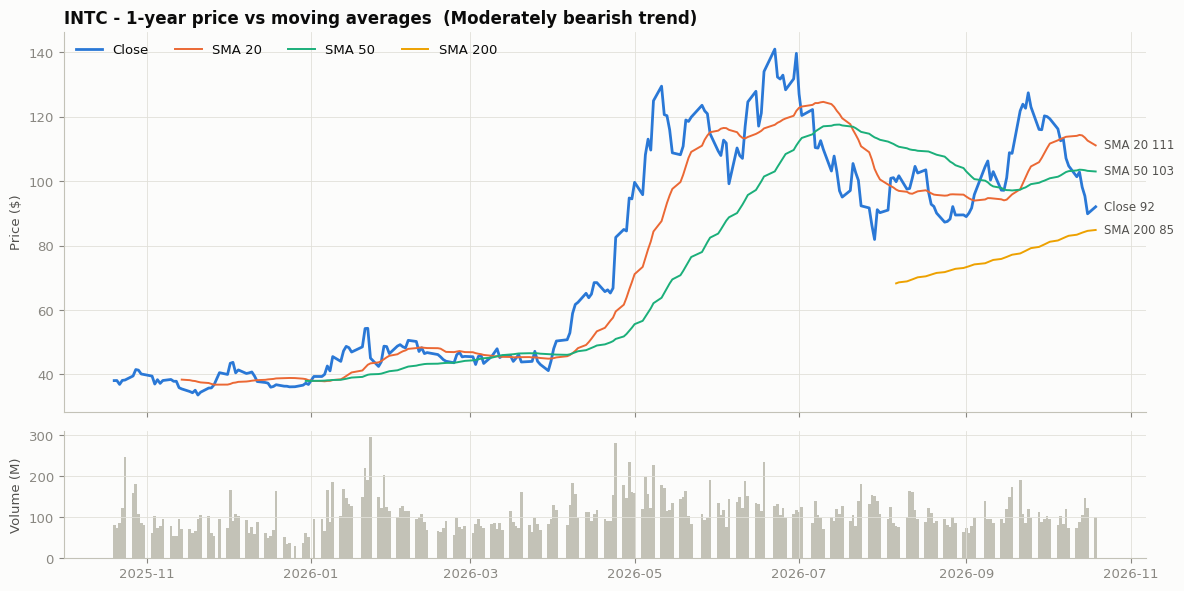

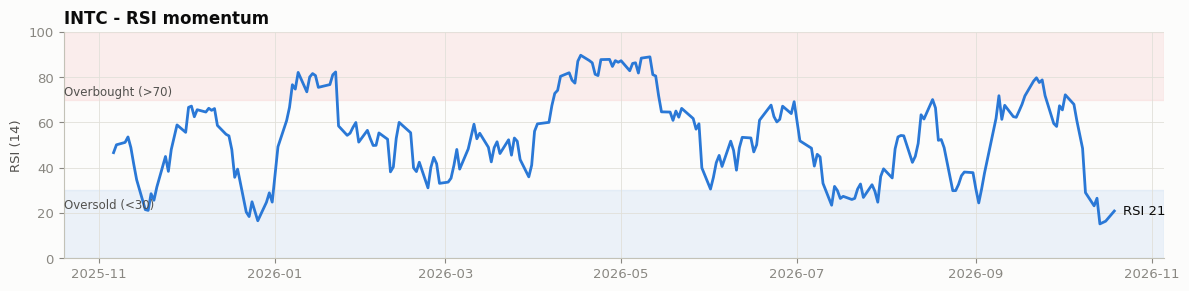

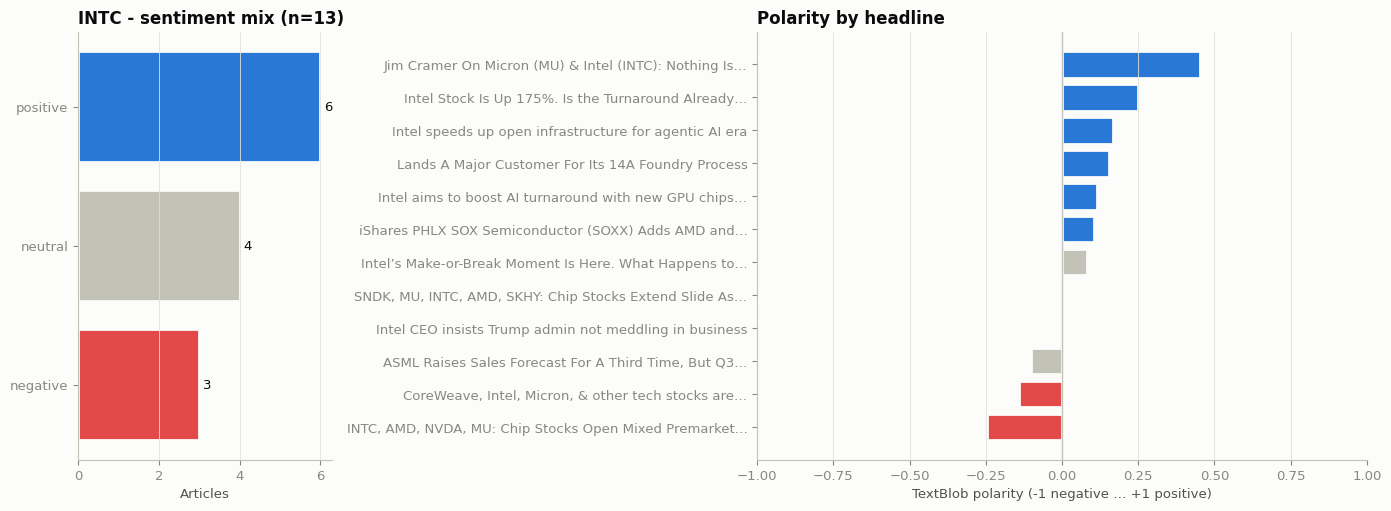

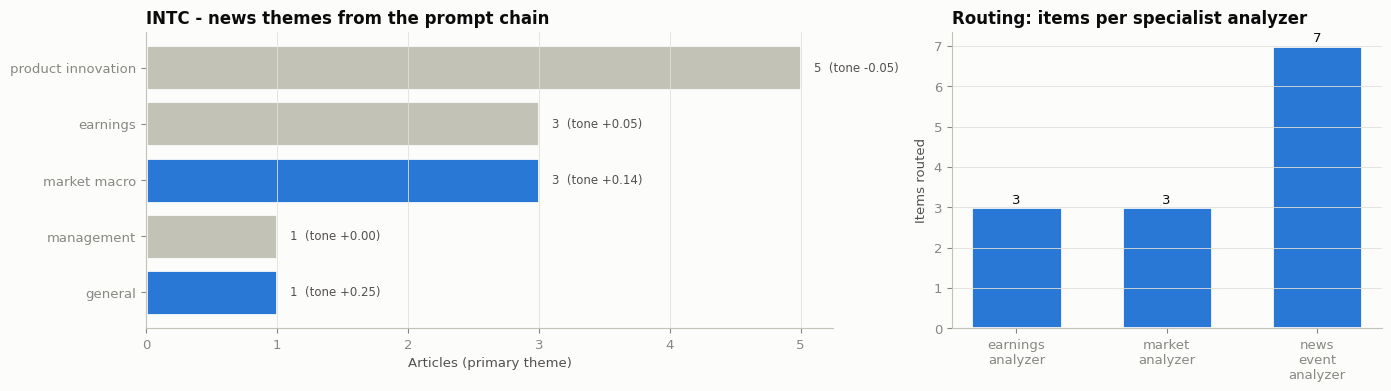

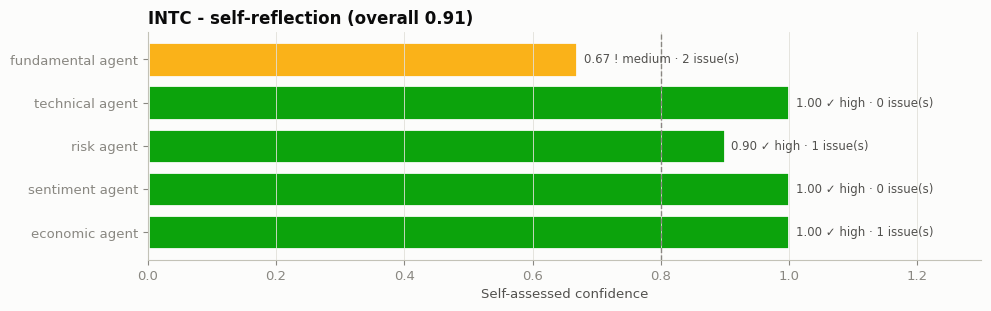

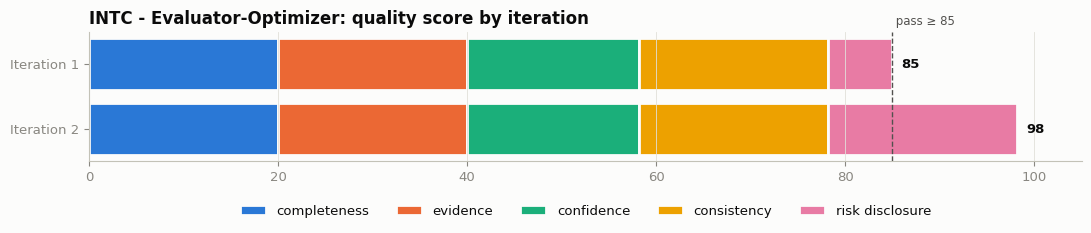

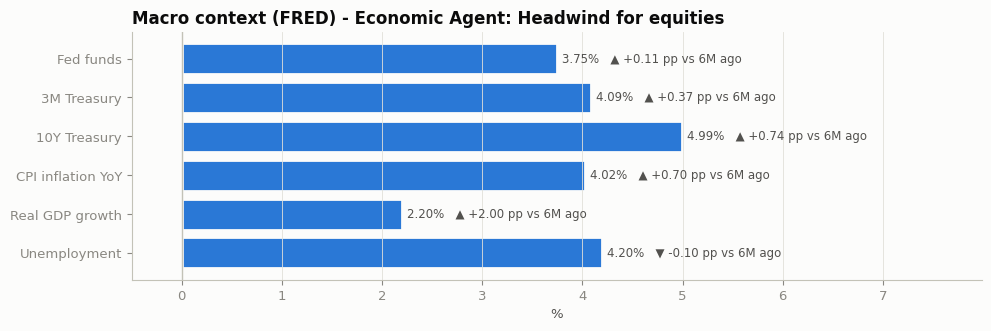

In [0]:
# Charts 1-7 for the run above
plot_dashboard(result_main)

### 8.2 Learning across runs

The same symbol is analysed again. Before planning, the agent reads the lessons it saved in the previous run, and the plan printout lists the adaptations under "Adaptations learned from memory". Typical effects:

* **News window**: the second run starts with the window that the optimizer had to reach last time.
* **News providers**: if one provider was not enough, both are merged from the start.
* **Report fixes**: risk disclosure, caveats and signal reconciliation that the optimizer added last time are now included in the first draft.

As a result, the first-draft score of the second run should be higher and it should need fewer evaluator iterations. The table below compares the two runs.

In [0]:
result_repeat = agent.run(demo_symbol)

comparison = pd.DataFrame(
    [result_main['summary'], result_repeat['summary']],
    index=['Run 1 (no prior memory for this symbol)', 'Run 2 (uses lessons from run 1)'],
)[['initial_score', 'final_score', 'iterations', 'news_days_back', 'news_sources',
   'relevant_articles', 'overall_confidence', 'seconds']]
print("\nLessons carried into run 2:")
for adaptation in result_repeat['plan']['lessons_applied']:
    print("  •", adaptation)
display(comparison.reset_index().rename(columns={'index': 'run'}))


🤖 INVESTMENT RESEARCH AGENT - INTC
🧭 RESEARCH PLAN for INTC (Intel Corporation, sector: Technology)
  1. price_history  -> yahoo_price_history  params={'period': '1y'}  | Daily OHLCV needed for trend, RSI and charts
  2. technicals     -> yahoo_technicals  params={}  | Moving averages, RSI, volatility and beta
  3. fundamentals   -> yahoo_fundamentals  params={}  | Valuation, profitability and leverage ratios
  4. news           -> newsapi_headlines (fallback: yahoo_news)  params={'days_back': 7, 'company_name': 'Intel Corporation'}  | Headlines for sentiment, themes and events
  5. economic       -> fred_economic  params={}  | Rates, inflation, growth and employment context
  Focus metrics for this sector: revenue_growth, pe_ratio, ps_ratio, rsi
  Adaptations learned from memory:
    • Optimizer needed ['add_risk_disclosure'] last run -> applied before first evaluation

⚙️  Executing plan (dynamic tool use)
   ✅ price_history  via yahoo_price_history  ok
   ✅ technicals     via yahoo

run,initial_score,final_score,iterations,news_days_back,news_sources,relevant_articles,overall_confidence,seconds
Run 1 (no prior memory for this symbol),84.9,98.2,2,7,List(NewsAPI),13,0.91,9.4
Run 2 (uses lessons from run 1),98.2,98.2,1,7,List(NewsAPI),13,0.91,1.1


### 8.3 Multi-stock comparison and memory history

The agent runs on several more symbols. Tool reliability is learned **across symbols**: if NewsAPI or FRED fails repeatedly, later plans demote that tool. The last two charts compare risk and valuation across the stocks and show draft vs. final quality for every run stored in memory.


🤖 INVESTMENT RESEARCH AGENT - MSFT
🧭 RESEARCH PLAN for MSFT (Microsoft Corporation, sector: Technology)
  1. price_history  -> yahoo_price_history  params={'period': '1y'}  | Daily OHLCV needed for trend, RSI and charts
  2. technicals     -> yahoo_technicals  params={}  | Moving averages, RSI, volatility and beta
  3. fundamentals   -> yahoo_fundamentals  params={}  | Valuation, profitability and leverage ratios
  4. news           -> newsapi_headlines (fallback: yahoo_news)  params={'days_back': 7, 'company_name': 'Microsoft Corporation'}  | Headlines for sentiment, themes and events
  5. economic       -> fred_economic  params={}  | Rates, inflation, growth and employment context
  Focus metrics for this sector: revenue_growth, pe_ratio, ps_ratio, rsi
  No prior lessons for this symbol (first run or clean history).

⚙️  Executing plan (dynamic tool use)
   ✅ price_history  via yahoo_price_history  ok
   ✅ technicals     via yahoo_technicals     ok
   ✅ fundamentals   via yahoo_fund

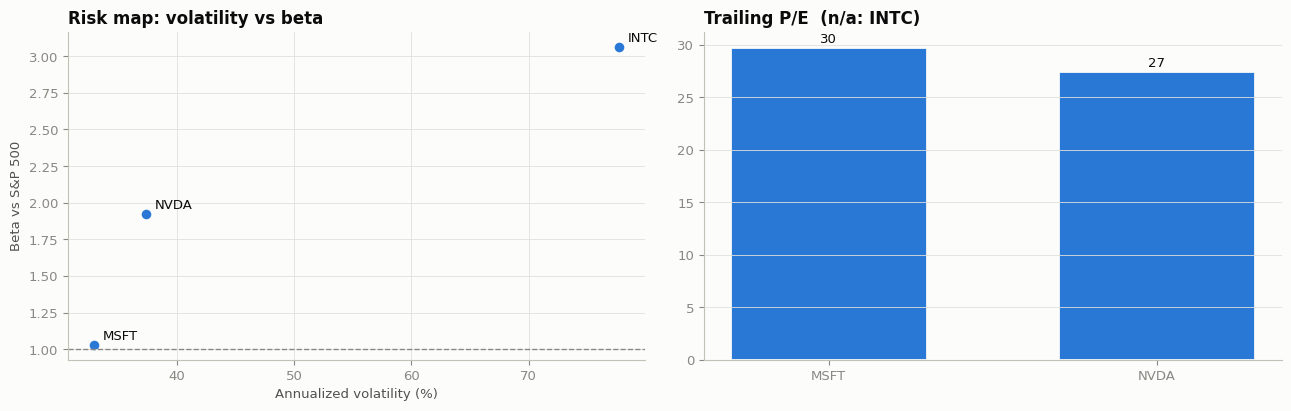

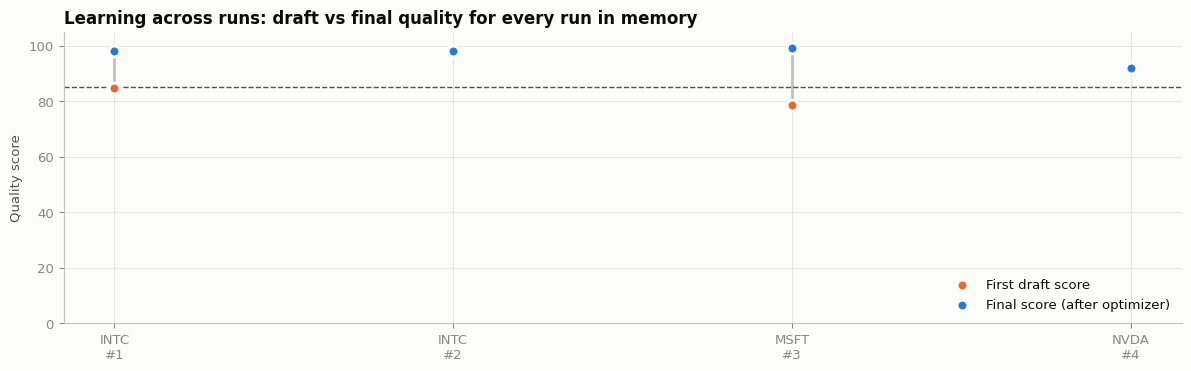

Tool reliability learned so far:
  company_profile      100%  (4 ok / 0 failed)
  yahoo_price_history  100%  (4 ok / 0 failed)
  yahoo_technicals     100%  (4 ok / 0 failed)
  yahoo_fundamentals   100%  (4 ok / 0 failed)
  newsapi_headlines    100%  (4 ok / 0 failed)
  fred_economic        100%  (4 ok / 0 failed)


symbol,timestamp,initial_score,final_score,iterations,overall_sentiment,trend,overall_confidence
INTC,2026-10-19T21:11:40.428435,84.9,98.2,2,Neutral,Moderately bearish trend,0.91
INTC,2026-10-19T21:11:43.078215,98.2,98.2,1,Neutral,Moderately bearish trend,0.91
MSFT,2026-10-19T21:11:44.691995,78.7,99.0,2,Positive,Strong bullish trend,0.95
NVDA,2026-10-19T21:11:45.464391,92.0,92.0,1,Positive,Moderately bearish trend,0.95


In [0]:
peer_symbols = [s for s in ['MSFT', 'NVDA', 'INTC'] if s != demo_symbol]
peer_results = [result_repeat] + [agent.run(s) for s in peer_symbols]

plot_peer_comparison(peer_results)
plot_memory_learning(agent.memory)

print("Tool reliability learned so far:")
for tool, stats in agent.memory.store['tool_stats'].items():
    print(f"  {tool:<20} {agent.memory.tool_reliability(tool):.0%}  ({stats['success']} ok / {stats['failure']} failed)")

display(agent.memory.history_frame()[['symbol', 'timestamp', 'initial_score', 'final_score', 'iterations',
                                      'overall_sentiment', 'trend', 'overall_confidence']].tail(10))

---
## 9 - System Evaluation

This section evaluates the **system as a whole**. It complements the per-run evaluator from Section 5.3, which only scores one analysis at a time inside the evaluator-optimizer loop. It answers three questions:

| Part | Question | Method | Needs live APIs? |
|---|---|---|---|
| **9.1 Agent validation** | Does each agent and workflow component produce the *correct* output for known inputs? | Synthetic test cases with expected outputs for every specialist agent, the prompt chain, the router, self-reflection, the evaluator, tool handling and memory-based planning → pass/fail table | No (one test reuses the Section 8 run) |
| **9.2 Performance metrics** | How well does the system perform across all runs? | Latency vs. the 30-second target in the project plan, tool success rates, draft vs. final quality score (optimizer lift), pass rate, confidence, and news coverage | No (uses stored runs) |
| **9.3 Sentiment accuracy** | How accurate is the NLP sentiment component? | Labeled financial headlines → accuracy, per-class precision/recall, confusion matrix | No |

Together with the per-run evaluator-optimizer scores (chart 6) and the learning comparison (Section 8.2), this covers both the **quality of each output** and the **reliability of the system** that produced it.

### 9.1 Agent Validation Tests

Each test feeds a component a hand-built input whose correct answer is known in advance, then compares the actual output with the expected one. The tests use no external API, so they are deterministic and repeatable. Memory and planner tests use a temporary memory file, so the agent's real memory is not polluted.

In [0]:
import copy

# ---------------------------------------------------------------------
# Synthetic inputs
# ---------------------------------------------------------------------
def make_econ(cpi, cpi_prev, unemp, unemp_chg, fed, fed_chg, ten_y, three_m, gdp):
    return {'indicators': {
        'cpi_inflation': {'latest_value': 300.0, 'yoy_pct': cpi, 'yoy_pct_6m_ago': cpi_prev},
        'unemployment': {'latest_value': unemp, 'change_6m': unemp_chg},
        'federal_funds_rate': {'latest_value': fed, 'change_6m': fed_chg},
        'treasury_10y': {'latest_value': ten_y, 'change_6m': 0.0},
        'treasury_3m': {'latest_value': three_m, 'change_6m': 0.0},
        'gdp_growth': {'latest_value': gdp, 'change_6m': 0.0},
    }}

HEADWIND_ECON = make_econ(cpi=3.6, cpi_prev=3.1, unemp=4.6, unemp_chg=0.4, fed=5.25, fed_chg=0.5,
                          ten_y=3.8, three_m=4.5, gdp=0.6)
TAILWIND_ECON = make_econ(cpi=2.4, cpi_prev=3.0, unemp=4.0, unemp_chg=0.0, fed=3.5, fed_chg=-0.5,
                          ten_y=3.9, three_m=3.5, gdp=2.8)

def article(title, desc=''):
    return {'title': title, 'description': desc, 'url': '', 'published_at': '', 'source': 'test',
            'sentiment': {'polarity': 0, 'subjectivity': 0, 'label': 'neutral'}}

chain = NewsProcessingChain()
test_articles = [
    article('Apple beats quarterly earnings estimates, revenue up 8%'),
    article('Apple beats quarterly earnings estimates, revenue up 8%'),      # duplicate
    article('[Removed]'),                                                    # removed story
    article('Regulators open antitrust probe into Apple'),
    article('Oil prices climb as OPEC trims output'),                        # irrelevant to AAPL
]
cleaned = chain.preprocess(test_articles, 'AAPL', 'Apple Inc.')
classified = chain.classify(cleaned)
extracted = chain.extract(classified)
routing = ContentRouter().route(copy.deepcopy(classified), {})

# Temporary memory for learning / tool tests
test_memory_path = 'investment_data/_test_memory.json'
if os.path.exists(test_memory_path):
    os.remove(test_memory_path)
test_memory = AgentMemory(test_memory_path)
test_memory.record_run('TEST', {'news_days_back': 7, 'final_score': 60},
                       [{'code': 'LOW_NEWS_COVERAGE', 'note': '2 relevant articles'},
                        {'code': 'OPTIMIZER_ACTIONS', 'note': 'expand_news, add_risk_disclosure'}])
learned_plan = ResearchPlanner(test_memory, APIConfig()).create_plan(
    'TEST', {'short_name': 'Test Co', 'quote_type': 'EQUITY', 'sector': 'Technology'})
etf_plan = ResearchPlanner(test_memory, APIConfig()).create_plan('SPY', {'short_name': 'SPDR', 'quote_type': 'ETF'})

test_tools = ToolRegistry(InvestmentResearchPlatform(), test_memory)
def _failing_tool(symbol, **_):
    raise RuntimeError(f"Connection failed for https://example.com/v2?q={symbol}&apiKey=SECRET123")
test_tools.tools['failing_tool'] = _failing_tool
test_tools.call('failing_tool', 'TEST')

reflection_input = {
    'fundamental_agent': FundamentalAgent().analyze({'pe_ratio': None, 'roe': 0.2, 'debt_to_equity': 40}),
    'sentiment_agent': SentimentAgent().analyze({'average_sentiment': 0.3, 'articles_count': 2}),
    'technical_agent': TechnicalAgent().analyze({'current_price': 90, 'rsi': 25, 'sma_20': 85,
                                                 'sma_50': 80, 'sma_200': 70}),
}
reflection_out = SelfReflection().reflect(reflection_input, {'fundamentals': {}})

# ---------------------------------------------------------------------
# Test cases: (component, description, actual, expected)
# ---------------------------------------------------------------------
tech, fund, risk, sent, econ = TechnicalAgent(), FundamentalAgent(), RiskAgent(), SentimentAgent(), EconomicAgent()
bull = {'current_price': 110, 'rsi': 55, 'sma_20': 105, 'sma_50': 100, 'sma_200': 90}
headwind = econ.analyze(HEADWIND_ECON, {'beta': 1.5, 'trend': 'Strong bullish trend'}, {'pe_ratio': 40}, 'Technology')
tailwind = econ.analyze(TAILWIND_ECON, {'beta': 1.0, 'trend': 'Strong bullish trend'}, {'pe_ratio': 20}, 'Technology')

tests = [
    ('TechnicalAgent', 'RSI 75 -> Overbought', tech.analyze({'rsi': 75})['rsi_signal'], 'Overbought'),
    ('TechnicalAgent', 'RSI 25 -> Oversold', tech.analyze({'rsi': 25})['rsi_signal'], 'Oversold'),
    ('TechnicalAgent', 'Missing RSI handled', tech.analyze({'rsi': np.nan})['rsi_signal'], 'RSI unavailable'),
    ('TechnicalAgent', 'Price > SMA20 > SMA50 > SMA200 -> strong bullish', tech.analyze(bull)['trend'], 'Strong bullish trend'),
    ('FundamentalAgent', 'P/E 15 -> low valuation', fund.analyze({'pe_ratio': 15})['pe_analysis'], 'Relatively low valuation'),
    ('FundamentalAgent', 'Missing P/E handled', fund.analyze({'pe_ratio': None})['pe_analysis'], 'P/E ratio unavailable'),
    ('FundamentalAgent', 'ROE -10% -> negative', fund.analyze({'roe': -0.1})['roe_analysis'], 'Negative return on equity'),
    ('FundamentalAgent', 'D/E 150 -> high debt', fund.analyze({'debt_to_equity': 150})['debt_analysis'], 'Relatively high debt level'),
    ('RiskAgent', 'Volatility 50% -> High', risk.analyze({'volatility': 0.5})['volatility_risk'], 'High'),
    ('RiskAgent', 'Beta 1.5 -> higher sensitivity', risk.analyze({'beta': 1.5})['beta_analysis'], 'Higher sensitivity than the market'),
    ('SentimentAgent', 'Avg polarity 0.3 -> Positive', sent.analyze({'average_sentiment': 0.3})['overall_sentiment'], 'Positive'),
    ('EconomicAgent', 'CPI 3.1% -> 3.6% = rising', headwind['inflation_trend'].startswith('Inflation rising'), True),
    ('EconomicAgent', 'Unemployment +0.4pp = loosening', headwind['labor_market'].startswith('Loosening'), True),
    ('EconomicAgent', '10Y < 3M = inverted curve', headwind['yield_curve'].startswith('Inverted'), True),
    ('EconomicAgent', 'Hawkish bundle -> Headwind', headwind['macro_regime'], 'Headwind'),
    ('EconomicAgent', 'Headwind + high P/E + beta 1.5 -> risk elevated', headwind['macro_risk_adjustment'], 'Elevated'),
    ('EconomicAgent', 'Headwind + bullish trend -> momentum not confirmed', 'NOT confirm' in headwind['momentum_alignment'], True),
    ('EconomicAgent', 'Easing/disinflation bundle -> Tailwind', tailwind['macro_regime'], 'Tailwind'),
    ('PromptChain', 'Preprocess drops duplicate, [Removed] and irrelevant stories', len(cleaned), 2),
    ('PromptChain', 'Earnings headline classified as earnings', classified[0]['primary_theme'], 'earnings'),
    ('PromptChain', 'Antitrust headline classified as legal/regulatory', classified[1]['primary_theme'], 'legal_regulatory'),
    ('PromptChain', 'Extract finds the 8% figure', '8%' in [f['figure'] for f in extracted['figures']], True),
    ('ContentRouter', 'Earnings story -> earnings_analyzer', routing['routing_table']['earnings_analyzer'], 1),
    ('ContentRouter', 'Legal story -> news_event_analyzer', routing['routing_table']['news_event_analyzer'], 1),
    ('SelfReflection', 'Missing P/E lowers fundamental confidence', reflection_out['agents']['fundamental_agent']['confidence'] < 1, True),
    ('SelfReflection', '2 articles flagged as small sample', any('Small news sample' in i for i in reflection_out['agents']['sentiment_agent']['issues']), True),
    ('SelfReflection', 'Oversold RSI in uptrend flagged as conflict', any(i.startswith('RSI is oversold') for i in reflection_out['agents']['technical_agent']['issues']), True),
    ('ToolRegistry', 'All-empty Yahoo result is not a success', ToolRegistry._is_success({'symbol': 'X', 'pe_ratio': None, 'roe': None}), False),
    ('ToolRegistry', 'Failed call is logged as failure', test_tools.call_log[-1]['success'], False),
    ('ToolRegistry', 'API key redacted from error log', 'SECRET123' in test_tools.call_log[-1]['error'], False),
    ('Planner+Memory', 'LOW_NEWS_COVERAGE lesson doubles news window', next(s for s in learned_plan['steps'] if s['step'] == 'news')['params']['days_back'], 14),
    ('Planner+Memory', 'Optimizer lesson pre-applied to next draft', learned_plan['pre_apply'], ['add_risk_disclosure']),
    ('Planner', 'ETF plan skips company fundamentals', any(s['step'] == 'fundamentals' for s in etf_plan['steps']), False),
]

# Evaluator test reuses the Section 8 run: stripping the risk section must cost points and trigger a fix.
if 'result_main' in globals():
    weak = copy.deepcopy({k: v for k, v in result_main['analysis'].items() if k != 'stock_data'})
    weak['stock_data'] = result_main['stock_data']
    weak.update({'risks': [], 'caveats': [], 'attempted_actions': []})
    weak_eval = AnalysisEvaluator().evaluate(weak)
    tests += [('Evaluator', 'Empty risk section scores 0/20', weak_eval['breakdown']['risk_disclosure'], 0),
              ('Evaluator', 'Empty risk section triggers add_risk_disclosure', 'add_risk_disclosure' in weak_eval['actions'], True)]

validation = pd.DataFrame(tests, columns=['component', 'test', 'actual', 'expected'])
validation['passed'] = [a == e for a, e in zip(validation['actual'], validation['expected'])]
os.remove(test_memory_path)

print(f"Agent validation: {validation['passed'].sum()}/{len(validation)} tests passed "
      f"({validation['passed'].mean():.0%})")
display(validation.groupby('component')['passed'].agg(['sum', 'count']).rename(columns={'sum': 'passed', 'count': 'tests'}).reset_index())
display(validation)

Agent validation: 35/35 tests passed (100%)


component,passed,tests
ContentRouter,2,2
EconomicAgent,7,7
Evaluator,2,2
FundamentalAgent,4,4
Planner,1,1
Planner+Memory,2,2
PromptChain,4,4
RiskAgent,2,2
SelfReflection,3,3
SentimentAgent,1,1


component,test,actual,expected,passed
TechnicalAgent,RSI 75 -> Overbought,Overbought,Overbought,true
TechnicalAgent,RSI 25 -> Oversold,Oversold,Oversold,true
TechnicalAgent,Missing RSI handled,RSI unavailable,RSI unavailable,true
TechnicalAgent,Price > SMA20 > SMA50 > SMA200 -> strong bullish,Strong bullish trend,Strong bullish trend,true
FundamentalAgent,P/E 15 -> low valuation,Relatively low valuation,Relatively low valuation,true
FundamentalAgent,Missing P/E handled,P/E ratio unavailable,P/E ratio unavailable,true
FundamentalAgent,ROE -10% -> negative,Negative return on equity,Negative return on equity,true
FundamentalAgent,D/E 150 -> high debt,Relatively high debt level,Relatively high debt level,true
RiskAgent,Volatility 50% -> High,High,High,true
RiskAgent,Beta 1.5 -> higher sensitivity,Higher sensitivity than the market,Higher sensitivity than the market,true


### 9.2 Performance Metrics

System-level metrics computed from every run stored in `AgentMemory` and from the Section 8 results:

* **Latency**: seconds per analysis vs. the < 30 s target in the project plan (the first run of a session also includes the one-time FRED download, which is cached afterwards)
* **Tool success rate**: share of successful calls per tool, the reliability statistic the planner learns from
* **Quality**: first-draft vs. final evaluator score, the average **optimizer lift**, and the share of runs that pass the 85-point threshold
* **Confidence and evidence**: average self-reflection confidence (overall and per agent) and relevant news articles per run

metric,value
Runs evaluated,4
Median latency (s),0.9
Runs under 30s,100%
Avg first-draft score,88.45
Avg final score,96.85
Avg optimizer lift (pts),8.4
Pass rate (final >= 85),100%
Avg evaluator iterations,1.5
Avg overall confidence,0.93
Avg relevant articles,15.0


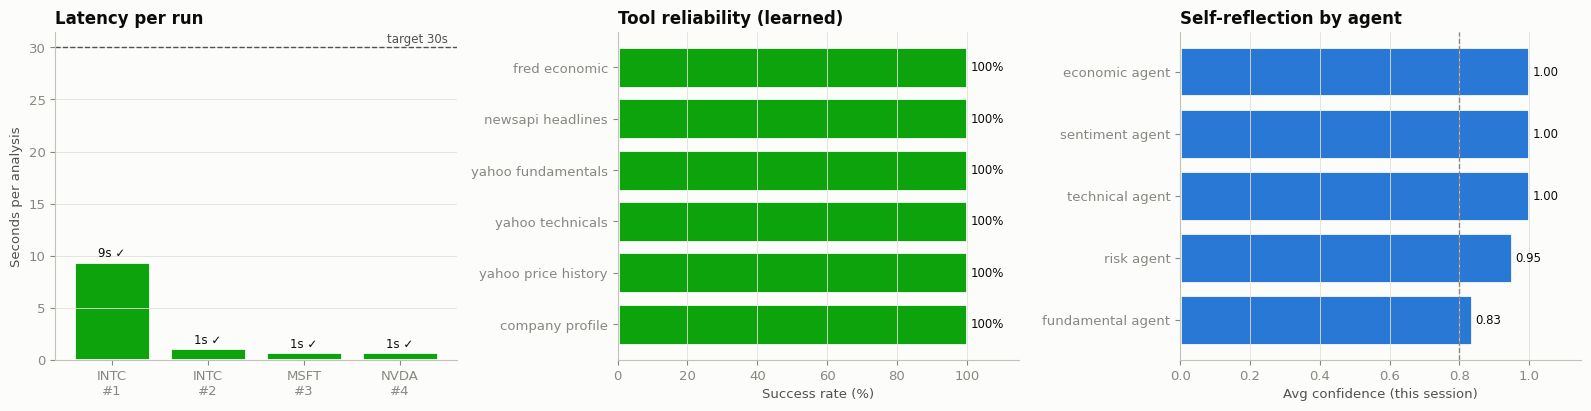

In [0]:
LATENCY_TARGET_S = 30
runs = agent.memory.history_frame()
session_results = [result_main] + peer_results  # peer_results already starts with result_repeat

metrics = {
    'Runs evaluated': len(runs),
    'Median latency (s)': runs['seconds'].median(),
    f'Runs under {LATENCY_TARGET_S}s': f"{(runs['seconds'] < LATENCY_TARGET_S).mean():.0%}",
    'Avg first-draft score': runs['initial_score'].mean(),
    'Avg final score': runs['final_score'].mean(),
    'Avg optimizer lift (pts)': (runs['final_score'] - runs['initial_score']).mean(),
    'Pass rate (final >= 85)': f"{(runs['final_score'] >= 85).mean():.0%}",
    'Avg evaluator iterations': runs['iterations'].mean(),
    'Avg overall confidence': runs['overall_confidence'].mean(),
    'Avg relevant articles': runs['relevant_articles'].mean(),
    'Runs with a tool failure': f"{runs['tool_failures'].apply(len).gt(0).mean():.0%}",
}
metrics_table = pd.DataFrame({'value': [round(v, 2) if isinstance(v, (int, float, np.floating)) else v
                                        for v in metrics.values()]}, index=metrics.keys())
display(metrics_table.reset_index().rename(columns={'index': 'metric'}))

tool_rates = pd.Series({t: agent.memory.tool_reliability(t) for t in agent.memory.store['tool_stats']}).sort_values()
agent_conf = pd.DataFrame([{a: r['analysis']['reflection']['agents'][a]['confidence']
                            for a in r['analysis']['reflection']['agents']} for r in session_results]).mean().sort_values()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.2))
recent = runs.tail(10).reset_index(drop=True)
labels = [f"{s}\n#{i + 1}" for i, s in enumerate(recent['symbol'])]
ax1.bar(labels, recent['seconds'], color=[VIZ['good'] if s < LATENCY_TARGET_S else VIZ['crit'] for s in recent['seconds']],
        edgecolor=VIZ['surface'], linewidth=2)
for i, s in enumerate(recent['seconds']):
    ax1.text(i, s + 0.5, f"{s:.0f}s {'✓' if s < LATENCY_TARGET_S else '✗'}", ha='center', fontsize=8.5)
ax1.axhline(LATENCY_TARGET_S, color=VIZ['ink2'], lw=1, ls='--')
ax1.text(len(recent) - 0.5, LATENCY_TARGET_S + 0.5, f'target {LATENCY_TARGET_S}s', ha='right', color=VIZ['ink2'], fontsize=8.5)
ax1.set_ylabel('Seconds per analysis'); ax1.grid(axis='x', visible=False)
ax1.set_title('Latency per run')

ax2.barh([t.replace('_', ' ') for t in tool_rates.index], tool_rates.values * 100,
         color=[VIZ['good'] if r >= 0.9 else VIZ['warn'] if r >= 0.5 else VIZ['crit'] for r in tool_rates],
         edgecolor=VIZ['surface'], linewidth=2)
for i, r in enumerate(tool_rates):
    ax2.text(r * 100 + 1, i, f"{r:.0%}", va='center', fontsize=8.5)
ax2.set_xlim(0, 115); ax2.set_xlabel('Success rate (%)'); ax2.grid(axis='y', visible=False)
ax2.set_title('Tool reliability (learned)')

ax3.barh([a.replace('_', ' ') for a in agent_conf.index], agent_conf.values, color=VIZ['series'][0],
         edgecolor=VIZ['surface'], linewidth=2)
for i, c in enumerate(agent_conf):
    ax3.text(c + 0.01, i, f"{c:.2f}", va='center', fontsize=8.5)
ax3.axvline(0.8, color=VIZ['muted'], lw=1, ls='--')
ax3.set_xlim(0, 1.15); ax3.set_xlabel('Avg confidence (this session)'); ax3.grid(axis='y', visible=False)
ax3.set_title('Self-reflection by agent')
fig.tight_layout(); plt.show()

### 9.3 Sentiment Accuracy (NLP component)

The sentiment labels that drive the Sentiment Agent, the prompt chain and parts of the risk section come from TextBlob, a general-purpose lexicon. This test measures how well it handles financial language.

* **Default test set**: 20 short financial headlines (7 positive, 7 negative, 6 neutral) written and labeled by the team. Positive/negative follow the usual investor reading: beats, upgrades and buybacks are positive; misses, probes and layoffs are negative; scheduling and administrative news is neutral. Because the set is small and team-labeled, treat the result as indicative only.
* **Optional larger benchmark**: download the Kaggle *Sentiment Analysis for Financial News* dataset (Financial PhraseBank, ~4,800 expert-labeled sentences) and save it as `investment_data/financial_phrasebank.csv`. The cell detects the file automatically and evaluates on a 500-sentence sample instead.

Metrics reported: accuracy, per-class precision and recall, and a confusion matrix. A weak result here is an expected and useful finding: it quantifies the limitation listed in Section 10 and is the main motivation for replacing TextBlob with a finance-tuned model such as FinBERT.

Dataset: Team-labeled headlines (n=20)
TextBlob accuracy: 50%  (majority-class baseline: 35%)


class,precision,recall,support
positive,1.0,0.57,7
neutral,0.38,0.83,6
negative,0.33,0.14,7


text,label,predicted,polarity
Company beats quarterly earnings estimates as revenue jumps 12%,positive,neutral,0.0
Shares surge after firm raises full-year guidance,positive,negative,-0.2
Company announces $10 billion share buyback,positive,neutral,0.0
Shares plunge after company misses earnings and cuts outlook,negative,neutral,0.0
Regulators open antitrust probe into the company,negative,neutral,0.0
Stock downgraded to sell on weakening margins,negative,neutral,0.0
Profit warning sends shares to a 52-week low,negative,neutral,0.0
Company faces lawsuit over customer data breach,negative,neutral,0.0
Revenue declines for the third straight quarter,negative,neutral,0.1
Firm completes previously announced board appointment,neutral,negative,-0.18333333333333335


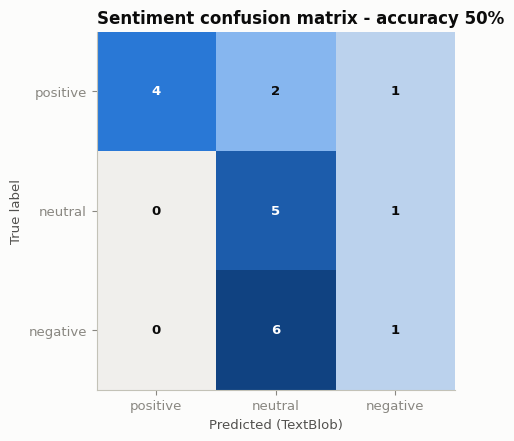

In [0]:
from matplotlib.colors import LinearSegmentedColormap

PHRASEBANK_PATH = 'investment_data/financial_phrasebank.csv'

LABELED_HEADLINES = [
    ("Company beats quarterly earnings estimates as revenue jumps 12%", 'positive'),
    ("Shares surge after firm raises full-year guidance", 'positive'),
    ("Analysts upgrade the stock to buy citing strong demand", 'positive'),
    ("Record iPhone sales lift profit to an all-time high", 'positive'),
    ("Chipmaker wins major contract, boosting its order backlog", 'positive'),
    ("Dividend increased by 10% after strong cash flow", 'positive'),
    ("Company announces $10 billion share buyback", 'positive'),
    ("Shares plunge after company misses earnings and cuts outlook", 'negative'),
    ("Regulators open antitrust probe into the company", 'negative'),
    ("Firm announces 5,000 layoffs amid falling sales", 'negative'),
    ("Stock downgraded to sell on weakening margins", 'negative'),
    ("Profit warning sends shares to a 52-week low", 'negative'),
    ("Company faces lawsuit over customer data breach", 'negative'),
    ("Revenue declines for the third straight quarter", 'negative'),
    ("Company to report third-quarter results on November 2", 'neutral'),
    ("CEO to speak at technology conference next week", 'neutral'),
    ("Firm completes previously announced board appointment", 'neutral'),
    ("Stock trades flat ahead of Federal Reserve meeting", 'neutral'),
    ("Company files quarterly report with the SEC", 'neutral'),
    ("Annual shareholder meeting scheduled for March", 'neutral'),
]

if os.path.exists(PHRASEBANK_PATH):
    # Kaggle file has no header: column 0 = label, column 1 = sentence
    bench = pd.read_csv(PHRASEBANK_PATH, header=None, names=['label', 'text'], encoding='latin-1')
    bench = bench.sample(min(500, len(bench)), random_state=42)
    dataset_name = f'Financial PhraseBank sample (n={len(bench)})'
else:
    bench = pd.DataFrame(LABELED_HEADLINES, columns=['text', 'label'])
    dataset_name = f'Team-labeled headlines (n={len(bench)})'

scorer = NewsDataCollector(APIConfig())
bench['predicted'] = [scorer.analyze_sentiment(t)['label'] for t in bench['text']]
bench['polarity'] = [scorer.analyze_sentiment(t)['polarity'] for t in bench['text']]

classes = ['positive', 'neutral', 'negative']
accuracy = (bench['label'] == bench['predicted']).mean()
per_class = pd.DataFrame({
    'precision': [((bench['predicted'] == c) & (bench['label'] == c)).sum() / max((bench['predicted'] == c).sum(), 1)
                  for c in classes],
    'recall': [((bench['predicted'] == c) & (bench['label'] == c)).sum() / max((bench['label'] == c).sum(), 1)
               for c in classes],
    'support': [(bench['label'] == c).sum() for c in classes],
}, index=classes).round(2)
confusion = pd.crosstab(bench['label'], bench['predicted']).reindex(index=classes, columns=classes, fill_value=0)
majority_baseline = bench['label'].value_counts(normalize=True).max()

print(f"Dataset: {dataset_name}")
print(f"TextBlob accuracy: {accuracy:.0%}  (majority-class baseline: {majority_baseline:.0%})")
display(per_class.reset_index().rename(columns={'index': 'class'}))
display(bench[bench['label'] != bench['predicted']][['text', 'label', 'predicted', 'polarity']].head(10))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(confusion.values, cmap=LinearSegmentedColormap.from_list(
    'blues', ['#f0efec', '#86b6ef', '#2a78d6', '#104281']))
for i in range(len(classes)):
    for j in range(len(classes)):
        v = confusion.values[i, j]
        ax.text(j, i, str(v), ha='center', va='center',
                color='white' if v > confusion.values.max() / 2 else VIZ['ink'], fontweight='bold')
ax.set_xticks(range(3), classes); ax.set_yticks(range(3), classes)
ax.set_xlabel('Predicted (TextBlob)'); ax.set_ylabel('True label'); ax.grid(False)
ax.set_title(f'Sentiment confusion matrix - accuracy {accuracy:.0%}')
fig.tight_layout(); plt.show()

---
## 10 - Key Findings

*Results from the final run on 2026-10-19 (demo symbol: INTC; peers: MSFT, NVDA).*

**1. The agent is reliable and fast.** All 4 autonomous runs completed with 100% tool success (Yahoo Finance, NewsAPI, FRED) and every run met the 30-second target (median 0.9 s; the first run took 9.4 s because it includes the one-time FRED download). All 35 agent validation tests passed.

**2. The evaluator-optimizer measurably improves the reports.** First drafts averaged 88.5/100 and final reports 96.9/100 (+8.4 points), with a 100% pass rate at the 85-point threshold. The most common weakness in first drafts was a thin risk section, followed by unexplained conflicting signals, such as a strong uptrend under a macro headwind.

**3. The agent learns, both within and across symbols.**
* Same symbol: on its second INTC run the agent pre-applied the fix it needed the first time. The first-draft score rose from 84.9 to 98.2, and the run needed 1 evaluator iteration instead of 2.
* Across symbols: after the same fix had been needed on INTC and MSFT, NVDA applied it from the start and passed on the first iteration (92.0). MSFT, which ran before the pattern was established, still needed the optimizer (78.7 → 99.0).

**4. Sentiment is the weakest component.** On the labeled headline set, TextBlob reached 50% accuracy (majority-class baseline: 35%). It detected only 14% of negative headlines because it reads "plunge", "misses" and "downgraded" as neutral. Sentiment is therefore treated as low-weight evidence in the reports, and a finance-tuned model (e.g., FinBERT) is the clearest next improvement.

**5. Example research output: Intel (INTC).**
* **Fundamentals:** revenue growth is strong (+25.4%), but the company is loss-making (net margin −19.8%; P/E undefined).
* **Technicals:** price is below its 20- and 50-day averages (moderately bearish trend), and RSI is 21 (oversold).
* **Risk:** very high volatility (78% annualized) and a beta of 3.07.
* **Macro (Economic Agent):** *headwind* regime, with inflation rising to 4.0% and the 10-year Treasury at 4.99%. Its effect on INTC is *elevated* risk: technology is a rate-sensitive sector, and the high beta amplifies market moves. The macro picture *reinforces* the bearish momentum.
* **Overall:** INTC is a high-risk turnaround story in a pressured sector. The oversold reading may attract short-term buyers, but the fundamentals and macro backdrop argue for a smaller position or waiting for confirmation.

---
## 11 - Requirements Checklist & Limitations

| Requirement | Implemented by | Shown in |
|---|---|---|
| Agent plans its research steps | `ResearchPlanner` | "RESEARCH PLAN" printout, report section 8 |
| Agent uses tools dynamically | `ToolRegistry`, `InvestmentResearchAgent.execute_step` (fallbacks, merging), optimizer re-calls | "Executing plan" log, tool reliability table |
| Agent self-reflects on output quality | `SelfReflection` | Report section 13, chart 5 |
| Agent learns across runs | `AgentMemory` + planner adaptations | Section 8.2 comparison, chart 8 |
| Prompt Chaining (Ingest → Preprocess → Classify → Extract → Summarize) | `NewsProcessingChain` | Chain log line, report section 9, charts 3-4 |
| Routing to specialists | `MacroAwareCoordinator` (by data type, incl. Economic Agent) + `ContentRouter` (by content: earnings / market / news analyzers) | Report sections 10-11, charts 4 and 7 |
| Macro / economic context | `EconomicAgent`: inflation trend, labor market, rates and yield curve, growth, equity headwind/tailwind, stock risk, momentum alignment, sector allocation | Report section 11, chart 7 |
| Evaluator–Optimizer (generate → evaluate → refine) | `AnalysisEvaluator` + `AnalysisOptimizer` | Evaluator log, report section 14, chart 6 |
| System evaluation | Agent validation tests, performance metrics, sentiment accuracy | Section 9 (pass/fail table, metrics table, latency/tool/confidence charts, confusion matrix) |
| Data sources | Yahoo Finance (prices, fundamentals, profile, news), NewsAPI, FRED | Report section 7 |

**Limitations and next steps**
* Sentiment uses TextBlob, a general-purpose lexicon that can misread financial language ("beat", "short"). A finance-tuned model such as FinBERT would be more accurate.
* Theme classification is keyword-based. The summarize step already builds an LLM prompt, so passing `llm_summarizer=` (e.g., a Databricks Foundation Model endpoint) to `InvestmentResearchAgent` would upgrade the summary without other code changes.
* The free NewsAPI tier limits history (about 30 days) and request volume, and Yahoo Finance data is unofficial.
* This system is research support, not investment advice.

####**Contributions**

**Lashana Narayan**
- Data collection platform (Section 2): Yahoo Finance, NewsAPI and FRED integrations; the fundamental, technical, news and economic collectors; the platform orchestrator; structured JSON output
- Coordinator and reporting (Section 3): CoordinatorAgent routing, ReportSynthesizer, and stock symbol validation with suggestions
- Autonomous agent functions (Section 4):
    - persistent memory (AgentMemory)
    - dynamic tool use with fallbacks (ToolRegistry)
    - research planning (ResearchPlanner)
    - self-reflection confidence scoring
    - the Economic Agent (inflation, labor market, rates, yield curve, growth, equity headwind/tailwind, sector tilt)
- Workflow patterns (Section 5):
    - prompt chain: Ingest → Preprocess → Classify → Extract → Summarize
    - content router to earnings, market and news analyzers
    - evaluator-optimizer loop
- Integrated agent (Section 6): InvestmentResearchAgent and the extended 14-section report
- Visualizations (Section 7): 9 workflow and analysis charts
- Demonstration and evaluation (Sections 8–9): single-stock, learning and multi-stock demos; 35 agent validation tests; performance metrics; sentiment accuracy benchmark
- Documentation: notebook structure and markdown explanations

**Nik**
- Fundamental Agent: Analyze P/E ratios, ROE, debt levels
- Technical Agent: Process RSI, moving averages, trends
- Sentiment Agent: Evaluate news sentiment scores
- Risk Agent: Calculate volatility and beta metrics (nice to have)

**Nathan**
- Agent communication and coordination
- Workflow patterns (chaining, routing, evaluation)
- Evaluation and documentation

#### **AI-assisted tool use: **

Sections 4–9 were developed with assistance from an AI coding assistant; the team designed, reviewed, ran and validated the work.